# Group 27 - Amazing Creative Desk Coworking (ACDC): Exploratory Data Analysis

**Data Mining 2026/27 - Deliverable 1.** Group 27: Martim, Maria, Matilde.

This notebook prepares the customer segmentation of ACDC: it assesses the quality of the data, describes the members, looks for behavioural signals and builds the features for clustering.

| Part | Sections | Content | Author |
|---|---|---|---|
| **1. Data quality and cleaning** | 1 to 11 | Quality checks, cleaning decisions and `clean_data()` | Martim |
| **2. Member profile** | 12 to 18 | Demographics, plans, time trends and relations between variables | Maria |
| **3. Behaviour, value and features** | 19 to 24 | Usage, add-ons, value, engineered features and possible groups | Matilde |
| **4. Bonus: anomaly detection** | 25 | Multidimensional outliers and their effect on clustering | Martim |

**To run it:** The `data` folder containing `acdc_dataset.csv` must be located in the parent directory alongside this notebook. Section 10 exports the cleaned dataset as `data/acdc_clean.csv`, which serves as the direct input for all subsequent parts.

**Methodology & Workflow:** Our pipeline follows a structured, iterative approach: first exploratory analysis (Sections 4 to 6), followed by rigorous data cleaning and decision-making (Sections 7 to 9), with every transformation backed by empirical justification. While standard data manipulation, visualization, and preprocessing techniques are applied throughout, specific custom treatments are implemented where necessary—such as robust date parsing, string sanitization in `lifetime_value`, distributional checks (`.skew()`), binning (`pd.cut()`, `pd.qcut()`), ranking methods, and advanced bonus pipelines.

# Part 1: Data quality and cleaning

## 1. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from matplotlib.colors import LinearSegmentedColormap

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.impute import KNNImputer
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# For better resolution plots
%config InlineBackend.figure_format = 'retina'

sns.set_theme(style="whitegrid")

## 2. Reading the Data

The file uses `;` as separator (opening it with the default `,` puts everything in one column).

In [2]:
# The data folder sits right next to the notebooks folder
data_path = os.path.join("..", "data", "acdc_dataset.csv")
clean_path = os.path.join("..", "data", "acdc_clean.csv")

df = pd.read_csv(data_path, sep=";")

# We keep an untouched copy so we can always compare "before vs after"
df_original = df.copy()

## 3. Metadata

- *member_id* – Unique identifier of each member
- *age* – Age of the member at the extraction date
- *gender* – Gender of the member
- *country* – Country where the member (or their company) is based
- *industry* – Industry sector the member works in
- *is_team_account* – Whether the membership is held by a team/company account
- *n_colleagues_on_account* – Number of colleagues sharing the account
- *plan_tier* – Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)
- *plan_days_per_week* – Days per week the plan entitles the member to use the space
- *membership_start* / *membership_end* – Dates the membership began / first ended
- *last_badge_swipe* – Date of the most recent physical entry
- *days_since_last_visit* – Days since the last recorded visit
- *total_visits* – Total visits over the whole membership
- *avg_weekly_visits* – Average visits per week over the membership
- *entitled_visits_last_period* / *actual_visits_last_period* – Visits entitled / made in the last period
- *meeting_room_hours* / *event_space_hours* – Hours of meeting-room / event-space usage
- *guest_passes_issued* – Number of guest passes issued
- *uses_\** – Whether the member used each add-on (meeting rooms, event space, guest passes, print,
  mail handling, phone booths, day passes, storage, bike locker)
- *n_renewals* – Number of times the membership was renewed
- *lifetime_value* – Total revenue attributed to the member

## 4. Initial Analysis

In [3]:
df.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [4]:
df.shape

(15465, 31)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

Comparing the data types with the metadata, three things already look wrong:
- `lifetime_value` should be a number but is stored as `object` (text).
- `uses_print` is stored as 0/1 while all the other `uses_*` add-on flags are True/False.
- The three date columns are stored as text.

In [6]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


In [7]:
df.describe(exclude=["number", "bool"]).T

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


### Feature groups

To ensure each attribute receives the correct transformation and statistical treatment, we categorize the dataset's variables into distinct logical groups.

In [8]:
id_feature = "member_id"

date_features = ["membership_start", "membership_end", "last_badge_swipe"]

non_metric_features = ["gender", "country", "industry", "plan_tier"]

bool_features = ["is_team_account",
                 "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
                 "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage",
                 "uses_bike_locker"]

# lifetime_value is listed here because it is numeric by nature, it is converted from text in section 5.3
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
                   "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
                   "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
                   "guest_passes_issued", "n_renewals", "lifetime_value"]

# Quick sanity check to make sure we didn't leave anything out or double-count any columns
all_groups = [id_feature] + date_features + non_metric_features + bool_features + metric_features
print("Columns not assigned:", set(df.columns) - set(all_groups))
print("Columns assigned twice:", len(all_groups) - len(set(all_groups)))

Columns not assigned: set()
Columns assigned twice: 0


## 5. Data Quality Checks

### 5.1 Duplicates

In [9]:
# Fully duplicated rows
df.duplicated().sum()

np.int64(15)

In [10]:
# Duplicated member ids (each member should appear only once)
df[id_feature].duplicated().sum()

np.int64(15)

In [11]:
# Check whether rows with duplicate member IDs are exact copies or distinct records
dup_ids = df.loc[df[id_feature].duplicated(), id_feature]
df.loc[df[id_feature].isin(dup_ids)].sort_values(id_feature).head(6)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14


In [12]:
# They are exact copies (probably the same record loaded twice), so we simply drop them
df.drop_duplicates(inplace=True)
print("Rows after dropping duplicates:", df.shape[0])
print("Remaining duplicated ids:", df[id_feature].duplicated().sum())

Rows after dropping duplicates: 15450
Remaining duplicated ids: 0


### 5.2 Missing Values

In [13]:
# Empty strings are missing values too, then we count NaNs per column
df.replace("", np.nan, inplace=True)

missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
missing.loc[missing["n_missing"] > 0].sort_values("n_missing", ascending=False)

,n_missing,pct_missing
meeting_room_hours,1295,8.38
guest_passes_issued,1269,8.21
lifetime_value,1040,6.73
age,557,3.61
gender,530,3.43
country,429,2.78
plan_tier,105,0.68


In [14]:
print("Rows with any missing value:", df.isna().any(axis=1).sum(),
      f"({df.isna().any(axis=1).mean() * 100:.1f}% of rows)")

Rows with any missing value: 4364 (28.2% of rows)


Dropping every incomplete row would cost more than a quarter of the data, so we will impute instead.

A question before imputing: are the missing usage values related to the add-on flags? If a member never used
meeting rooms, a missing number of meeting-room hours most likely just means 0.

In [15]:
pd.crosstab(df["meeting_room_hours"].isna(), df["uses_meeting_rooms"])

uses_meeting_rooms,False,True
meeting_room_hours,,
False,9290,4865
True,902,393


In [16]:
pd.crosstab(df["guest_passes_issued"].isna(), df["uses_guest_passes"])

uses_guest_passes,False,True
guest_passes_issued,,
False,11573,2608
True,1066,203


In [17]:
# The counts above depend on how many members use each add-on, so we compare the missing rate of each group
pd.DataFrame({
    "% missing meeting_room_hours": df["meeting_room_hours"].isna().groupby(df["uses_meeting_rooms"]).mean() * 100,
    "% missing guest_passes_issued": df["guest_passes_issued"].isna().groupby(df["uses_guest_passes"]).mean() * 100,
}).round(2).rename_axis("used the add-on")

,% missing meeting_room_hours,% missing guest_passes_issued
used the add-on,,
False,8.85,8.43
True,7.47,7.22


Most missing values belong to members who never used the add-on, but only because most members never use it:
**the missing rate is about the same in both groups**. So the flag does not explain why a value is missing, which is
closer to MCAR than to MAR.

The flag does tell us which value to use (section 7 and 9.1):
- never used the add-on: 0 is the logical value;
- used the add-on: the usage is unknown, so it has to be estimated from the other users.

### 5.3 Data Types

In [18]:
# uses_print is stored as 0/1: check its values before converting
df["uses_print"].value_counts()

uses_print
0    10458
1     4992
Name: count, dtype: int64

In [19]:
# Only 0 and 1 and no missing values, so it becomes a plain True/False column like the other add-on flags
df["uses_print"] = df["uses_print"].astype(bool)
df[bool_features].dtypes

is_team_account       bool
uses_meeting_rooms    bool
uses_event_space      bool
uses_guest_passes     bool
uses_print            bool
uses_mail_handling    bool
uses_phone_booths     bool
uses_day_passes       bool
uses_storage          bool
uses_bike_locker      bool
dtype: object

#### Date Parsing & Format Resolution

The date columns combine two distinct formats: ISO (`YYYY-MM-DD`) and slash-separated (`DD/MM/YYYY` or `MM/DD/YYYY`). Because slash-separated entries introduce ambiguity regarding day and month ordering, we infer the correct layout empirically from the data patterns: by verifying that the first number frequently exceeds 12 while the second never does, we confirm the standard `DD/MM/YYYY` structure and parse the columns explicitly without making manual assumptions.

In [20]:
# In the dates with "/", if the first number is sometimes above 12 it can only be the day (dd/mm/yyyy)
# If the second number were ever above 12, the format would be mm/dd/yyyy instead
for feat in date_features:
    slash_dates = df.loc[df[feat].str.contains("/"), feat]
    first_number = slash_dates.str.split("/").str[0].astype(int)
    second_number = slash_dates.str.split("/").str[1].astype(int)
    print(f"{feat}: {len(slash_dates)} dates with '/' | first number > 12: {(first_number > 12).sum()}"
          f" | second number > 12: {(second_number > 12).sum()}")

membership_start: 637 dates with '/' | first number > 12: 366 | second number > 12: 0
membership_end: 461 dates with '/' | first number > 12: 276 | second number > 12: 0
last_badge_swipe: 637 dates with '/' | first number > 12: 440 | second number > 12: 0


In [21]:
# The first number goes above 12 and the second never does, so the format is dd/mm/yyyy, 
# we parse each format explicitly instead of letting pandas guess, so no date is read the wrong way round
for feat in date_features:
    iso_format = pd.to_datetime(df[feat], format="%Y-%m-%d", errors="coerce")
    day_first_format = pd.to_datetime(df[feat], format="%d/%m/%Y", errors="coerce")
    df[feat] = iso_format.fillna(day_first_format)

# every date must have matched one of the two formats, otherwise it would now be missing
df[date_features].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

In [22]:
df[date_features].describe()

,membership_start,membership_end,last_badge_swipe
count,15450,15450,15450
mean,2022-03-15 18:14:12.815534080,2009-05-25 17:09:15.029126144,2023-02-13 20:05:41.126213632
min,2021-01-01 00:00:00,1970-01-01 00:00:00,2020-09-06 00:00:00
25%,2021-06-02 00:00:00,1970-01-01 00:00:00,2022-08-11 00:00:00
50%,2022-01-06 00:00:00,2022-08-21 00:00:00,2023-05-06 00:00:00
75%,2022-11-03 00:00:00,2023-06-09 00:00:00,2023-10-17 00:00:00
max,2023-12-30 00:00:00,2024-01-01 00:00:00,2024-04-28 00:00:00


The data covers memberships starting between 2021 and 2023, as described in the project guidelines.
Two things to investigate in section 5.6:
- many `membership_end` dates are `1970-01-01`, which is clearly a placeholder;
- some badge swipes happen in 2020 (before any membership started) or in 2024.

#### Lifetime Value Format Pattern Analysis

With over 11,000 distinct raw string entries in `lifetime_value`, we evaluate the underlying structural formats by replacing all numeric digits with a standardized character (`9`). This mask reveals the structural diversity—such as varying decimal positions, thousands separators, negative signs, and currency symbols (`€`)—allowing us to design targeted sanitization rules prior to numeric conversion.

In [23]:
ltv_text = df["lifetime_value"].dropna()
ltv_text.str.replace(r"\d", "9", regex=True).value_counts()

lifetime_value
9999.99         4547
999.99          4412
9               1724
99999.99        1535
999.9            472
9999.9           447
99.99            244
999              208
999.99 €         168
99999.9          130
9,999.99          82
9999.99 €         65
9999              48
99999             46
-999.99           44
99.9              39
99                31
999999            27
99999.99 €        26
-9999.99          25
99,999.99         25
9.99 €            18
9999999           16
99.99 €           14
999999.99          3
-999.9             3
-9999.9            2
-999               2
-99999.99          2
-9999              1
9,999,999.99       1
-99.99             1
-9,999.99          1
-99,999.99         1
Name: count, dtype: int64

In [24]:
# Formats found: plain numbers, numbers followed by " €" and numbers with "," as thousands separator
# The comma is never a decimal separator (the decimals always come after a "."), so we can just remove it
n_missing_before = df["lifetime_value"].isna().sum()

df["lifetime_value"] = (df["lifetime_value"]
                        .str.replace("€", "", regex=False)
                        .str.replace(",", "", regex=False)
                        .str.strip()
                        .astype(float))

print("Missing before:", n_missing_before, "| missing after:", df["lifetime_value"].isna().sum(),
      "-> no value was lost in the conversion")
df["lifetime_value"].describe().round(2)

Missing before: 1040 | missing after: 1040 -> no value was lost in the conversion


count      14410.00
mean        6398.77
std        62789.64
min       -13440.24
25%          252.73
50%          825.12
75%         5057.34
max      3371260.00
Name: lifetime_value, dtype: float64

The conversion worked, but the values themselves look suspicious: negative revenue, a maximum of more than
3 million euros and many zeros. We investigate them in section 5.7.

### 5.4 Inconsistent Categories

Checking the unique values of each categorical feature.

In [25]:
for feat in non_metric_features:
    print(f"--- {feat} ({df[feat].nunique()} unique values) ---")
    print(df[feat].value_counts(dropna=False).to_string(), "\n")

--- gender (12 unique values) ---
gender
Female     7405
Male       6166
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8 

--- country (33 unique values) ---
country
Portugal           9950
United Kingdom     1104
Germany             850
Spain               711
France              506
Netherlands         463
NaN                 429
Other (Europe)      429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
UK                   14
DE                   14
NL                   13
Deutschland          13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
ireland               6
IE        

The same category is written in many ways (capital letters, extra spaces, abbreviations, other languages,
typos like `Portucal`). We map every variant to one standard label with `.replace()`.

In [26]:
gender_map = {
    "female": "Female", "F": "Female", " Female": "Female",
    "male": "Male", "M": "Male", " Male": "Male",
    "other": "Other", " Other": "Other", "O": "Other",
}

country_map = {
    "portugal ": "Portugal", "portugal": "Portugal", "Portucal": "Portugal", "PT": "Portugal",
    "united kingdom": "United Kingdom", "United kingdom": "United Kingdom", "UK": "United Kingdom",
    "U.K.": "United Kingdom", "GB": "United Kingdom",
    "germany": "Germany", "DE": "Germany", "Deutschland": "Germany",
    "spain": "Spain", "ES": "Spain", "Espana": "Spain", "España": "Spain",
    "france": "France", "FR": "France",
    "netherlands": "Netherlands", "NL": "Netherlands", "The Netherlands": "Netherlands",
    "Holland": "Netherlands",
    "ireland": "Ireland", "IE": "Ireland",
    "other (europe)": "Other (Europe)",
}

industry_map = {
    "INFORMATION TECHNOLOGY": "Information Technology", "information technology": "Information Technology",
    "Information technology": "Information Technology", "IT": "Information Technology",
    "Tech": "Information Technology",
    "CONSULTING": "Consulting", "consulting": "Consulting",
    "MARKETING & PR": "Marketing & PR", "marketing & pr": "Marketing & PR", "Marketing & Pr": "Marketing & PR",
    "Marketing/PR": "Marketing & PR", "Marketing and PR": "Marketing & PR",
    "DESIGN & CREATIVE": "Design & Creative", "design & creative": "Design & Creative",
    "Design/Creative": "Design & Creative", "Design and Creative": "Design & Creative",
    "FINANCE": "Finance", "finance": "Finance",
    "LEGAL": "Legal", "legal": "Legal",
    "EDUCATION": "Education", "education": "Education",
    "HEALTH": "Health", "health": "Health",
    "REAL ESTATE": "Real Estate", "real estate": "Real Estate", "RealEstate": "Real Estate",
    "Real-Estate": "Real Estate",
    "OTHER": "Other", "other": "Other",
    "UNKNOWN": "Unknown", "unknown": "Unknown",
}

plan_tier_map = {
    "HOT_DESK": "hot_desk", "Hot Desk": "hot_desk", "hotdesk": "hot_desk",
    "Flex": "flex", "FLEX": "flex",
    "DEDICATED_DESK": "dedicated_desk", "Dedicated Desk": "dedicated_desk", "dedicateddesk": "dedicated_desk",
    "FULL_TIME": "full_time", "Full Time": "full_time", "fulltime": "full_time",
    "PRIVATE_OFFICE": "private_office", "Private Office": "private_office", "privateoffice": "private_office",
}

category_maps = {"gender": gender_map, "country": country_map,
                 "industry": industry_map, "plan_tier": plan_tier_map}

for feat, mapping in category_maps.items():
    df[feat] = df[feat].replace(mapping)

In [27]:
# Check the result: each feature should now only have its standard labels
for feat in non_metric_features:
    print(f"{feat}: {sorted(df[feat].dropna().unique())}")

gender: ['Female', 'Male', 'Other']
country: ['France', 'Germany', 'Ireland', 'Netherlands', 'Other (Europe)', 'Portugal', 'Spain', 'United Kingdom']
industry: ['Consulting', 'Design & Creative', 'Education', 'Finance', 'Health', 'Information Technology', 'Legal', 'Marketing & PR', 'Other', 'Real Estate', 'Unknown']
plan_tier: ['dedicated_desk', 'flex', 'full_time', 'hot_desk', 'private_office']


`industry` keeps an `Unknown` category that comes from the source system itself. We keep it as it is:
it is a real answer ("not declared"), not a gap we created.

### 5.5 Coherence Checks (numeric and categorical)

Rules that every row should respect. First, does `plan_days_per_week` match the plan?

In [28]:
pd.crosstab(df["plan_tier"], df["plan_days_per_week"])

plan_days_per_week,0,2,3,5,7,9
plan_tier,,,,,,
dedicated_desk,3,0,0,1540,0,6
flex,20,0,5407,0,0,22
full_time,5,0,0,2456,0,10
hot_desk,14,5183,0,0,0,15
private_office,1,0,0,0,662,1


Each tier has one clear number of days per week (hot_desk = 2, flex = 3, dedicated_desk = 5,
full_time = 5, private_office = 7). The few rows with 0 or 9 days are errors (a week has 7 days).

In [29]:
tier_days = {"hot_desk": 2, "flex": 3, "dedicated_desk": 5, "full_time": 5, "private_office": 7}


def expected_plan_days(data):
    # days per week each row's plan_tier entitles to (NaN when the tier is missing)
    expected = pd.Series(np.nan, index=data.index)
    for tier, days in tier_days.items():
        expected.loc[data["plan_tier"] == tier] = days
    return expected


expected_days = expected_plan_days(df)

# Each rule is True for the rows that break it
coherence_rules = {
    "age < 18 or age > 100":
        (df["age"] < 18) | (df["age"] > 100),
    "negative n_colleagues_on_account":
        df["n_colleagues_on_account"] < 0,
    "negative total_visits":
        df["total_visits"] < 0,
    "negative meeting_room_hours":
        df["meeting_room_hours"] < 0,
    "negative event_space_hours":
        df["event_space_hours"] < 0,
    "negative guest_passes_issued":
        df["guest_passes_issued"] < 0,
    "negative n_renewals":
        df["n_renewals"] < 0,
    "negative days_since_last_visit":
        df["days_since_last_visit"] < 0,
    "negative lifetime_value":
        df["lifetime_value"] < 0,
    "plan_days_per_week not matching plan_tier":
        df["plan_tier"].notna() & (df["plan_days_per_week"] != expected_days),
    "avg_weekly_visits > 7 (more than one visit per day)":
        df["avg_weekly_visits"] > 7,
    "total_visits > 1095 (more than one visit per day in 3 years)":
        df["total_visits"] > 3 * 365,
    "actual_visits_last_period > entitled_visits_last_period":
        df["actual_visits_last_period"] > df["entitled_visits_last_period"],
    "actual_visits_last_period > total_visits (the last period is part of the total)":
        (df["total_visits"] >= 0) & (df["actual_visits_last_period"] > df["total_visits"]),
    "total_visits = 0 but avg_weekly_visits > 0":
        (df["total_visits"] == 0) & (df["avg_weekly_visits"] > 0),
    "uses_meeting_rooms False but meeting_room_hours > 0":
        (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0),
    "uses_event_space False but event_space_hours > 0":
        (df["uses_event_space"] == False) & (df["event_space_hours"] > 0),
    "uses_guest_passes False but guest_passes_issued > 0":
        (df["uses_guest_passes"] == False) & (df["guest_passes_issued"] > 0),
    "is_team_account False but n_colleagues_on_account > 0":
        (df["is_team_account"] == False) & (df["n_colleagues_on_account"] > 0),
}

coherence = pd.DataFrame({"n_rows": {rule: mask.sum() for rule, mask in coherence_rules.items()}})
coherence["pct_rows"] = (coherence["n_rows"] / df.shape[0] * 100).round(2)
coherence.sort_values("n_rows", ascending=False)

,n_rows,pct_rows
actual_visits_last_period > total_visits (the last period is part of the total),1127,7.29
negative n_colleagues_on_account,565,3.66
age < 18 or age > 100,143,0.93
total_visits = 0 but avg_weekly_visits > 0,109,0.71
plan_days_per_week not matching plan_tier,97,0.63
negative lifetime_value,82,0.53
negative n_renewals,66,0.43
negative days_since_last_visit,56,0.36
uses_meeting_rooms False but meeting_room_hours > 0,55,0.36
avg_weekly_visits > 7 (more than one visit per day),42,0.27


In [30]:
any_rule = pd.concat(coherence_rules.values(), axis=1).any(axis=1)
print("Rows breaking at least one rule:", any_rule.sum(), f"({any_rule.mean() * 100:.1f}%)")

Rows breaking at least one rule: 2136 (13.8%)


In [31]:
# The extreme ages: babies and people older than any human ever recorded
df["age"].value_counts().sort_index()

age
1.0       2
2.0       8
3.0      26
4.0      26
5.0       4
         ..
144.0     2
145.0     1
146.0     2
147.0     1
149.0     1
Name: count, Length: 84, dtype: int64

`n_colleagues_on_account = -1` is one of the most frequent problems. Does it depend on the type of account?

In [32]:
pd.crosstab(df["is_team_account"], df["n_colleagues_on_account"])

n_colleagues_on_account,-1,0,1,2,3,4,5,6,7,8,9
is_team_account,,,,,,,,,,,
False,412,10688,0,0,0,0,0,0,0,0,0
True,153,0,1758,1116,727,381,142,56,14,2,1


Individual accounts never have colleagues (all other values are 0), so on an individual account -1 can only
mean 0. On a team account the real number is unknown (it is at least 1).

Next, `entitled_visits_last_period` should follow from the plan: days per week × weeks in the period.

In [33]:
# Entitled visits / days per week = length of the "last period" in weeks (only rows where days match the tier)
consistent_days = df["plan_days_per_week"] == expected_days
period_weeks = (df["entitled_visits_last_period"] / df["plan_days_per_week"])[consistent_days]
period_weeks.round(1).value_counts().head()

8.7    11879
7.6       94
8.4       91
8.0       89
8.1       77
Name: count, dtype: int64

In [34]:
# The exact length of a full period (the rounded value 8.7 is the most frequent one)
weeks_last_period = period_weeks[period_weeks.round(1) == period_weeks.round(1).mode()[0]].median()

above_entitlement = consistent_days & (
    df["entitled_visits_last_period"] > df["plan_days_per_week"] * weeks_last_period + 0.05)
print("Weeks in a full period:", round(weeks_last_period, 3))
print("Rows (with days matching the tier) above the plan's entitlement:", above_entitlement.sum())

Weeks in a full period: 8.696
Rows (with days matching the tier) above the plan's entitlement: 0


A full period is about 8.7 weeks (two months), and most entitlements are exactly *days × 8.7*. Smaller values
are partial periods (members who joined or left during the period), and no row goes above its plan's entitlement.

That was for rows whose days match the tier. What about the rows with the impossible 0 or 9 days: was their
entitlement calculated with the wrong days too?

In [35]:
ent = "entitled_visits_last_period"
nine_days = df["plan_tier"].notna() & (df["plan_days_per_week"] == 9)
zero_days = df["plan_tier"].notna() & (df["plan_days_per_week"] == 0)

# The most a member can be entitled to: a full period with the tier's days
full_period = expected_days * weeks_last_period
above_full = df[ent] > full_period + 0.05

print("9 days:", nine_days.sum(), "rows")
print("  entitlement that fits the tier's days:", (nine_days & ~above_full).sum())
print("  entitlement above a full period of the tier's days (impossible):", (nine_days & above_full).sum())
print("  weeks implied by the RECORDED 9 days for those rows:")
print((df.loc[nine_days & above_full, ent] / 9).round(2).value_counts().head(3).to_string(), "\n")

print("0 days:", zero_days.sum(), "rows")
print("  entitlement above a full period of the tier's days:", (zero_days & above_full).sum())
print("  rows with 0 entitled visits:", (zero_days & (df[ent] == 0)).sum(),
      "| rows with 0 entitled visits anywhere else:", ((df[ent] == 0) & ~zero_days).sum())

9 days: 54 rows
  entitlement that fits the tier's days: 24
  entitlement above a full period of the tier's days (impossible): 30
  weeks implied by the RECORDED 9 days for those rows:
entitled_visits_last_period
8.70    27
4.60     1
3.29     1 

0 days: 43 rows
  entitlement above a full period of the tier's days: 0
  rows with 0 entitled visits: 10 | rows with 0 entitled visits anywhere else: 0


- **9 days:** part of these rows have an entitlement that fits the tier, so it is correct. The others are above
  what the tier allows, which is impossible; divided by the recorded 9 days they give exactly one full period
  (8.7 weeks), so they were calculated with the wrong 9 days and must be recalculated with the tier's days.
- **0 days:** the entitlement never goes above what the tier allows, so it is correct, except for the rows with
  exactly 0 entitled visits. That value appears nowhere else in the data: it was calculated with the wrong 0 days.

Both are fixed in section 7 together with the days.

### 5.6 Dates and Recency

`membership_end = 1970-01-01` appears thousands of times. 1970-01-01 is the "zero date" of many computer
systems, so it is almost certainly a placeholder. Our hypothesis: **it means the member is still active.**

To test it we use `days_since_last_visit`. If it is calculated as *(reference date − last badge swipe)*, then
`last_badge_swipe + days_since_last_visit` gives back the reference date.

In [36]:
placeholder_end = df["membership_end"].dt.year == 1970
print("membership_end = 1970-01-01:", placeholder_end.sum())

# 999 is a suspicious value (see below), so for this test we only use plausible values
valid_days = df["days_since_last_visit"].between(0, 998)
reference = df["last_badge_swipe"] + pd.to_timedelta(df["days_since_last_visit"], unit="D")

# Members with the placeholder end date: which reference date do we get?
reference[placeholder_end & valid_days].value_counts().head()

membership_end = 1970-01-01: 3954


2024-01-01    3286
2023-12-31     231
2023-12-28       4
2024-01-06       3
2023-12-27       3
Name: count, dtype: int64

In [37]:
# Almost all of them give the same date: the day the data was extracted
extraction_date = reference[placeholder_end & valid_days].mode()[0]
print("Extraction date:", extraction_date.date())

Extraction date: 2024-01-01


In [38]:
# Members with a real end date: is the reference date their membership_end? (difference in days)
(reference - df["membership_end"]).dt.days[~placeholder_end & valid_days].value_counts().head()

 0    9855
-1     221
 1     213
 5      11
-2       7
Name: count, dtype: int64

Both parts of the hypothesis hold (almost all differences are 0 or ±1 day, which is just rounding):
- for members with the placeholder, the days are counted up to the **extraction date** → they are **still active**;
- for members who left, the days are counted up to their **`membership_end`**.

This means `days_since_last_visit` can be **recalculated from the dates**, which matters because the column
has problems of its own:

In [39]:
# The most frequent value is 999, far above the typical values: another placeholder
df["days_since_last_visit"].value_counts().head()

days_since_last_visit
999    1298
2      1261
3      1091
1      1090
4       942
Name: count, dtype: int64

In [40]:
df["days_since_last_visit"].describe().round(2)

count    15450.00
mean       117.19
std        275.64
min       -956.00
25%          4.00
50%         13.00
75%         55.00
max       1212.00
Name: days_since_last_visit, dtype: float64

Now the order of the dates. A membership must start before it ends, and the last visit must happen while the
membership is running (and before the data was extracted).

In [41]:
end_date = df["membership_end"].where(~placeholder_end)   # NaT = still active

date_rules = {
    "membership_end before membership_start": end_date < df["membership_start"],
    "last_badge_swipe before membership_start": df["last_badge_swipe"] < df["membership_start"],
    "last_badge_swipe after membership_end": df["last_badge_swipe"] > end_date,
    "last_badge_swipe after the extraction date": df["last_badge_swipe"] > extraction_date,
}

date_check = pd.DataFrame({"n_rows": {rule: mask.sum() for rule, mask in date_rules.items()}})
date_check["pct_rows"] = (date_check["n_rows"] / df.shape[0] * 100).round(2)
date_check

,n_rows,pct_rows
membership_end before membership_start,152,0.98
last_badge_swipe before membership_start,94,0.61
last_badge_swipe after membership_end,213,1.38
last_badge_swipe after the extraction date,34,0.22


In [42]:
any_date_rule = pd.concat(date_rules.values(), axis=1).any(axis=1)
print("Rows with contradictory dates:", any_date_rule.sum(), f"({any_date_rule.mean() * 100:.1f}%)")

Rows with contradictory dates: 333 (2.2%)


In [43]:
# How big are the contradictions? A 1-day difference would suggest a typo we could fix.
pd.DataFrame({
    "end before start (days)":
        (df["membership_start"] - end_date).dt.days[date_rules["membership_end before membership_start"]].describe(),
    "swipe before start (days)":
        (df["membership_start"] - df["last_badge_swipe"]).dt.days[date_rules["last_badge_swipe before membership_start"]].describe(),
    "swipe after end (days)":
        (df["last_badge_swipe"] - end_date).dt.days[date_rules["last_badge_swipe after membership_end"]].describe(),
}).round(1)

,end before start (days),swipe before start (days),swipe after end (days)
count,152.0,94.0,213.0
mean,45.6,65.8,293.0
std,27.6,34.2,325.8
min,2.0,2.0,2.0
25%,21.0,38.5,47.0
50%,47.5,66.5,105.0
75%,71.0,93.8,528.0
max,89.0,120.0,1160.0


The gaps are weeks or months, not 1-day typos. We cannot know *which* of the dates is wrong in each row,
so they cannot be repaired reliably (decision in section 7).

Do the visit numbers agree with the dates? `avg_weekly_visits` should be `total_visits` divided by the number
of weeks as a member.

In [44]:
weeks_member = (end_date.fillna(extraction_date) - df["membership_start"]).dt.days / 7

# Compare only rows where both values are plausible and the dates are clean
plausible_visits = (df["total_visits"] > 0) & (df["avg_weekly_visits"] <= 7) & (weeks_member >= 1) & ~any_date_rule
visits_ratio = df["avg_weekly_visits"] / (df["total_visits"] / weeks_member)
visits_ratio[plausible_visits].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3)

0.01    0.857
0.05    0.939
0.25    0.995
0.50    1.000
0.75    1.007
0.95    1.078
0.99    1.201
dtype: float64

The ratio is 1.00 for the typical member and stays close to 1 for almost everyone: the two visit columns agree
with each other **and** with the dates. This is good news for the date cleaning, and it also means that when one of
the two visit values is missing, it can be rebuilt from the other (section 9).

One more relation: the visits of the last period are part of all the visits, so `actual_visits_last_period`
cannot be above `total_visits`.

In [45]:
# Same filter as above: plausible values, clean dates and at least a week of history
plausible_total = (df["total_visits"].between(0, 3 * 365)) & (df["avg_weekly_visits"] <= 7) & (weeks_member >= 1) & ~any_date_rule
above_total = plausible_total & (df["actual_visits_last_period"] > df["total_visits"])
zero_total = plausible_total & (df["total_visits"] == 0)

print("Rows with last-period visits above the total:", above_total.sum())
print("Of those, with total_visits = 0:", (above_total & zero_total).sum())
print("Size of the excess in the others (visits):")
print((df["actual_visits_last_period"] - df["total_visits"])[above_total & ~zero_total].describe().round(1).to_string(), "\n")

print("Members with total_visits = 0:")
pd.DataFrame({
    "avg_weekly_visits": df.loc[zero_total, "avg_weekly_visits"].describe(),
    "actual_visits_last_period": df.loc[zero_total, "actual_visits_last_period"].describe(),
}).round(2)

Rows with last-period visits above the total: 1100
Of those, with total_visits = 0: 105
Size of the excess in the others (visits):
count    995.0
mean       1.3
std        0.8
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        7.0 

Members with total_visits = 0:


,avg_weekly_visits,actual_visits_last_period
count,105.00,105.00
mean,1.67,13.88
std,1.22,10.68
min,0.06,1.00
25%,0.76,6.00
50%,1.27,10.00
75%,2.35,20.00
max,5.27,53.00


- **`total_visits` = 0:** these members have a positive weekly average and visits in the last period, so they did
  come. The 0 is wrong, and the relation above lets us rebuild the total from the weekly average (sections 7 and 9).
- **The other rows:** the excess is small, typically a single visit. Recorded visits in the last period prove the member
  made at least that many, so we raise the total to that number and recalculate the weekly average (section 9.4).

### 5.7 `lifetime_value`

Our hypothesis: the revenue of a member is basically **monthly plan price × number of months** as a member.
If that is true, the value per month should be very similar inside each plan tier.
We only use rows with clean dates, a positive value and at least one month of membership for this check.

In [46]:
# 30.44 = average number of days in a month; active members are measured up to the extraction date
tenure_months = (end_date.fillna(extraction_date) - df["membership_start"]).dt.days / 30.44

reliable_ltv = (df["lifetime_value"] > 0) & (tenure_months >= 1) & ~any_date_rule
ltv_per_month = df["lifetime_value"] / tenure_months

ltv_per_month[reliable_ltv].groupby(df["plan_tier"]).describe(percentiles=[.05, .25, .5, .75, .95]).round(1)

,count,mean,std,min,5%,25%,50%,75%,95%,max
plan_tier,,,,,,,,,,
dedicated_desk,1163.0,599.4,2739.6,349.1,349.9,373.5,407.2,449.4,542.8,46396.2
flex,4144.0,407.2,2074.7,175.5,179.5,187.8,204.8,227.7,485.1,59302.5
full_time,1809.0,655.2,3774.7,272.5,279.7,294.2,312.9,354.7,589.9,93717.9
hot_desk,4081.0,265.0,1744.3,116.4,119.2,120.6,132.6,155.1,435.7,78310.3
private_office,473.0,1502.2,7572.9,649.7,665.6,683.2,702.7,728.4,825.9,83255.5


Inside each tier, the middle 50% of members (25% to 75% columns) are within about 20% of the median, and
even the 5th percentile is only 5–15% below it. So the hypothesis holds: **the median value per month of each
tier is a good estimate of the monthly price.**

Something to keep in mind for the business interpretation: `dedicated_desk` costs more per month than
`full_time`, although the metadata lists `full_time` above it. The tier order in the metadata is therefore
not a price order.

We compare every member with that price: a ratio of 1 means "exactly what the plan costs".

In [47]:
tier_monthly_price = ltv_per_month[reliable_ltv].groupby(df["plan_tier"]).median()
expected_ltv = df["plan_tier"].map(tier_monthly_price) * tenure_months
ltv_ratio = df["lifetime_value"] / expected_ltv

print("Estimated monthly price per tier:")
print(tier_monthly_price.round(2).to_string(), "\n")
ltv_ratio[reliable_ltv].quantile([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(2)

Estimated monthly price per tier:
plan_tier
dedicated_desk    407.22
flex              204.85
full_time         312.89
hot_desk          132.56
private_office    702.67 



0.001      0.86
0.010      0.87
0.050      0.88
0.250      0.92
0.500      1.00
0.750      1.13
0.950      2.36
0.990      5.85
0.999    126.12
dtype: float64

Almost nobody pays much *less* than the plan (even the 0.1% lowest ratio is about 0.86), but the top of the
distribution splits into two very different groups: members paying a few times the plan, and a small group
paying around 100 times the plan.

In [48]:
# Group 1: between 3 and 20 times the plan price. Do they use more add-ons than everyone else?
high_ratio = reliable_ltv & ltv_ratio.between(3, 20)
normal_ratio = reliable_ltv & (ltv_ratio < 3)

pd.DataFrame({
    "3x-20x the plan (median)": df.loc[high_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].median(),
    "normal (median)": df.loc[normal_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].median(),
    "3x-20x the plan (mean)": df.loc[high_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].mean(),
    "normal (mean)": df.loc[normal_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].mean(),
}).round(1)

,3x-20x the plan (median),normal (median),3x-20x the plan (mean),normal (mean)
meeting_room_hours,145.8,0.0,226.8,25.5
event_space_hours,73.5,0.0,100.2,2.6
guest_passes_issued,26.0,0.0,47.5,5.0


Yes: these members are heavy add-on users, so the extra revenue is real (add-ons are paid on top of the plan).
**They are kept**, and they are probably one of the most valuable segments.

In [49]:
# Group 2: more than 20 times the plan price. What happens if the decimal point was lost (value / 100)?
extreme_ratio = (df["lifetime_value"] > 0) & (tenure_months > 0) & ~any_date_rule & (ltv_ratio > 20)
print("Members above 20x the plan price:", extreme_ratio.sum())
(ltv_ratio[extreme_ratio] / 100).describe().round(2)

Members above 20x the plan price: 81


count    81.00
mean      1.23
std       0.71
min       0.66
25%       0.92
50%       1.04
75%       1.18
max       5.91
dtype: float64

Divided by 100, the median ratio is ~1 and three quarters of them land between 0.66 and ~1.2 times the plan
price; the highest (up to ~6) are in the range of the heavy add-on users we just saw. The decimal point was lost when the
data was recorded (e.g. `246503` instead of `2465.03`), so these values can be **repaired** instead of deleted.

In [50]:
# Finally, the zeros. Who are the members with lifetime_value = 0?
zero_ltv = (df["lifetime_value"] == 0) & ~any_date_rule
print("Members with lifetime_value = 0:", zero_ltv.sum())
print("Positive values below 30% of the plan price:",
      (reliable_ltv & (ltv_ratio < 0.3)).sum())

pd.DataFrame({
    "tenure_months": tenure_months[zero_ltv].describe(),
    "total_visits": df.loc[zero_ltv, "total_visits"].describe(),
    "n_renewals": df.loc[zero_ltv, "n_renewals"].describe(),
}).round(1)

Members with lifetime_value = 0: 1705
Positive values below 30% of the plan price: 0


,tenure_months,total_visits,n_renewals
count,1705.0,1705.0,1705.0
mean,12.6,97.0,1.0
std,11.5,159.6,1.4
min,0.1,-88.0,-3.0
25%,2.2,7.0,0.0
50%,9.4,24.0,0.0
75%,21.9,113.0,2.0
max,36.0,954.0,6.0


Members with a value of 0 stayed for months (median ~9), visited, and many renewed, so they certainly paid
something.
And no member has a *small* positive value: the values are either "about the plan price" or exactly 0.
**So 0 is a placeholder for "unknown", not real revenue.** The same goes for negative revenue.

In [51]:
# Short memberships (less than a month): do they pay a full month, or only the days they stayed?
short = (df["lifetime_value"] > 0) & (tenure_months > 0) & (tenure_months < 1) & ~any_date_rule
print("Members with less than one month:", short.sum())
print("Median ratio to the prorated price:", round(ltv_ratio[short].median(), 2))

Members with less than one month: 603
Median ratio to the prorated price: 0.96


The ratio is about 1 also for short memberships, so members pay **only for the time they stayed** (prorated).
The formula *monthly price × months* therefore works for every member, which we use to impute missing values.

### 5.8 Extreme `meeting_room_hours` 

A few values are far above all the others. Are they heavy users or a recording error? We apply two independent tests.

**Test 1, the format.** Hours are recorded with one decimal, so a duration stored in minutes (hours × 60) would be a
whole multiple of 6. A limit of 1,000 hours (about 6 hours a week for 3 years) separates the two groups we compare.

In [52]:
meeting_limit = 1000
meeting = df["meeting_room_hours"]
positive = meeting[meeting > 0]
hour_range = pd.cut(positive, [0, meeting_limit / 2, meeting_limit, positive.max()])

pd.DataFrame({
    "n_rows": positive.groupby(hour_range, observed=True).size(),
    "% whole numbers": (positive % 1 == 0).groupby(hour_range, observed=True).mean() * 100,
    "% multiples of 6": (positive % 6 == 0).groupby(hour_range, observed=True).mean() * 100,
}).round(1)

,n_rows,% whole numbers,% multiples of 6
meeting_room_hours,,,
"(0.0, 500.0]",4847,9.1,1.1
"(500.0, 1000.0]",31,22.6,12.9
"(1000.0, 41220.0]",19,100.0,94.7


Above the limit every value is a whole number and almost all are multiples of 6, which is not how the rest of the
column looks. The format points to a problem, but it cannot tell which rows are really in minutes.

**Test 2, the revenue.** Add-ons are paid on top of the plan (5.7), so a member's extra revenue should grow with the
hours. We calculate the revenue per hour of the normal users and check which reading of each extreme value (hours or
minutes) comes closer to it. The revenue is a separate column, so it can confirm or contradict the hours.

In [53]:
extra_revenue = df["lifetime_value"] - expected_ltv

# Reference: users below the limit, with reliable revenue above the plan and without a lost decimal point (5.7)
normal_users = reliable_ltv & meeting.between(1, meeting_limit) & (extra_revenue > 0) & (ltv_ratio <= 20)
normal_rate = (extra_revenue / meeting)[normal_users].median()
print(f"Extra revenue per hour of the normal users (median): {normal_rate:.2f} euros, from {normal_users.sum()} members")

above_limit = meeting > meeting_limit
rate_as_hours = extra_revenue / meeting
rate_as_minutes = extra_revenue / (meeting / 60)

# The reading that gets closer to the normal rate wins (log scale: 2x above and 2x below count the same)
testable = above_limit & (meeting % 6 == 0) & reliable_ltv & (extra_revenue > 0)
minutes_closer = (np.log(rate_as_minutes[testable] / normal_rate).abs() < np.log(rate_as_hours[testable] / normal_rate).abs())
minutes_hours = minutes_closer.reindex(df.index, fill_value=False)

pd.DataFrame({
    "hours": meeting,
    "multiple_of_6": meeting % 6 == 0,
    "reliable_revenue": reliable_ltv,
    "ltv_ratio_to_plan": ltv_ratio.round(2),
    "euros_per_hour_as_hours": rate_as_hours.round(2),
    "euros_per_hour_as_minutes": rate_as_minutes.round(2),
    "in_minutes": minutes_hours,
})[above_limit].sort_values("hours")

Extra revenue per hour of the normal users (median): 16.95 euros, from 2798 members


,hours,multiple_of_6,reliable_revenue,ltv_ratio_to_plan,euros_per_hour_as_hours,euros_per_hour_as_minutes,in_minutes
528,1272.0,True,True,1.17,0.36,21.84,True
11300,1320.0,True,True,1.20,0.52,31.20,True
2989,1439.0,False,True,1.67,11.72,703.09,False
5588,1626.0,True,True,2.04,1.16,69.42,True
12003,1728.0,True,True,3.91,12.20,732.23,False
14058,1746.0,True,True,13.26,11.95,717.16,False
6680,1770.0,True,True,3.03,12.43,745.51,False
9908,3276.0,True,False,0.00,-1.22,-73.33,False
11790,3810.0,True,True,1.27,0.19,11.59,True
14555,4284.0,True,False,0.00,-0.49,-29.52,False


In [54]:
# Reference value for clean_data()
minutes_ids = df.loc[minutes_hours, id_feature]
print("Rows above the limit:", above_limit.sum())
print("Recorded in minutes, to be repaired:", minutes_hours.sum())
print("Not repaired:", (above_limit & ~minutes_hours).sum())

Rows above the limit: 19
Recorded in minutes, to be repaired: 10
Not repaired: 9


The rows split into two groups:
- **Repaired:** read as minutes, their revenue per hour becomes similar to the normal users. Read as hours it would be
  far too low. These are repaired by dividing by 60.
- **Not repaired:** either the revenue agrees with the recorded value, or there is no reliable revenue to test it. They
  are still whole numbers, unlike the rest of the column, so we cannot trust them, and they are handled in section 8.2.

Two of the rows not repaired also have a `lifetime_value` above 20x the plan, which 5.7 treats as a lost decimal point.
Here that revenue agrees with the recorded hours, so that reading is doubtful for them; both rows are removed in 8.2, so
this does not affect the cleaned data.

**Limitation:** this test only covers values above the limit, so smaller values in minutes would go undetected. The share
of multiples of 6 already rises between 500 and 1,000 hours, so a few of those may be in minutes too.

### 5.9 The observation window

The data covers three years, so a membership that began earlier can only show the part inside that window. If that is
the case, we expect many members on the very first day of the window.

In [55]:
window_start = df["membership_start"].min()
at_window_start = df["membership_start"] == window_start
still_active = at_window_start & placeholder_end

print("First day of the window:", window_start.date())
print("Members starting on that day:", at_window_start.sum())
print("Next most frequent start dates:", df["membership_start"].value_counts().iloc[1:4].to_dict())
print(f"Of those members, still active at extraction: {still_active.sum()} ({still_active.sum() / at_window_start.sum() * 100:.1f}%)")
print("Their median ratio to the plan price over the window:", round(ltv_ratio[at_window_start & reliable_ltv].median(), 2))
print("Median ratio of all other members:", round(ltv_ratio[~at_window_start & reliable_ltv].median(), 2))

First day of the window: 2021-01-01
Members starting on that day: 597
Next most frequent start dates: {Timestamp('2021-01-05 00:00:00'): 42, Timestamp('2021-01-03 00:00:00'): 40, Timestamp('2021-03-05 00:00:00'): 34}
Of those members, still active at extraction: 551 (92.3%)
Their median ratio to the plan price over the window: 1.0
Median ratio of all other members: 1.0


Far more members start on the first day than on any other date, and most of them are still active, which suggests that
older memberships were cut to the start of the window. Their revenue also matches the plan price for the months inside
the window (ratio of 1), so it seems to be cut too. We cannot recover the real dates, so these rows stay as they are, but
**their tenure is a lower bound**. Active members have the same limitation at the other end, because their membership
continues after the extraction date.

## 6. Visual Exploration of the Metric Features (before cleaning)

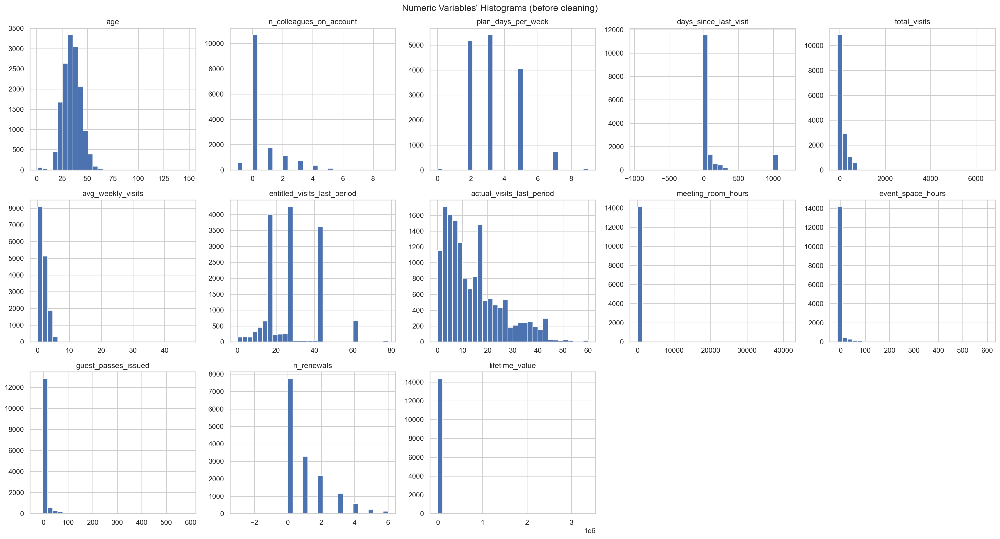

In [56]:
# All Numeric Variables' Histograms in one figure
fig, axes = plt.subplots(3, ceil(len(metric_features) / 3), figsize=(22, 12))

for ax, feat in zip(axes.flatten(), metric_features):
    ax.hist(df[feat].dropna(), bins=30)
    ax.set_title(feat)

# Hide the empty slots of the grid
for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)

plt.suptitle("Numeric Variables' Histograms (before cleaning)")
plt.tight_layout()
plt.show()

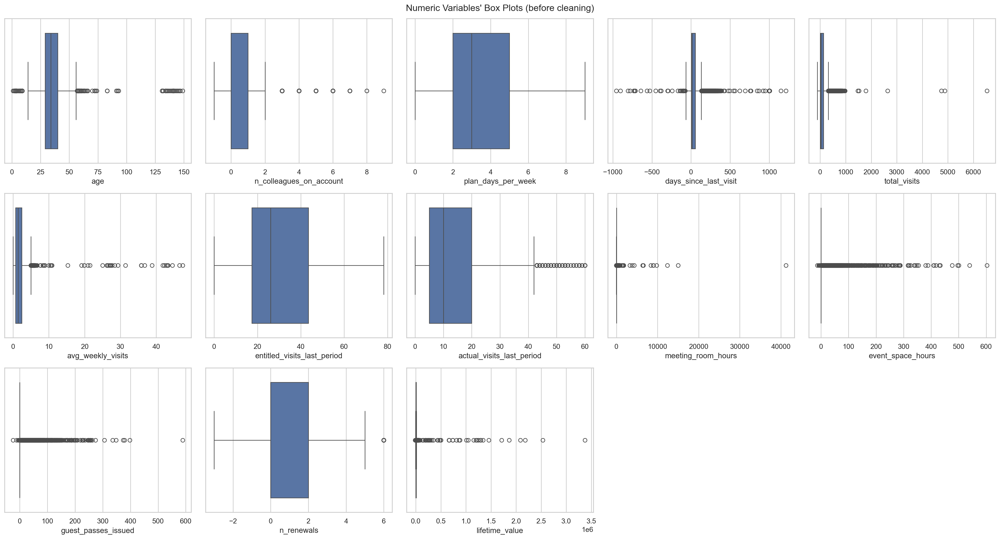

In [57]:
# All Numeric Variables' Box Plots in one figure
fig, axes = plt.subplots(3, ceil(len(metric_features) / 3), figsize=(22, 12))

for ax, feat in zip(axes.flatten(), metric_features):
    sns.boxplot(x=df[feat], ax=ax)

for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)

plt.suptitle("Numeric Variables' Box Plots (before cleaning)")
plt.tight_layout()
plt.show()

In [58]:
# How many members use no add-on at all, and how many use none of the three add-ons with recorded usage?
addon_flags = [feat for feat in bool_features if feat.startswith("uses_")]
print(f"No add-on at all: {(~df[addon_flags].any(axis=1)).mean() * 100:.1f}%")
print(f"None of meeting rooms, event space, guest passes: "
      f"{(~df[['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes']].any(axis=1)).mean() * 100:.1f}%")

No add-on at all: 20.0%
None of meeting rooms, event space, guest passes: 55.4%


### Insights
- **Impossible values appear in almost every feature:** ages from 1 to 149, negative visits, hours, passes,
  renewals and revenue, `n_colleagues_on_account = -1`, and plans with 0 or 9 days per week.
- **`days_since_last_visit` has a block of values near 1000** (the 999 placeholder) and negative values.
- **`lifetime_value` is unreadable on this scale:** a few values in the millions (the lost decimal points from 5.7)
  squeeze everything else into the first bar.
- **`total_visits` and `avg_weekly_visits` have a few physically impossible values** (up to 6,530 visits and
  47 visits per week).
- **Add-on usage (`meeting_room_hours`, `event_space_hours`, `guest_passes_issued`) is zero-inflated:** most members
  never use these three add-ons and a small group uses them a lot, although only a minority uses no add-on at all
  (see the cell above). This split is a first hint of segments.
- **`plan_days_per_week` and `entitled_visits_last_period` are discrete,** with peaks that follow the plan tiers.
- **`age`, without the impossible values, is bell-shaped** around 25–45 years: a working-age population.

## 7. Data Editing (fixing inconsistent values)

Every decision below comes from the checks in section 5:

| # | Problem | Decision | Why |
|---|---|---|---|
| 1 | Impossible values (ages outside 18–100, negative counts/hours, > 7 visits per week, > 1095 visits) | Set to missing, imputed in section 9 | The rest of the row is fine, so we keep the member and only lose the wrong value |
| 2 | `n_colleagues_on_account = -1` | 0 on individual accounts, missing on team accounts | Individual accounts never have colleagues (5.5) |
| 3 | `plan_days_per_week` not matching the tier | Set to the tier's days; entitlements calculated with the wrong days are recalculated | The tier is the contract; 0 or 9 days are impossible (5.5) |
| 4 | Missing `plan_tier` | Inferred from the days per week; for 5 days (two possible tiers) the most frequent 5-day tier | Keeps tier and days coherent |
| 5 | `uses_meeting_rooms` False with hours > 0 | Flag set to True | Recorded hours prove the room was used |
| 6 | Missing hours/passes for add-ons never used | Set to 0 | Not using an add-on means 0 usage (5.2) |
| 7 | Contradictory dates | Rows removed | We cannot know which date is wrong (5.6); guessing would create fake tenure and recency |
| 8 | `membership_end = 1970-01-01` | Set to empty (NaT) = still active | Proven in 5.6 |
| 9 | `days_since_last_visit` (999 placeholder, negatives) | Recalculated from the dates | The rule behind the column was found in 5.6 |
| 10 | `lifetime_value` 0 or negative | Set to missing, imputed in section 9 | Placeholders, not revenue (5.7) |
| 11 | `lifetime_value` more than 20x the plan price | Divided by 100 | Lost decimal point (5.7) |
| 12 | `total_visits` = 0 with `avg_weekly_visits` > 0 | Set to missing, rebuilt in section 9 | The two columns contradict each other and the member did visit (5.6) |
| 13 | `meeting_room_hours` recorded in minutes | Divided by 60 | Both tests of 5.8: the format and the revenue |

In [59]:
# Flag out-of-range ages as missing (valid range: 18–100)
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan

# Features that logically cannot be negative
# Note: 'days_since_last_visit' and 'lifetime_value' are excluded here as they require specific handling in steps 9–11
non_negative_features = ["n_colleagues_on_account", "total_visits", "meeting_room_hours",
                         "event_space_hours", "guest_passes_issued", "n_renewals"]

# Fix known encoding edge case: -1 colleagues on an individual account simply means 0 (no extra colleagues)
# This must run before the generic negative check so we don't accidentally erase this info to NaN
df.loc[(df["n_colleagues_on_account"] == -1) & (df["is_team_account"] == False), "n_colleagues_on_account"] = 0

for feat in non_negative_features:
    df.loc[df[feat] < 0, feat] = np.nan
    
# Sanity checks on visit metrics: cap weekly visits at 7 and cap total visits at 3 years of daily activity
df.loc[df["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
df.loc[df["total_visits"] > 3 * 365, "total_visits"] = np.nan

# Fix logical contradiction: zero total visits with a positive weekly average makes no sense
# Setting total_visits to NaN here so we can rebuild it properly from the weekly average in section 9
df.loc[(df["total_visits"] == 0) & (df["avg_weekly_visits"] > 0), "total_visits"] = np.nan

In [60]:
# Ensure plan_days_per_week strictly aligns with the member's actual plan tier
expected_days = expected_plan_days(df)
wrong_days = df["plan_tier"].notna() & (df["plan_days_per_week"] != expected_days)
recorded_days = df["plan_days_per_week"].copy()
# Correct the mismatched plan days using the mapping function
df.loc[wrong_days, "plan_days_per_week"] = expected_days[wrong_days]
print("plan_days_per_week values fixed:", wrong_days.sum())

# Handle edge cases where metrics were mistakenly calculated assuming a 9-day entitlement
# If recorded as 9 days and the actual limit is lower, rescale the entitlement proportionally (5.5)
rescale = wrong_days & (recorded_days == 9) & (df[ent] > df["plan_days_per_week"] * weeks_last_period + 0.05)
df.loc[rescale, ent] = (df[ent] / 9 * df["plan_days_per_week"])[rescale].round(2)

# Handle cases where 0 entitled visits were recorded due to a 0-day mismatch
# For these, default back to a full standard period based on the corrected plan tier (5.5)
zero_entitled = wrong_days & (recorded_days == 0) & (df[ent] == 0)
df.loc[zero_entitled, ent] = (df["plan_days_per_week"] * weeks_last_period)[zero_entitled].round(2)
print("entitled_visits_last_period rescaled (9 days):", rescale.sum(),
      "| set to a full period (0 entitled visits):", zero_entitled.sum())

plan_days_per_week values fixed: 97
entitled_visits_last_period rescaled (9 days): 30 | set to a full period (0 entitled visits): 10


In [61]:
# Infer missing plan_tier for unambiguous cases (2, 3, and 7 days map 1:1 to a specific tier)
days_tier = {2: "hot_desk", 3: "flex", 7: "private_office"}
print("Missing plan_tier before:", df["plan_tier"].isna().sum())

# Impute plan_tier based on unique plan_days_per_week values
for days, tier in days_tier.items():
    df.loc[df["plan_tier"].isna() & (df["plan_days_per_week"] == days), "plan_tier"] = tier

print("Missing plan_tier after the unambiguous cases:", df["plan_tier"].isna().sum())
# Inspect remaining missing tiers to see which ambiguous day counts are left
df.loc[df["plan_tier"].isna(), "plan_days_per_week"].value_counts()

Missing plan_tier before: 105
Missing plan_tier after the unambiguous cases: 49


plan_days_per_week
5    49
Name: count, dtype: int64

In [62]:
# The rest have 5 days, which fits dedicated_desk or full_time. We pick the more frequent of the two:
# it is the most likely answer and it keeps tier and days coherent.
tier_5_days = df.loc[df["plan_days_per_week"] == 5, "plan_tier"].mode()[0]
df.loc[df["plan_tier"].isna() & (df["plan_days_per_week"] == 5), "plan_tier"] = tier_5_days

print("Tier used for 5-day plans:", tier_5_days)
print("Missing plan_tier:", df["plan_tier"].isna().sum())

Tier used for 5-day plans: full_time
Missing plan_tier: 0


In [63]:
# Fix contradiction: members with logged meeting room hours must have the 'uses_meeting_rooms' flag set to True
fix_flag = (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0)
df.loc[fix_flag, "uses_meeting_rooms"] = True
print("uses_meeting_rooms flags fixed:", fix_flag.sum())

uses_meeting_rooms flags fixed: 55


In [64]:
# Default unused add-on metrics to 0 when the corresponding usage flag is explicitly False
fill_meeting = df["meeting_room_hours"].isna() & (df["uses_meeting_rooms"] == False)
fill_guest = df["guest_passes_issued"].isna() & (df["uses_guest_passes"] == False)
df.loc[fill_meeting, "meeting_room_hours"] = 0
df.loc[fill_guest, "guest_passes_issued"] = 0
print("meeting_room_hours set to 0:", fill_meeting.sum())
print("guest_passes_issued set to 0:", fill_guest.sum())

meeting_room_hours set to 0: 902
guest_passes_issued set to 0: 1066


In [65]:
# Filter out rows with invalid or contradictory timeline dates
# Ignore placeholder end dates (year 1970) representing active subscriptions
end_date = df["membership_end"].where(df["membership_end"].dt.year != 1970)
# Flag logic flaws: 
# - End date predates start date
# - Last badge swipe happened before membership started
# - Last badge swipe happened after the membership ended
# - Last badge swipe is in the future relative to the extraction date
date_problem = ((end_date < df["membership_start"])
                | (df["last_badge_swipe"] < df["membership_start"])
                | (df["last_badge_swipe"] > end_date)
                | (df["last_badge_swipe"] > extraction_date))

rows_before = df.shape[0]
df = df[~date_problem].copy()
print("Rows removed:", date_problem.sum(), f"({date_problem.sum() / rows_before * 100:.2f}%)")

Rows removed: 333 (2.16%)


In [66]:
# Convert the 1970-01-01 epoch placeholder into NaT (null date)
# Moving forward, missing membership_end values explicitly signify active members
df.loc[df["membership_end"].dt.year == 1970, "membership_end"] = pd.NaT
print("Active members (no end date):", df["membership_end"].isna().sum())

Active members (no end date): 3903


In [67]:
# Recalculate 'days_since_last_visit' using the baseline logic established in Section 5.6
# For inactive members, calculate recency relative to their end date; for active members, use the extraction date.
reference_date = df["membership_end"].fillna(extraction_date)
recalculated_days = (reference_date - df["last_badge_swipe"]).dt.days

# Sanity check: validate recalculated values against existing plausible data (0–998 days range)
was_plausible = df["days_since_last_visit"].between(0, 998)
difference = (recalculated_days - df["days_since_last_visit"])[was_plausible]
print(f"Plausible original values matched within 1 day: {(difference.abs() <= 1).mean() * 100:.1f}%")

df["days_since_last_visit"] = recalculated_days
df["days_since_last_visit"].describe().round(2)

Plausible original values matched within 1 day: 99.5%


count    15117.00
mean        37.72
std         61.51
min          0.00
25%          4.00
50%         11.00
75%         44.00
max        391.00
Name: days_since_last_visit, dtype: float64

In [68]:
# lifetime_value of 0 or below is a placeholder -> missing
ltv_placeholder = df["lifetime_value"] <= 0
df.loc[ltv_placeholder, "lifetime_value"] = np.nan
print("lifetime_value set to missing (0 or negative):", ltv_placeholder.sum())

lifetime_value set to missing (0 or negative): 1784


In [69]:
# Values more than 20x the plan price lost their decimal point
tenure_months = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 30.44
expected_ltv = df["plan_tier"].map(tier_monthly_price) * tenure_months

lost_decimal = (expected_ltv > 0) & (df["lifetime_value"] / expected_ltv > 20)
df.loc[lost_decimal, "lifetime_value"] = df.loc[lost_decimal, "lifetime_value"] / 100
print("lifetime_value values divided by 100:", lost_decimal.sum())

# Check: after the repair they must be close to the plan price
(df.loc[lost_decimal, "lifetime_value"] / expected_ltv[lost_decimal]).describe().round(2)

lifetime_value values divided by 100: 83


count    83.00
mean      1.23
std       0.70
min       0.66
25%       0.92
50%       1.06
75%       1.19
max       5.91
dtype: float64

In [70]:
# Meeting-room hours recorded in minutes (5.8)
in_minutes = df[id_feature].isin(minutes_ids)
df.loc[in_minutes, "meeting_room_hours"] = (df.loc[in_minutes, "meeting_room_hours"] / 60).round(1)
print("meeting_room_hours values divided by 60:", in_minutes.sum())
df.loc[in_minutes, "meeting_room_hours"].describe().round(1)

meeting_room_hours values divided by 60: 10


count     10.0
mean     105.0
std       74.0
min       21.2
25%       36.2
50%      107.2
75%      147.3
max      249.8
Name: meeting_room_hours, dtype: float64

In [71]:
# Re-run the checks on the edited data
expected_days = expected_plan_days(df)
end_date = df["membership_end"]
check_after = {
    "age < 18 or age > 100": (df["age"] < 18) | (df["age"] > 100),
    "negative values": (df[non_negative_features + ["days_since_last_visit", "lifetime_value"]] < 0).any(axis=1),
    "plan_days_per_week not matching plan_tier": df["plan_days_per_week"] != expected_days,
    "entitled visits above the plan": df[ent] > df["plan_days_per_week"] * weeks_last_period + 0.05,
    "actual visits above entitled visits": df["actual_visits_last_period"] > df[ent],
    "avg_weekly_visits > 7": df["avg_weekly_visits"] > 7,
    "total_visits > 1095": df["total_visits"] > 3 * 365,
    "uses_meeting_rooms False but hours > 0": (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0),
    "contradictory dates": ((end_date < df["membership_start"]) | (df["last_badge_swipe"] < df["membership_start"])
                            | (df["last_badge_swipe"] > end_date) | (df["last_badge_swipe"] > extraction_date)),
    "lifetime_value above 20x the plan price": df["lifetime_value"] / expected_ltv > 20,
}
pd.Series({rule: mask.sum() for rule, mask in check_after.items()}, name="n_rows")

age < 18 or age > 100                        0
negative values                              0
plan_days_per_week not matching plan_tier    0
entitled visits above the plan               0
actual visits above entitled visits          0
avg_weekly_visits > 7                        0
total_visits > 1095                          0
uses_meeting_rooms False but hours > 0       0
contradictory dates                          0
lifetime_value above 20x the plan price      0
Name: n_rows, dtype: int64

What about the 8 rows from 5.5 with more actual visits than entitled visits? We did not touch them directly,
but the table above shows none is left. They were the rows with 0 days and 0 entitled visits:

In [72]:
over_entitlement = df_original["actual_visits_last_period"] > df_original["entitled_visits_last_period"]
df_original.loc[over_entitlement, ["plan_days_per_week", "entitled_visits_last_period", "actual_visits_last_period"]]

,plan_days_per_week,entitled_visits_last_period,actual_visits_last_period
1988,0,0.0,6
2381,0,0.0,9
2382,0,0.0,26
4695,0,0.0,21
6973,0,0.0,9
7862,0,0.0,23
10654,0,0.0,2
12684,0,0.0,10


So "more visits than entitled" was not a real behaviour but a side effect of the wrong 0 days, and it disappeared
when the entitlement was fixed.

## 8. Outliers

### 8.1 IQR method

In [73]:
q1 = df[metric_features].quantile(0.25)
q3 = df[metric_features].quantile(0.75)
iqr = q3 - q1

lower_lim = q1 - 1.5 * iqr
upper_lim = q3 + 1.5 * iqr

pd.DataFrame({"q1": q1, "q3": q3, "iqr": iqr, "lower_lim": lower_lim, "upper_lim": upper_lim}).round(2)

,q1,q3,iqr,lower_lim,upper_lim
age,29.00,40.00,11.00,12.50,56.50
n_colleagues_on_account,0.00,1.00,1.00,-1.50,2.50
plan_days_per_week,2.00,5.00,3.00,-2.50,9.50
days_since_last_visit,4.00,44.00,40.00,-56.00,104.00
total_visits,8.00,133.00,125.00,-179.50,320.50
avg_weekly_visits,0.71,2.40,1.69,-1.83,4.94
entitled_visits_last_period,17.39,43.48,26.09,-21.74,82.61
actual_visits_last_period,5.00,20.00,15.00,-17.50,42.50
meeting_room_hours,0.00,4.80,4.80,-7.20,12.00
event_space_hours,0.00,0.00,0.00,0.00,0.00


In [74]:
# A missing value is not an outlier, so NaNs are kept here
filters_iqr_all = df[metric_features].apply(
    lambda col: col.between(lower_lim[col.name], upper_lim[col.name]) | col.isna()
).all(axis=1)

print("Percentage of data kept after removing outliers (IQR):", round(filters_iqr_all.mean() * 100, 2))

Percentage of data kept after removing outliers (IQR): 49.57


In [75]:
# Which features flag the most rows?
df[metric_features].apply(
    lambda col: ~(col.between(lower_lim[col.name], upper_lim[col.name]) | col.isna())
).sum().sort_values(ascending=False)

meeting_room_hours             3176
guest_passes_issued            2417
event_space_hours              1735
total_visits                   1679
days_since_last_visit          1456
n_colleagues_on_account        1291
lifetime_value                  740
actual_visits_last_period       375
avg_weekly_visits               272
n_renewals                      145
age                             113
plan_days_per_week                0
entitled_visits_last_period       0
dtype: int64

**The IQR method would keep only about half of the data, so we do not use it.** The add-on features have
Q1 = Q3 = 0, so *any* usage counts as an outlier, and `lifetime_value` is flagged for long or premium memberships,
which are naturally expensive. Removing those rows would delete exactly the heavy users and high-value members
that segmentation is supposed to find.

### 8.2 Manual outlier removal

In [76]:
# The upper percentiles show where the values stop being "a lot" and start being "impossible"
df[["meeting_room_hours", "event_space_hours", "guest_passes_issued", "total_visits",
    "lifetime_value"]].quantile([0.5, 0.9, 0.99, 0.999, 1]).round(2)

,meeting_room_hours,event_space_hours,guest_passes_issued,total_visits,lifetime_value
0.500,0.00,0.00,0.00,35.00,1629.32
0.900,74.60,1.40,12.00,374.00,11706.53
0.990,308.60,126.09,114.88,690.00,24800.95
0.999,758.59,336.95,248.09,853.27,30313.38
1.000,41220.00,602.80,589.00,972.00,128431.81


The two tests of 5.8, applied to the largest values of the other two usage features: are they recorded like the rest
of the column, and does the revenue support them? (A ratio of 1 means the member pays just the plan.)

In [77]:
current_ltv_ratio = df["lifetime_value"] / expected_ltv

tail_check = {}
for feat in ["event_space_hours", "guest_passes_issued"]:
    top = df[feat] > df[feat].quantile(0.999)
    others = (df[feat] > 0) & ~top
    tail_check[feat] = {
        "rows_top_0.1%": top.sum(),
        "smallest_in_top": df.loc[top, feat].min(),
        "largest": df.loc[top, feat].max(),
        "% whole, top": (df.loc[top, feat] % 1 == 0).mean() * 100,
        "% whole, other users": (df.loc[others, feat] % 1 == 0).mean() * 100,
        "median ratio to plan, top": current_ltv_ratio[top].median(),
        "median ratio to plan, other users": current_ltv_ratio[others].median(),
    }
pd.DataFrame(tail_check).round(2)

,event_space_hours,guest_passes_issued
rows_top_0.1%,16.00,15.00
smallest_in_top,338.40,249.00
largest,602.80,589.00
"% whole, top",18.75,100.00
"% whole, other users",8.26,100.00
"median ratio to plan, top",5.41,2.97
"median ratio to plan, other users",1.43,1.17


These members pay several times what their plan costs, far more than the other users of the same add-on, so the
revenue supports their usage. The largest event-space hours are also not all whole numbers, unlike the extreme
meeting-room hours (guest passes are counts, so they are always whole). They look like real heavy users, which is what
segmentation should find, so **we set no limit on these two features**.

In [78]:
# Apply an upper-bound threshold to 'meeting_room_hours' to filter out unreliable values
# Values exceeding this limit exhibit integer-only distributions inconsistent with the rest of the feature, 
# indicating data corruption that cannot be reliably repaired
manual_limits = {"meeting_room_hours": meeting_limit}

filters_man = pd.Series(True, index=df.index)
for feat, limit in manual_limits.items():
    filters_man = filters_man & ((df[feat] <= limit) | df[feat].isna())

# Rows removed by each limit
pd.Series({feat: (df[feat] > limit).sum() for feat, limit in manual_limits.items()}, name="rows_removed")

meeting_room_hours    9
Name: rows_removed, dtype: int64

In [79]:
print("Percentage of data kept after removing outliers (manual):", round(filters_man.mean() * 100, 2))

Percentage of data kept after removing outliers (manual): 99.94


The manual limit removes only **9 rows (0.06%)**. Together with the 15 duplicates and the 333 rows with
contradictory dates, we keep 97.7% of the data, inside the ~5% rule of thumb. The long but plausible tail of
heavy users stays in the data; the removed rows could later be studied on their own (bonus: multivariate anomaly detection).

### 8.3 Combining methods and winsorizing 

In [80]:
# Combine statistical (IQR) and manual filters (retaining rows that pass either criterion)
filters_combined = filters_iqr_all | filters_man
print("Percentage kept with IQR OR manual:", round(filters_combined.mean() * 100, 2))
print("Rows removed by the manual limits that the IQR would keep:", (~filters_man & filters_iqr_all).sum())

Percentage kept with IQR OR manual: 99.94
Rows removed by the manual limits that the IQR would keep: 0


Combining gives the same result as the manual limits alone: every row removed by the manual limits is also an
IQR outlier, so the IQR adds nothing here.

**Winsorizing (capping) is not used.** Capping would give every heavy user the same value at the cap and hide
exactly the differences we want clustering to find. The skew of the usage features will be handled later with
scaling/transformations, which keep the order between members.

In [191]:
# Alinha o filtro pelo índice atual do DataFrame para evitar conflitos de tamanho
mask = pd.Series(filters_man, index=df.index).fillna(False)

removed_outliers = df[~mask].copy()  # studied again in section 25
df = df[mask].copy()

print("Rows kept so far:", df.shape[0], "of", df_original.shape[0],
      f"({df.shape[0] / df_original.shape[0] * 100:.2f}%, rule of thumb: remove at most ~5%)")

Rows kept so far: 14776 of 15465 (95.54%, rule of thumb: remove at most ~5%)


/var/folders/6z/1gm9nfv15ksckcw7_b5hvc400000gn/T/ipykernel_94190/1390638799.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mask = pd.Series(filters_man, index=df.index).fillna(False)


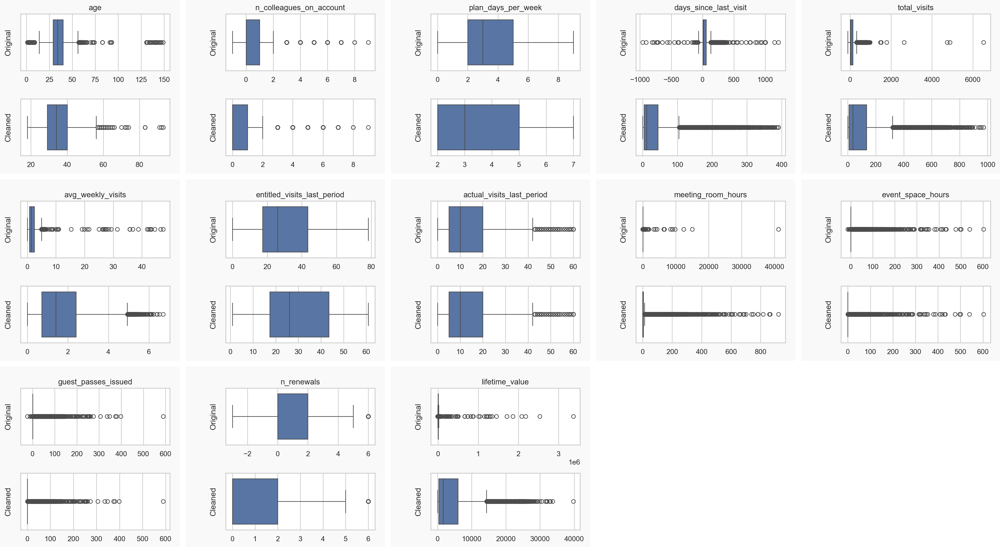

In [82]:
# Box plots of the original data vs the data after editing and outlier removal 
# lifetime_value is text in the original data, so it is converted first (5.3)
original_numeric = df_original.copy()
original_numeric["lifetime_value"] = (original_numeric["lifetime_value"]
                                      .str.replace("€", "", regex=False)
                                      .str.replace(",", "", regex=False)
                                      .str.strip()
                                      .astype(float))

fig = plt.figure(figsize=(22, 12))
subfigs = fig.subfigures(3, ceil(len(metric_features) / 3), wspace=.03, hspace=.03)

for sfig, feat in zip(subfigs.flatten(), metric_features):
    # Each box plot keeps its own scale: with a shared axis the impossible values would hide the rest
    axes = sfig.subplots(2, 1)

    sns.boxplot(x=original_numeric[feat], ax=axes[0])
    axes[0].set_ylabel("Original")
    axes[0].set_xlabel("")
    axes[0].set_title(feat)

    sns.boxplot(x=df[feat], ax=axes[1])
    axes[1].set_ylabel("Cleaned")
    axes[1].set_xlabel("")

    sfig.set_facecolor("#F9F9F9")
    sfig.subplots_adjust(left=.2, right=.95, bottom=.1, hspace=.5)

for sfig in subfigs.flatten()[len(metric_features):]:
    sfig.set_visible(False)

plt.show()

Each box plot has its own scale, so compare the axes as well as the boxes. The impossible values are gone (ages up to 149,
negative visits, plans with 0 or 9 days) and `lifetime_value` falls from millions to tens of thousands of euros, while the long
tail of heavy users stays, as intended.

## 9. Missing Value Imputation

In [83]:
df.isna().sum()[lambda s: s > 0]

age                         678
gender                      508
country                     413
n_colleagues_on_account     144
membership_end             3902
total_visits                154
avg_weekly_visits            41
meeting_room_hours          400
event_space_hours             8
guest_passes_issued         204
n_renewals                   65
lifetime_value             2787
dtype: int64

`membership_end` is empty on purpose (active members), so it is not imputed.

Before choosing how to impute, what *kind* of missingness is it? If the share of missing values changes with an observed variable, the values are Missing At Random (MAR) and that variable should be used to impute them.

In [84]:
# % missing per plan tier
check_feats = ["age", "gender", "country", "lifetime_value"]
pd.DataFrame({feat: df[feat].isna().groupby(df["plan_tier"]).mean() * 100 for feat in check_feats}).round(1)

,age,gender,country,lifetime_value
plan_tier,,,,
dedicated_desk,4.8,4.2,2.7,22.0
flex,4.3,3.2,2.8,18.2
full_time,4.5,3.5,2.5,21.3
hot_desk,4.3,3.1,2.6,15.4
private_office,5.6,4.3,3.3,25.0


In [85]:
# % missing for active members vs members who left, and for individual vs team accounts
is_active = df["membership_end"].isna().map({True: "active", False: "left"})
pd.concat([
    pd.DataFrame({feat: df[feat].isna().groupby(is_active).mean() * 100 for feat in check_feats}),
    pd.DataFrame({feat: df[feat].isna().groupby(df["is_team_account"]).mean() * 100 for feat in check_feats})
      .rename(index={False: "individual", True: "team"}),
]).round(1)

,age,gender,country,lifetime_value
active,4.9,3.4,2.7,19.2
left,4.4,3.3,2.7,18.2
individual,4.3,3.4,2.7,18.1
team,5.0,3.3,2.8,19.2


In [86]:
#lifetime_value: % missing by number of renewals (a proxy for how long the member stayed)
(df["lifetime_value"].isna().groupby(df["n_renewals"]).mean() * 100).round(1)

n_renewals
0.0    17.0
1.0    18.2
2.0    20.4
3.0    20.5
4.0    22.1
5.0    24.6
6.0    22.8
Name: lifetime_value, dtype: float64

| Feature | Evidence | Type | Treatment |
|---|---|---|---|
| `meeting_room_hours`, `guest_passes_issued` | Missing rate about the same for users and non-users (5.2) | Closer to MCAR | 0 if never used (done in 7), median of the users with a similar tenure otherwise (9.1) |
| `lifetime_value` | Missing more often in the expensive tiers and for members with more renewals | MAR | Plan price × months (uses tier and tenure) |
| `age`, `gender`, `country` | About the same share in every tier, status and account type | Consistent with MCAR (MNAR cannot be ruled out for a personal question like gender) | Median (`age`), `Unknown` (`gender`, `country`) |
| `total_visits`, `avg_weekly_visits`, `n_colleagues_on_account`, `n_renewals`, `event_space_hours` | Created by us when removing impossible values (7) | Not a property of the data | Rules where possible, median otherwise |

### 9.1 Rule-based imputation

Four features have a better estimate than a median of all members:
- `n_colleagues_on_account` on team accounts: the overall median (0) is impossible for a team account,
  so we use the median of the team accounts.
- `lifetime_value`: section 5.7 showed that it is *monthly plan price × months*. That is far more precise than a
  single median for everyone (a private office for 3 years and a hot desk for 1 month would get the same value).
- `total_visits` / `avg_weekly_visits`: section 5.6 showed that one is the other divided by the weeks as a member,
  so each can be rebuilt from the other (a median would break that relation).
- Add-on usage of members who **did** use the add-on: the median of all members is 0, because most never use it, which
  would contradict their flag. Usage also accumulates with time, so we apply median among users with a similar
  tenure.

In [87]:
# Impute missing 'n_colleagues_on_account' for team accounts using the median value
team = df["is_team_account"] == True
team_median = df.loc[team, "n_colleagues_on_account"].median()
df.loc[team & df["n_colleagues_on_account"].isna(), "n_colleagues_on_account"] = team_median
print("Median colleagues on team accounts:", team_median)
print("Missing n_colleagues_on_account:", df["n_colleagues_on_account"].isna().sum())

Median colleagues on team accounts: 2.0
Missing n_colleagues_on_account: 0


In [88]:
# Estimate missing lifetime_value using expected revenue (tier monthly price multiplied by tenure in months)
tenure_months = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 30.44
expected_ltv = df["plan_tier"].map(tier_monthly_price) * tenure_months

ltv_missing = df["lifetime_value"].isna()
df.loc[ltv_missing, "lifetime_value"] = expected_ltv[ltv_missing].round(2)

# Track imputed rows for downstream analysis
df["ltv_imputed"] = ltv_missing
print("lifetime_value imputed:", ltv_missing.sum(), f"({ltv_missing.mean() * 100:.1f}% of rows)")
print("Missing lifetime_value:", df["lifetime_value"].isna().sum())

lifetime_value imputed: 2787 (18.4% of rows)
Missing lifetime_value: 0


In [89]:
# Reconstruct missing visit metrics using membership duration and cross-metric ratios
weeks_member = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 7
rebuilt_total = (df["avg_weekly_visits"] * weeks_member).round()
rebuilt_weekly = (df["total_visits"] / weeks_member).round(2)

# Apply reconstruction only for memberships lasting at least a week with plausible bounds
fill_total = df["total_visits"].isna() & (weeks_member >= 1) & (rebuilt_total <= 3 * 365)
fill_weekly = df["avg_weekly_visits"].isna() & (weeks_member >= 1) & (rebuilt_weekly <= 7)
df.loc[fill_total, "total_visits"] = rebuilt_total[fill_total]
df.loc[fill_weekly, "avg_weekly_visits"] = rebuilt_weekly[fill_weekly]

print("total_visits rebuilt from avg_weekly_visits:", fill_total.sum(),
      "| still missing:", df["total_visits"].isna().sum())
print("avg_weekly_visits rebuilt from total_visits:", fill_weekly.sum(),
      "| still missing:", df["avg_weekly_visits"].isna().sum())

total_visits rebuilt from avg_weekly_visits: 146 | still missing: 8
avg_weekly_visits rebuilt from total_visits: 29 | still missing: 12


**Add-on usage of the users.** Hours and passes accumulate while a member stays, so one median for all users would give a
member of a few days the same usage as a member of three years. We check this by splitting tenure into four equal groups.

In [90]:
addon_usage = {"meeting_room_hours": "uses_meeting_rooms",
               "event_space_hours": "uses_event_space",
               "guest_passes_issued": "uses_guest_passes"}

# Median usage of the users in each quarter of tenure (the groups come from the data, not from limits we chose)
tenure_band = pd.qcut(weeks_member, 4)
usage_by_tenure = pd.DataFrame({
    feat: df.loc[df[flag], feat].groupby(tenure_band[df[flag]], observed=True).median()
    for feat, flag in addon_usage.items()
}).rename_axis("weeks as a member")

print("Median of all members:", df[list(addon_usage)].median().to_dict())
usage_by_tenure

Median of all members: {'meeting_room_hours': 0.0, 'event_space_hours': 0.0, 'guest_passes_issued': 0.0}


,meeting_room_hours,event_space_hours,guest_passes_issued
weeks as a member,,,
"(0.285, 9.286]",1.2,0.95,1.0
"(9.286, 40.286]",5.2,4.80,4.0
"(40.286, 90.714]",46.1,36.45,25.0
"(90.714, 156.429]",74.1,39.55,40.0


In [91]:
# Impute missing addon usage metrics using the tenure-band median
for feat, flag in addon_usage.items():
    missing_usage = df[feat].isna() & df[flag]
    df.loc[missing_usage, feat] = tenure_band[missing_usage].map(usage_by_tenure[feat]).astype(float)
    print(f"{feat}: imputed {missing_usage.sum()}")

meeting_room_hours: imputed 400
event_space_hours: imputed 8
guest_passes_issued: imputed 204


Limitation of the `lifetime_value` rule: it only counts the plan, not add-ons, so heavy add-on users with an
unknown value are slightly underestimated. Only about 5% of members pay more than ~2.4 times their plan
(95th percentile in 5.7), so this affects few rows. The column `ltv_imputed` marks these rows, so that any feature
comparing a member's revenue with the plan price can leave them out.

### 9.2 `gender` and `country`

We do **not** fill them with the mode. Filling ~500 genders with "Female" and ~400 countries with "Portugal"
would invent people that do not exist, and for a personal question like gender, not answering can be a choice
(MNAR) that the data cannot rule out. We use an explicit `Unknown` category instead, the same approach the
source system already uses for `industry`. These features describe the member; they are better for profiling segments than for clustering.

In [92]:
for feat in ["gender", "country"]:
    df[feat] = df[feat].fillna("Unknown")
    print(feat, "->", df[feat].value_counts().to_dict())

gender -> {'Female': 7693, 'Male': 6418, 'Unknown': 508, 'Other': 489}
country -> {'Portugal': 10273, 'United Kingdom': 1147, 'Germany': 883, 'Spain': 714, 'France': 523, 'Netherlands': 477, 'Other (Europe)': 441, 'Unknown': 413, 'Ireland': 237}


### 9.3 Remaining metric features: median vs KNN imputation 

In [93]:
impute_features = [feat for feat in metric_features if df[feat].isna().any()]
print("Features still with missing values:", impute_features)

# Skewness tells us whether the mean or the median is the better central value
df[impute_features].skew().round(2)

Features still with missing values: ['age', 'total_visits', 'avg_weekly_visits', 'n_renewals']


age                  0.44
total_visits         2.13
avg_weekly_visits    0.92
n_renewals           1.42
dtype: float64

In [94]:
# Option 1: median
df_central = df.copy()
medians = df_central[impute_features].median()
df_central[impute_features] = df_central[impute_features].fillna(medians)

In [95]:
# Option 2: KNN imputer, using all metric features to find the neighbours
df_neighbors = df.copy()
imputer = KNNImputer(n_neighbors=5, weights="uniform")
df_neighbors[metric_features] = imputer.fit_transform(df_neighbors[metric_features])

In [96]:
pd.DataFrame({
    "original_mean": df[impute_features].mean(),
    "median_imputed_mean": df_central[impute_features].mean(),
    "knn_imputed_mean": df_neighbors[impute_features].mean(),
    "original_std": df[impute_features].std(),
    "median_imputed_std": df_central[impute_features].std(),
    "knn_imputed_std": df_neighbors[impute_features].std(),
}).round(2)

,original_mean,median_imputed_mean,knn_imputed_mean,original_std,median_imputed_std,knn_imputed_std
age,34.76,34.72,34.77,8.40,8.21,8.25
total_visits,109.83,109.79,109.92,164.67,164.64,164.73
avg_weekly_visits,1.71,1.71,1.71,1.29,1.29,1.29
n_renewals,1.02,1.01,1.02,1.34,1.34,1.34


- **Both methods give almost the same means and standard deviations,** because few values are missing in each
  feature by now (the big gaps were already handled by rules).
- **We keep the median:** it is simpler, robust to the skew of these features (see the skewness above),
  and KNN would need scaled features first. Without scaling, `lifetime_value` (thousands of euros) dominates the
  distance and the "neighbours" would just be members with a similar revenue.

In [97]:
# Keep the median imputation
df = df_central.copy()

# Only membership_end should still be empty (= active members)
df.isna().sum()[lambda s: s > 0]

membership_end    3902
dtype: int64

### 9.4 Last-period visits vs total visits

Section 5.6 showed that the visits of the last period cannot be above the total. This step comes after the imputation
because it also has to hold for the totals that were rebuilt or imputed.

In [98]:
above_total = df["actual_visits_last_period"] > df["total_visits"]
weeks_member = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 7

df.loc[above_total, "total_visits"] = df.loc[above_total, "actual_visits_last_period"]
df.loc[above_total, "avg_weekly_visits"] = (df["total_visits"] / weeks_member)[above_total].round(2)
print("total_visits raised to the last period:", above_total.sum(), f"({above_total.mean() * 100:.1f}% of rows)")

# Not corrected, only reported: members whose weekly average is above what the plan allows
above_plan = df["avg_weekly_visits"] > df["plan_days_per_week"]
print("avg_weekly_visits above the plan's days (left as recorded):", above_plan.sum())
print("Their days as a member:", (weeks_member[above_plan] * 7).describe().round(0).to_dict())
print("Of those, using day passes:", df.loc[above_plan, "uses_day_passes"].sum())

total_visits raised to the last period: 1013 (6.7% of rows)
avg_weekly_visits above the plan's days (left as recorded): 10
Their days as a member: {'count': 10.0, 'mean': 56.0, 'std': 23.0, 'min': 2.0, '25%': 50.0, '50%': 53.0, '75%': 72.0, 'max': 84.0}
Of those, using day passes: 2


In [99]:
# Final coherence check on the cleaned data
expected_days = expected_plan_days(df)
end_date = df["membership_end"]
final_checks = {
    "plan_days_per_week not matching plan_tier": df["plan_days_per_week"] != expected_days,
    "entitled visits above the plan": df[ent] > df["plan_days_per_week"] * weeks_last_period + 0.05,
    "actual visits above entitled visits": df["actual_visits_last_period"] > df[ent],
    "actual visits above total visits": df["actual_visits_last_period"] > df["total_visits"],
    "total_visits = 0 but avg_weekly_visits > 0": (df["total_visits"] == 0) & (df["avg_weekly_visits"] > 0),
    "avg_weekly_visits > 7": df["avg_weekly_visits"] > 7,
    "total_visits > 1095": df["total_visits"] > 3 * 365,
    "team account with 0 colleagues": (df["is_team_account"] == True) & (df["n_colleagues_on_account"] == 0),
    "individual account with colleagues": (df["is_team_account"] == False) & (df["n_colleagues_on_account"] > 0),
    "uses_meeting_rooms False but hours > 0": (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0),
    "age outside 18-100": (df["age"] < 18) | (df["age"] > 100),
    "negative or zero lifetime_value": df["lifetime_value"] <= 0,
    "negative values": (df[non_negative_features + ["days_since_last_visit"]] < 0).any(axis=1),
    "contradictory dates": ((end_date < df["membership_start"]) | (df["last_badge_swipe"] < df["membership_start"])
                            | (df["last_badge_swipe"] > end_date) | (df["last_badge_swipe"] > extraction_date)),
}
pd.Series({check: mask.sum() for check, mask in final_checks.items()}, name="n_rows")

plan_days_per_week not matching plan_tier     0
entitled visits above the plan                0
actual visits above entitled visits           0
actual visits above total visits              0
total_visits = 0 but avg_weekly_visits > 0    0
avg_weekly_visits > 7                         0
total_visits > 1095                           0
team account with 0 colleagues                0
individual account with colleagues            0
uses_meeting_rooms False but hours > 0        0
age outside 18-100                            0
negative or zero lifetime_value               0
negative values                               0
contradictory dates                           0
Name: n_rows, dtype: int64

In [100]:
# Add-on users recorded with no usage: the imputation should no longer add to these
raw_data = df_original.drop_duplicates()
pd.DataFrame({
    "before cleaning": {feat: (raw_data[flag] & (raw_data[feat] == 0)).sum() for feat, flag in addon_usage.items()},
    "after cleaning": {feat: (df[flag] & (df[feat] == 0)).sum() for feat, flag in addon_usage.items()},
}).rename_axis("used the add-on, usage = 0")

,before cleaning,after cleaning
"used the add-on, usage = 0",,
meeting_room_hours,7,7
event_space_hours,71,70
guest_passes_issued,124,123


In [101]:
print("Rows kept:", df.shape[0], "of", df_original.shape[0],
      f"({df.shape[0] / df_original.shape[0] * 100:.2f}%)")

Rows kept: 15108 of 15465 (97.69%)


### 9.5 Post-Cleaning Data Validation

We perform a final review of the dataset to verify that all data cleaning and imputation steps were successfully executed, confirming the absence of unhandled outliers and missing values before moving to downstream analysis.

Missing values in the metric features: 0


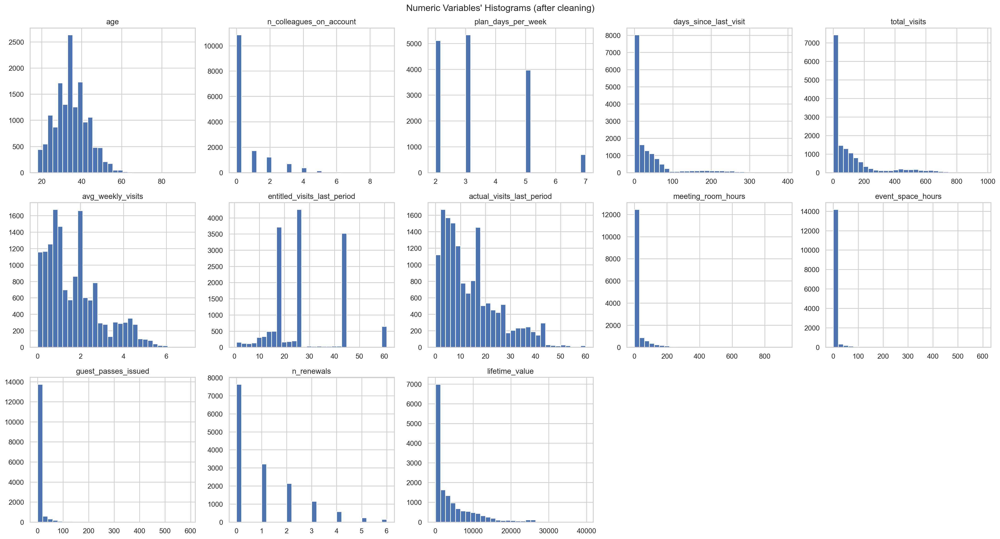

In [102]:
print("Missing values in the metric features:", df[metric_features].isna().sum().sum())

# All Numeric Variables' Histograms in one figure
fig, axes = plt.subplots(3, ceil(len(metric_features) / 3), figsize=(22, 12))

for ax, feat in zip(axes.flatten(), metric_features):
    ax.hist(df[feat], bins=30)
    ax.set_title(feat)

for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)

plt.suptitle("Numeric Variables' Histograms (after cleaning)")
plt.tight_layout()
plt.show()

### Insights
- **No missing or impossible values are left,** and every feature is now readable on its own scale (compare with section 6).
- **The spike in `age` around 34 is partly created by us:** about 4.5% of the ages were imputed with the median, so `age`
  should not be read as more concentrated than it is.
- **Add-on usage and `lifetime_value` are still strongly right-skewed.** This is the real tail of heavy users that we chose to
  keep, so these features need scaling and probably a transformation before distance-based clustering.
- **`avg_weekly_visits` and `total_visits` have more than one peak,** a first hint of different usage patterns, which the
  behavioural analysis should explore.

## 10. `clean_data()` – reusable cleaning function

All the steps above in one function, so that the cleaning can be repeated with one call.
It uses the reference values estimated in this notebook (`extraction_date`, `tier_monthly_price`,
`weeks_last_period`, `minutes_ids`, the category maps and the outlier limits), so it must be run after the cells above.

In [103]:
def clean_data(data):
    """Apply every cleaning step of this notebook to the raw ACDC dataframe."""
    data = data.copy()

    # 5.1 duplicates and 5.2 empty strings
    data = data.drop_duplicates()
    data = data.replace("", np.nan)

    # 5.3 data types
    data["uses_print"] = data["uses_print"].astype(bool)
    for feat in date_features:
        iso_format = pd.to_datetime(data[feat], format="%Y-%m-%d", errors="coerce")
        day_first_format = pd.to_datetime(data[feat], format="%d/%m/%Y", errors="coerce")
        data[feat] = iso_format.fillna(day_first_format)
    data["lifetime_value"] = (data["lifetime_value"].str.replace("€", "", regex=False)
                              .str.replace(",", "", regex=False).str.strip().astype(float))

    # 5.4 inconsistent categories
    for feat, mapping in category_maps.items():
        data[feat] = data[feat].replace(mapping)

    # 7.1-7.2 impossible values
    data.loc[(data["age"] < 18) | (data["age"] > 100), "age"] = np.nan
    data.loc[(data["n_colleagues_on_account"] == -1) & (data["is_team_account"] == False),
             "n_colleagues_on_account"] = 0
    for feat in non_negative_features:
        data.loc[data[feat] < 0, feat] = np.nan
    data.loc[data["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
    data.loc[data["total_visits"] > 3 * 365, "total_visits"] = np.nan
    data.loc[(data["total_visits"] == 0) & (data["avg_weekly_visits"] > 0), "total_visits"] = np.nan

    # 7.3 plan days must match the tier (and entitlements calculated with the wrong days)
    expected = expected_plan_days(data)
    wrong = data["plan_tier"].notna() & (data["plan_days_per_week"] != expected)
    old_days = data["plan_days_per_week"].copy()
    data.loc[wrong, "plan_days_per_week"] = expected[wrong]
    nine = wrong & (old_days == 9) & (data[ent] > data["plan_days_per_week"] * weeks_last_period + 0.05)
    data.loc[nine, ent] = (data[ent] / 9 * data["plan_days_per_week"])[nine].round(2)
    zero = wrong & (old_days == 0) & (data[ent] == 0)
    data.loc[zero, ent] = (data["plan_days_per_week"] * weeks_last_period)[zero].round(2)

    # 7.4 missing plan tier
    for days, tier in days_tier.items():
        data.loc[data["plan_tier"].isna() & (data["plan_days_per_week"] == days), "plan_tier"] = tier
    tier_5 = data.loc[data["plan_days_per_week"] == 5, "plan_tier"].mode()[0]
    data.loc[data["plan_tier"].isna() & (data["plan_days_per_week"] == 5), "plan_tier"] = tier_5

    # 7.5-7.6 add-on coherence
    data.loc[(data["uses_meeting_rooms"] == False) & (data["meeting_room_hours"] > 0), "uses_meeting_rooms"] = True
    data.loc[data["meeting_room_hours"].isna() & (data["uses_meeting_rooms"] == False), "meeting_room_hours"] = 0
    data.loc[data["guest_passes_issued"].isna() & (data["uses_guest_passes"] == False), "guest_passes_issued"] = 0

    # 7.7-7.9 dates and recency
    end = data["membership_end"].where(data["membership_end"].dt.year != 1970)
    bad_dates = ((end < data["membership_start"]) | (data["last_badge_swipe"] < data["membership_start"])
                 | (data["last_badge_swipe"] > end) | (data["last_badge_swipe"] > extraction_date))
    data = data[~bad_dates].copy()
    data.loc[data["membership_end"].dt.year == 1970, "membership_end"] = pd.NaT
    data["days_since_last_visit"] = (data["membership_end"].fillna(extraction_date)
                                     - data["last_badge_swipe"]).dt.days

    # 7.10-7.11 lifetime_value placeholders and lost decimal points
    data.loc[data["lifetime_value"] <= 0, "lifetime_value"] = np.nan
    months = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 30.44
    expected_value = data["plan_tier"].map(tier_monthly_price) * months
    lost = (expected_value > 0) & (data["lifetime_value"] / expected_value > 20)
    data.loc[lost, "lifetime_value"] = data.loc[lost, "lifetime_value"] / 100

    # 7.13 meeting-room hours recorded in minutes (rows identified in 5.8)
    in_minutes = data[id_feature].isin(minutes_ids)
    data.loc[in_minutes, "meeting_room_hours"] = (data.loc[in_minutes, "meeting_room_hours"] / 60).round(1)

    # 8. outliers (manual limits)
    keep = pd.Series(True, index=data.index)
    for feat, limit in manual_limits.items():
        keep = keep & ((data[feat] <= limit) | data[feat].isna())
    data = data[keep].copy()

    # 9.1 rule-based imputation
    is_team = data["is_team_account"] == True
    data.loc[is_team & data["n_colleagues_on_account"].isna(), "n_colleagues_on_account"] = \
        data.loc[is_team, "n_colleagues_on_account"].median()
    months = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 30.44
    expected_value = data["plan_tier"].map(tier_monthly_price) * months
    missing_value = data["lifetime_value"].isna()
    data.loc[missing_value, "lifetime_value"] = expected_value[missing_value].round(2)
    data["ltv_imputed"] = missing_value

    weeks = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 7
    new_total = (data["avg_weekly_visits"] * weeks).round()
    new_weekly = (data["total_visits"] / weeks).round(2)
    fill_t = data["total_visits"].isna() & (weeks >= 1) & (new_total <= 3 * 365)
    fill_w = data["avg_weekly_visits"].isna() & (weeks >= 1) & (new_weekly <= 7)
    data.loc[fill_t, "total_visits"] = new_total[fill_t]
    data.loc[fill_w, "avg_weekly_visits"] = new_weekly[fill_w]

    band = pd.qcut(weeks, 4)
    for feat, flag in addon_usage.items():
        medians = data.loc[data[flag], feat].groupby(band[data[flag]], observed=True).median()
        missing_usage = data[feat].isna() & data[flag]
        data.loc[missing_usage, feat] = band[missing_usage].map(medians).astype(float)

    # 9.2 unknown gender / country
    data[["gender", "country"]] = data[["gender", "country"]].fillna("Unknown")

    # 9.3 median for the remaining metric features
    data[metric_features] = data[metric_features].fillna(data[metric_features].median())

    # 9.4 the last period is part of the total
    above = data["actual_visits_last_period"] > data["total_visits"]
    weeks = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 7
    data.loc[above, "total_visits"] = data.loc[above, "actual_visits_last_period"]
    data.loc[above, "avg_weekly_visits"] = (data["total_visits"] / weeks)[above].round(2)

    return data

In [104]:
# Check: the function gives exactly the same result as the step-by-step cleaning above
df_clean = clean_data(df_original)

print("Shape step-by-step:", df.shape, "| Shape clean_data():", df_clean.shape)
print("Identical:", df_clean.reset_index(drop=True).equals(df.reset_index(drop=True)))

Shape step-by-step: (15108, 32) | Shape clean_data(): (15108, 32)
Identical: True


In [105]:
# Save the cleaned data, used in the rest of this notebook
# (read it back with: pd.read_csv(path, sep=";", parse_dates=["membership_start", "membership_end", "last_badge_swipe"]))
df_clean.to_csv(clean_path, sep=";", index=False)

## 11. Summary of Data Quality Issues
| Issue | Rows affected | Treatment |
|---|---|---|
| Duplicated rows | 15 | Dropped (exact copies) |
| Inconsistent category labels | gender 12 → 3, country 33 → 8, industry 43 → 11, plan_tier 19 → 5 labels | Mapped to standard labels |
| `uses_print` stored as 0/1 | all | Converted to boolean |
| Dates stored as text in two formats | all | Parsed; `/` dates proven to be dd/mm/yyyy |
| `lifetime_value` stored as text (€, thousands separators) | all | Converted to numbers, no value lost |
| Impossible ages (< 18 or > 100) | 143 | Set to missing → median |
| `n_colleagues_on_account = -1` | 565 | 0 on individual accounts (412); median of team accounts (153) |
| Other negative counts/hours | 66 renewals, 31 hours/passes | Set to missing → median (hours and passes: median of the users with a similar tenure) |
| Impossible visits: `total_visits` negative or > 1095, `avg_weekly_visits` > 7, `total_visits` = 0 with a positive weekly average | 42 + 7, 42, 109 | Set to missing → rebuilt from each other using the dates (146 and 29); the rest → median |
| `actual_visits_last_period` > `total_visits` | 1,013 after the rebuild | `total_visits` raised to the last period, `avg_weekly_visits` recalculated |
| `plan_days_per_week` not matching the tier | 97 | Set to the tier's days |
| Entitled visits calculated with those wrong days | 40 | Rescaled to the tier's days (30 rows with 9 days); 0 entitled visits → a full period (10 rows with 0 days) |
| Missing `plan_tier` | 105 | Inferred from the days (56); 5-day plans → most frequent 5-day tier (49) |
| `uses_meeting_rooms` False with hours > 0 | 55 | Flag set to True |
| Missing usage for add-ons never used | 902 meeting rooms, 1,066 guest passes | Set to 0 |
| Missing usage of add-on users | 400 meeting rooms, 8 event space, 204 guest passes | Median of the users with a similar tenure, not of all members (which is 0) |
| Contradictory dates | 333 (2.2%) | Removed (impossible to know which date is wrong) |
| `membership_end = 1970-01-01` | 3,954 | Empty date = still active (proven with the extraction date) |
| `days_since_last_visit` = 999 placeholder / negative | 1,298 / 56 | Recalculated from the dates (99.5% match with the plausible originals) |
| `lifetime_value` 0 or negative | 1,784 | Placeholders → missing |
| `lifetime_value` with a lost decimal point | 83 | Divided by 100 |
| `lifetime_value` missing (incl. the above) | 2,787 (18.4%) | Monthly plan price × months as a member; marked in `ltv_imputed` |
| `meeting_room_hours` above 1,000 | 19 | 10 repaired (recorded in minutes, divided by 60); 9 removed (manual limit) |
| Missing `gender` / `country` | 508 / 413 | `Unknown` category (not the mode) |
| `actual_visits_last_period` > entitled | 8 | Side effect of the wrong 0 days; solved by the entitlement fix |
| `avg_weekly_visits` above the plan's days | 10 | Left as recorded (all memberships shorter than 3 months) |

**Checks that passed without changes:** visits agree with the dates (`avg_weekly_visits` = `total_visits` / weeks,
median ratio 1.00), entitlements follow the plan (days × 8.7 weeks) once the wrong days are fixed, team/individual accounts agree with the
number of colleagues, and event-space / guest-pass flags agree with their usage.

**Type of missingness:** `lifetime_value` is MAR (it depends on the tier and the tenure, so those were used to impute it);
add-on usage, `age`, `gender` and `country` look MCAR (about the same share in every group).

**Result:** 15,108 of 15,465 rows kept (97.7%); every coherence rule tested passes on the cleaned data.

**Risks for clustering:**
- **`lifetime_value` is almost "plan price × tenure"** (and 18.4% of it, marked in `ltv_imputed`, is imputed exactly that way), so it will be
  strongly correlated with plan tier and tenure. The part that really tells members apart is the extra revenue
  from add-ons, so a feature such as value per month vs. plan price is worth building.
- **Tenure is cut by the observation window (5.9)** for members who started on its first day and for active members, so it is a
  lower bound for them. Totals that accumulate with time (hours, passes, visits, value) inherit this, so rates per month are safer.
- **The members who joined between January and September 2023 look unusual** (almost all have left, and none has a premium plan). We cannot prove an error, so they stay in the data; section 25.6 measures their effect, and the pattern should be confirmed with ACDC.
- **The usage features are zero-inflated and very skewed,** so they need scaling (and probably a transformation)
  before distance-based clustering.
- **`Unknown` categories** (industry ~4.4%, gender ~3.4%, country ~2.7%) can form artificial groups if used as
  clustering inputs; they are safer for profiling.
- **The tier order in the metadata is not a price order** (`dedicated_desk` costs more than `full_time`), which
  matters when describing value segments.
- **Rules only catch the errors we thought of;** errors that only show up in combinations of features need a
  multivariate method (bonus: anomaly detection).

# Part 2: Member profile

A descriptive profile of the ACDC members, using the cleaned data: who they are, which plans they choose, how membership evolved over the 3 years, and how the main variables relate to each other.

## 12. Reading the cleaned data

In [106]:
df_clean = pd.read_csv(clean_path, sep=";", parse_dates=date_features)
df = df_clean.copy()
print(df.shape)

(15108, 32)


In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15108 entries, 0 to 15107
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   member_id                    15108 non-null  object        
 1   age                          15108 non-null  float64       
 2   gender                       15108 non-null  object        
 3   industry                     15108 non-null  object        
 4   country                      15108 non-null  object        
 5   is_team_account              15108 non-null  bool          
 6   n_colleagues_on_account      15108 non-null  float64       
 7   plan_tier                    15108 non-null  object        
 8   plan_days_per_week           15108 non-null  int64         
 9   membership_start             15108 non-null  datetime64[ns]
 10  membership_end               11206 non-null  datetime64[ns]
 11  last_badge_swipe             15108 non-nu

From the 32 columns, only membership_end has null values. This is expected: an empty end date means that the membership is still active, as shown in section 5.6.


In [108]:
metric_features = df.select_dtypes(include="number").columns.tolist()
# Dates are neither metric nor non-metric features, so they stay out of both lists
non_metric_features = [c for c in df.select_dtypes(exclude=["number", "datetime"]).columns
                       if c != "member_id"]
print(metric_features)
print(non_metric_features)

['age', 'n_colleagues_on_account', 'plan_days_per_week', 'days_since_last_visit', 'total_visits', 'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'n_renewals', 'lifetime_value']
['gender', 'industry', 'country', 'is_team_account', 'plan_tier', 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'ltv_imputed']


In [109]:
# So that the plots always follow the same order, from the cheapest plan to the most expensive
p_order = ["hot_desk", "flex", "full_time", "dedicated_desk", "private_office"]
print(df["plan_tier"].unique())


['hot_desk' 'flex' 'dedicated_desk' 'full_time' 'private_office']


In order to have always the same order, from least expensive to the most expensive.

## 13. Customer Demographics

### 13.1 Age

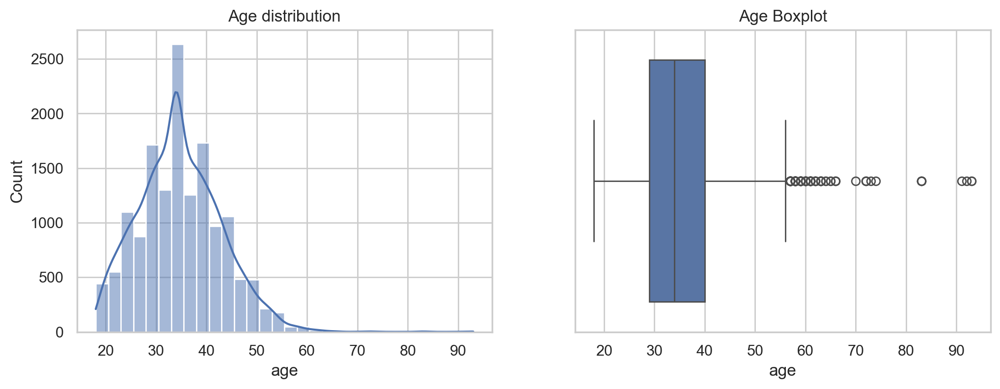

count    15108.000000
mean        34.723061
std          8.211885
min         18.000000
25%         29.000000
50%         34.000000
75%         40.000000
max         93.000000
Name: age, dtype: float64
Skewness: 0.46
Members aged 34, original data: 710 | cleaned data: 1371


In [110]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["age"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age distribution")
sns.boxplot(x=df["age"], ax=axes[1])
axes[1].set_title("Age Boxplot")
plt.show()

print(df["age"].describe())
print("Skewness:", round(df["age"].skew(), 2))

# How many ages of 34 come from the cleaning? (it replaced missing and invalid ages by the median)
raw_ages = pd.read_csv(data_path, sep=";").drop_duplicates()["age"]
print("Members aged 34, original data:", (raw_ages == 34).sum(), "| cleaned data:", (df["age"] == 34).sum())

The mean and median are almost the same and the distribution is only slightly skewed to the right (skewness of 0.46).

The interquartile range goes from 29 to 40 years, which means that half of the customers are in this range. 34 is the most common age, but this is partly an effect of the cleaning: missing and invalid ages were replaced by the median, which almost doubles the number of members aged 34.

75% of the members are 40 or younger. The age of 93 is the furthest outlier, which doesn't seem very plausible in this context.

### 13.2 Gender, Industry, Country

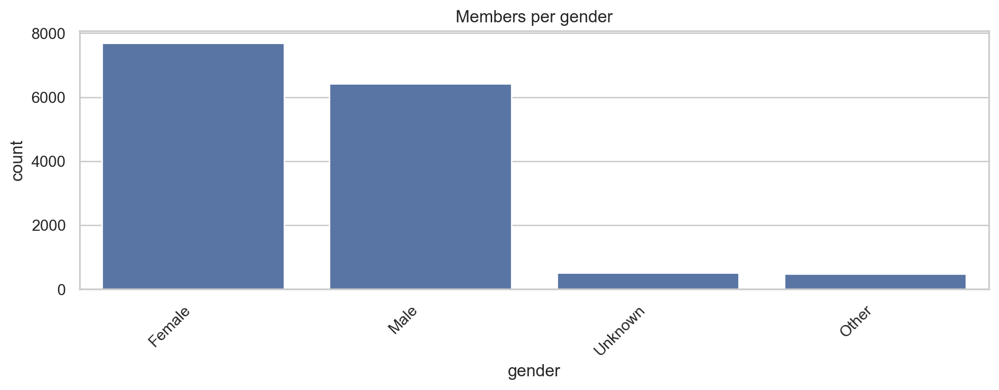

gender
Female     0.509
Male       0.425
Unknown    0.034
Other      0.032
Name: proportion, dtype: float64


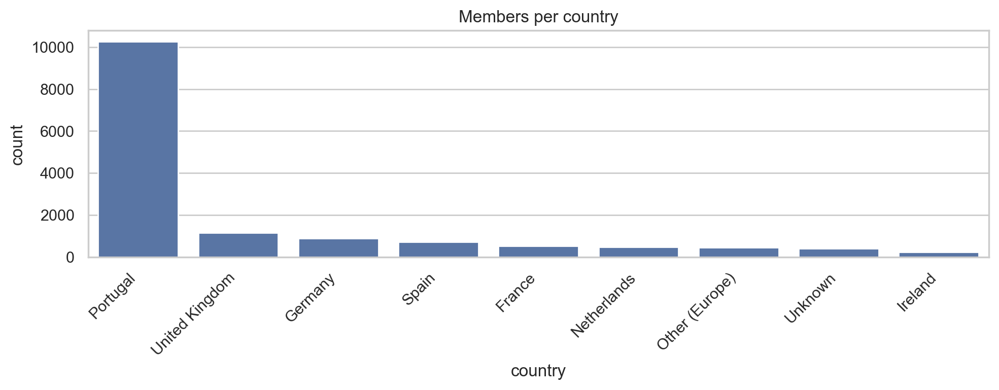

country
Portugal          0.680
United Kingdom    0.076
Germany           0.058
Spain             0.047
France            0.035
Netherlands       0.032
Other (Europe)    0.029
Unknown           0.027
Ireland           0.016
Name: proportion, dtype: float64


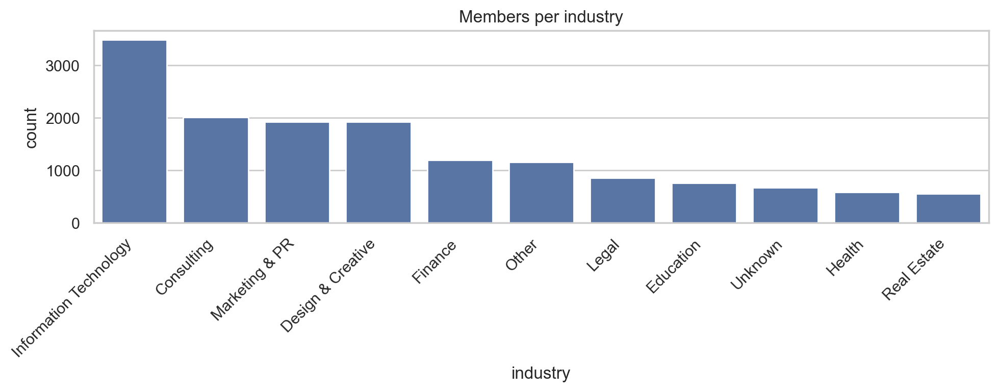

industry
Information Technology    0.231
Consulting                0.133
Marketing & PR            0.127
Design & Creative         0.127
Finance                   0.079
Other                     0.077
Legal                     0.057
Education                 0.050
Unknown                   0.044
Health                    0.038
Real Estate               0.036
Name: proportion, dtype: float64


In [111]:
for col in ["gender", "country", "industry"]:
    plt.figure(figsize=(10, 4))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Members per {col}")
    plt.tight_layout()
    plt.show()
    print(df[col].value_counts(normalize=True).round(3))

There's a small feminine majority.

Portugal is clearly the most common country which makes sense.

The biggest industry is Information Technology with almost twice as the next, Consulting.

### 13.3 Lifetime Value, Visits and Age by Plan Tier

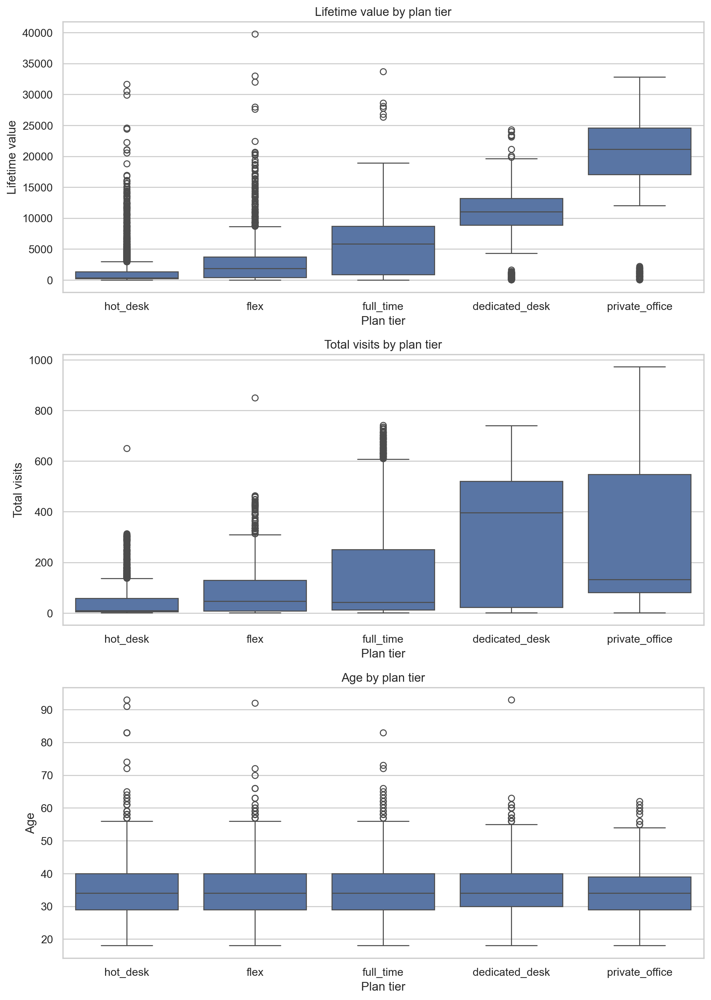

In [112]:
# Generate a multi-panel boxplot figure comparing lifetime value, total visits, and age distributions across plan tiers
fig, axes = plt.subplots(3, 1, figsize=(10, 14))

for ax, col, label in zip(axes,
                          ["lifetime_value", "total_visits", "age"],
                          ["Lifetime value", "Total visits", "Age"]):
    sns.boxplot(data=df, x="plan_tier", y=col, order=p_order, ax=ax)
    ax.set_title(f"{label} by plan tier")
    ax.set_xlabel("Plan tier")
    ax.set_ylabel(label)

# Compute and display median values for key metrics grouped by plan tier
plt.tight_layout()
plt.show()

In [113]:
print(df.groupby("plan_tier")[["lifetime_value", "total_visits", "age"]]
        .median().loc[p_order].round(1))

                lifetime_value  total_visits   age
plan_tier                                         
hot_desk                 357.2          10.0  34.0
flex                    1847.8          47.0  34.0
full_time               5868.5          42.0  34.0
dedicated_desk         11045.8         396.0  34.0
private_office         21161.2         133.0  34.0


- Lifetime value rises with the price of the plan, from about 360 in hot desk to 21,200 in private office.
- As for visits the median peaks at dedicated desk (396) and drops to 133 in private office.
- The age is identical trough all plans, with a median of 34.

### 13.4 Plan and Account

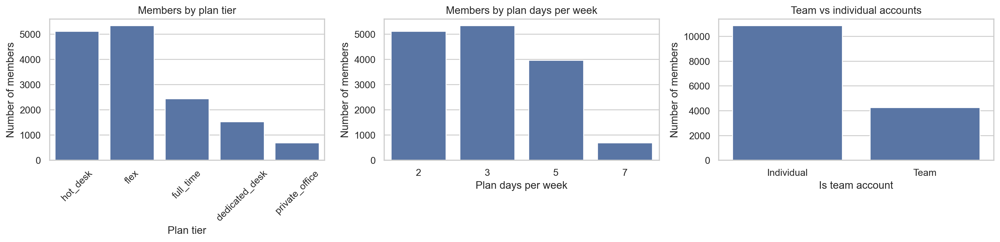

In [114]:
# Generate a multi-panel countplot figure showing the distributions of plan tiers, plan days per week, and account types
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df, x="plan_tier", order=p_order, ax=axes[0])
axes[0].set_title("Members by plan tier")
axes[0].set_xlabel("Plan tier")
axes[0].set_ylabel("Number of members")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="plan_days_per_week", ax=axes[1])
axes[1].set_title("Members by plan days per week")
axes[1].set_xlabel("Plan days per week")
axes[1].set_ylabel("Number of members")

sns.countplot(data=df, x="is_team_account", ax=axes[2])
axes[2].set_title("Team vs individual accounts")
axes[2].set_xlabel("Is team account")
axes[2].set_ylabel("Number of members")
axes[2].set_xticks([0, 1], ["Individual", "Team"])

plt.tight_layout()
plt.show()

The most frequent plans are flex and hot desk, and the rarest is private office, as expected. Plan days per week follow the plans: 3 and 2 days are the most frequent, followed by 5 days, with 7 days being the rarest.

Most customers have an individual account.

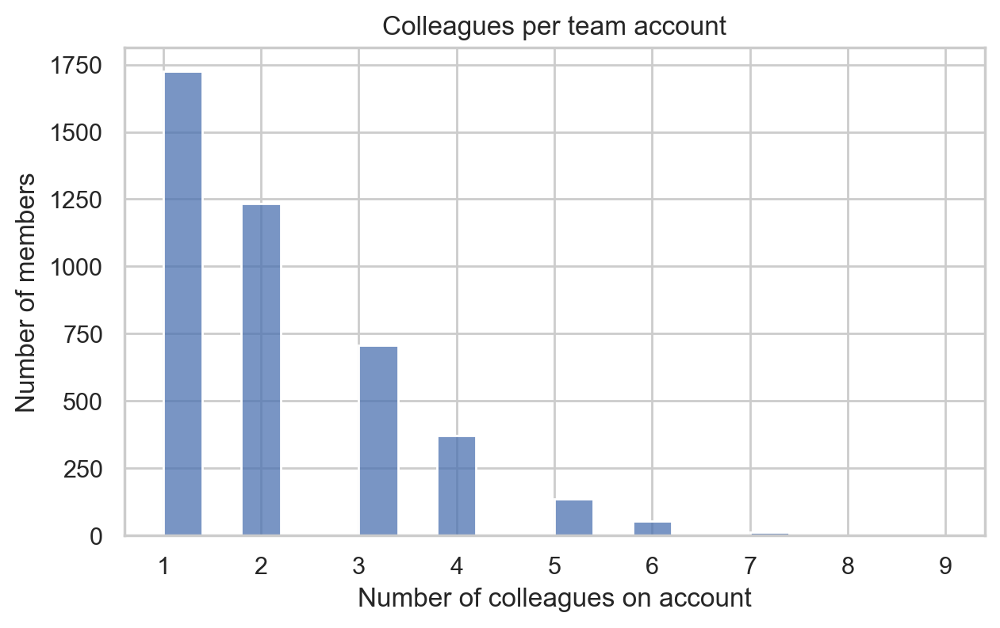

count    4248.000000
mean        2.104755
std         1.232782
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: n_colleagues_on_account, dtype: float64
Team members: 4248 (28.1% of the members)
{1.0: 0.406, 2.0: 0.29, 3.0: 0.167}


In [115]:
team = df[df["is_team_account"]]

plt.figure(figsize=(7, 4))
sns.histplot(team["n_colleagues_on_account"], bins=20)
plt.title("Colleagues per team account")
plt.xlabel("Number of colleagues on account")
plt.ylabel("Number of members")
plt.show()

print(team["n_colleagues_on_account"].describe())
print("Team members:", len(team), f"({len(team) / len(df):.1%} of the members)")
print(team["n_colleagues_on_account"].value_counts(normalize=True).sort_index().round(3).head(3).to_dict())

There are 4248 members in team accounts, about 28% of the customers.
The most common case is 1 colleague per team account (which means a team account of 2), and the median is 2 colleagues.

## 14. Time trends

### 14.1 New members per month

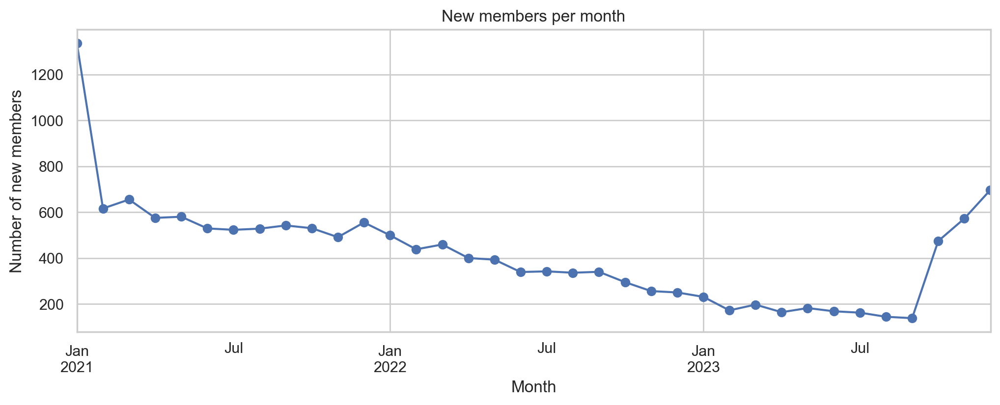

In [116]:
# Compute and plot the monthly count of new member sign-ups
new_per_month = df.groupby(df["membership_start"].dt.to_period("M")).size()

new_per_month.plot(figsize=(12, 4), marker="o")
plt.title("New members per month")
plt.xlabel("Month")
plt.ylabel("Number of new members")
plt.show()

It is very visible that the month with the most new members is January 2021. It may be the start of the observation window: members who already existed before were probably recorded with a start date in that month. If so, they are not real new clients.

There's a gradual fall from early 2021 to September 2023, from about 600 to fewer than 200 new members per month.

Finally, there's a rise in the last 3 months of 2023, reaching almost 700 new members in December. It could be related to a successful campaign, but the data does not show the cause, so this is only a hypothesis.

### 14.2 Active members per month

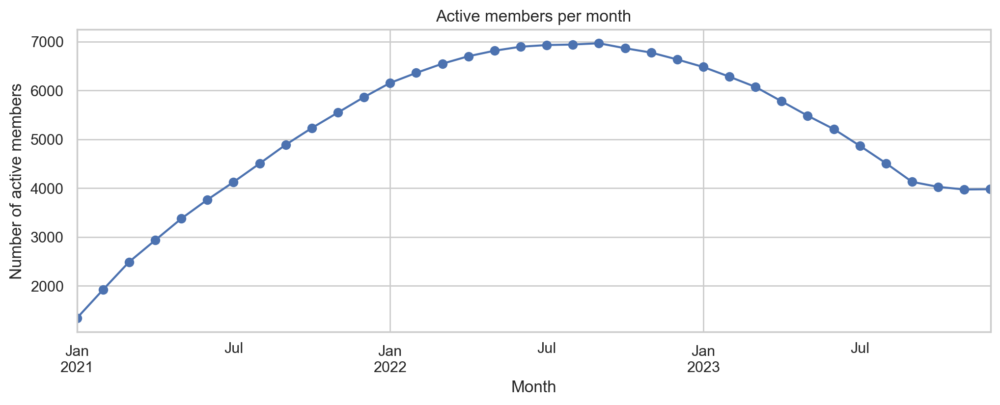

2023-12    3976
Freq: M, dtype: int64
Peak: 2022-09 6964
Months with more members leaving than joining: ['2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11']


In [117]:
# Construct a monthly time series of new joiners and departures to compute cumulative active members
months = pd.period_range(df["membership_start"].min().to_period("M"),
                         pd.Timestamp("2023-12-01").to_period("M"), freq="M")

joined = df.groupby(df["membership_start"].dt.to_period("M")).size().reindex(months, fill_value=0)
left_m = (df.dropna(subset=["membership_end"])
            .groupby(df["membership_end"].dt.to_period("M")).size()
            .reindex(months, fill_value=0))

active_per_month = (joined - left_m).cumsum()

active_per_month.plot(figsize=(12, 4), marker="o")
plt.title("Active members per month")
plt.xlabel("Month")
plt.ylabel("Number of active members")
plt.show()

print(active_per_month.tail(1))
print("Peak:", active_per_month.idxmax(), active_per_month.max())
print("Months with more members leaving than joining:", list((left_m > joined)[lambda s: s].index.astype(str)))

Active members grow steadily from January 2021 to a peak of 6,964 in September 2022, and then decline through 2023.

By the end of December 2023 we have 3,976 active members (3,902 after the 74 members who left on the extraction date, 2024-01-01). From October 2022 to November 2023, more members left than joined in every month.

We should read this with care: members who left before 2021 are not in the data, so the growth of 2021 is overstated, and the change at the end of 2023 needs to be confirmed with ACDC (see the cohorts below).

### 14.3 Members leaving per month

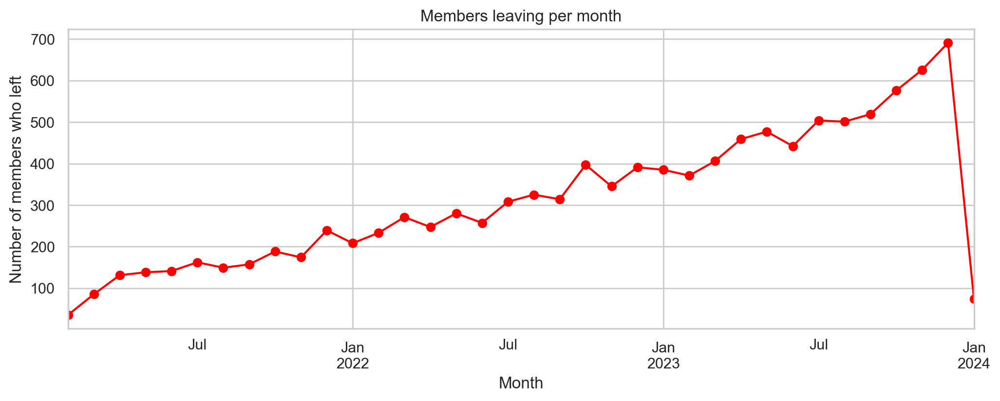

Members who left on the extraction date (January 2024 has only this day): 74


In [118]:
# Compute and plot monthly member churn rates
left = df.dropna(subset=["membership_end"])
left_per_month = left.groupby(left["membership_end"].dt.to_period("M")).size()

left_per_month.plot(figsize=(12, 4), marker="o", color="red")
plt.title("Members leaving per month")
plt.xlabel("Month")
plt.ylabel("Number of members who left")
plt.show()

# Highlight partial data boundary on the extraction date
print("Members who left on the extraction date (January 2024 has only this day):", left_per_month.loc["2024-01"])

The number of members leaving per month increases gradually through the period. Part of this is expected, because there are more members who can leave as the base grows, and members who left before 2021 are not in the data.

The drop at the end of the chart is not a real change: January 2024 has only one day of data, the extraction date.

### 14.4 Days with membership

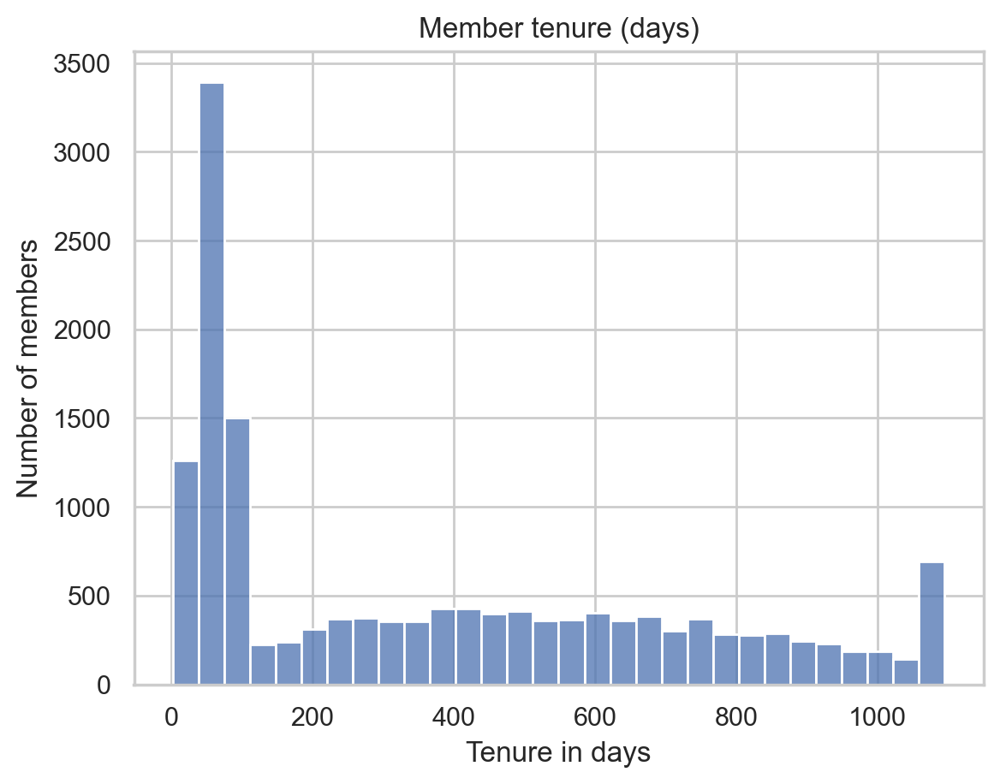

count    15108.000000
mean       374.094586
std        338.607673
min          2.000000
25%         65.000000
50%        282.000000
75%        635.000000
max       1095.000000
Name: tenure_days, dtype: float64


In [119]:
# Calculate total membership tenure in days and visualize its distribution
end = df["membership_end"].fillna(extraction_date)
df["tenure_days"] = (end - df["membership_start"]).dt.days

sns.histplot(df["tenure_days"], bins=30)
plt.title("Member tenure (days)")
plt.xlabel("Tenure in days")
plt.ylabel("Number of members")
plt.show()

print(df["tenure_days"].describe())

The mean member tenure is 374 days, and there is a lot of deviation between the values.

75% of the members stayed up to 635 days, and only 25% stayed 635 days or more. Half of the members stayed up to 282 days.

### 14.5 Member cohorts

In [120]:
# Define quarterly membership cohorts and aggregate key performance metrics (churn rate, tenure, lifetime value, and premium share)
df["cohort"] = df["membership_start"].dt.to_period("Q").astype(str)
df["is_premium"] = df["plan_tier"].isin(["dedicated_desk", "private_office"])

cohort_summary = df.groupby("cohort").agg(
    members=("member_id", "count"),
    churn_rate=("membership_end", lambda s: s.notna().mean()),
    median_tenure_days=("tenure_days", "median"),
    mean_ltv=("lifetime_value", "mean"),
    premium_share=("is_premium", "mean"),
).round(2)
print(cohort_summary)

        members  churn_rate  median_tenure_days  mean_ltv  premium_share
cohort                                                                  
2021Q1     2607        0.73               825.0   9436.34           0.35
2021Q2     1684        0.87               527.5   5918.45           0.20
2021Q3     1593        0.83               511.0   5284.87           0.16
2021Q4     1576        0.79               469.0   4410.40           0.14
2022Q1     1396        0.81               399.0   3679.07           0.11
2022Q2     1132        0.81               327.0   2941.09           0.08
2022Q3     1018        0.84               227.0   2052.17           0.05
2022Q4      801        0.87               101.0   1501.76           0.04
2023Q1      600        0.97                79.0    862.02           0.00
2023Q2      514        0.96                71.0    574.76           0.00
2023Q3      444        0.96                64.0    392.97           0.00
2023Q4     1743        0.10                38.0    

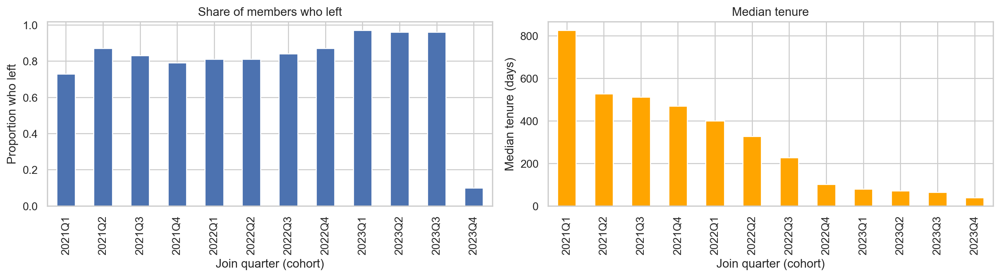

In [121]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

cohort_summary["churn_rate"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Share of members who left")
axes[0].set_xlabel("Join quarter (cohort)")
axes[0].set_ylabel("Proportion who left")

cohort_summary["median_tenure_days"].plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Median tenure")
axes[1].set_xlabel("Join quarter (cohort)")
axes[1].set_ylabel("Median tenure (days)")

plt.tight_layout()
plt.show()

Older cohorts stay a lot longer: the median tenure and the average lifetime value drop in each newer cohort. We must keep in mind that recent cohorts have had less time to stay and accumulate value.

The share of members who left is high in every cohort except 2023Q4, because most of those members joined only a few weeks before the extraction date.

The cohorts from 2023Q1 to 2023Q3 look unusual: 96% to 97% of their members have already left, and the share of premium plans (`dedicated_desk`, `private_office`) falls to 0% or close to it, before returning in 2023Q4. This sudden change could come from the way the data was built, so it should be confirmed with ACDC before being presented as real behaviour.

## 15. Numeric relationships

In [122]:
# tenure_days now exists, so we update the list (is_premium is a flag, so it stays out of it)
metric_features = df.select_dtypes(include="number").columns.tolist()

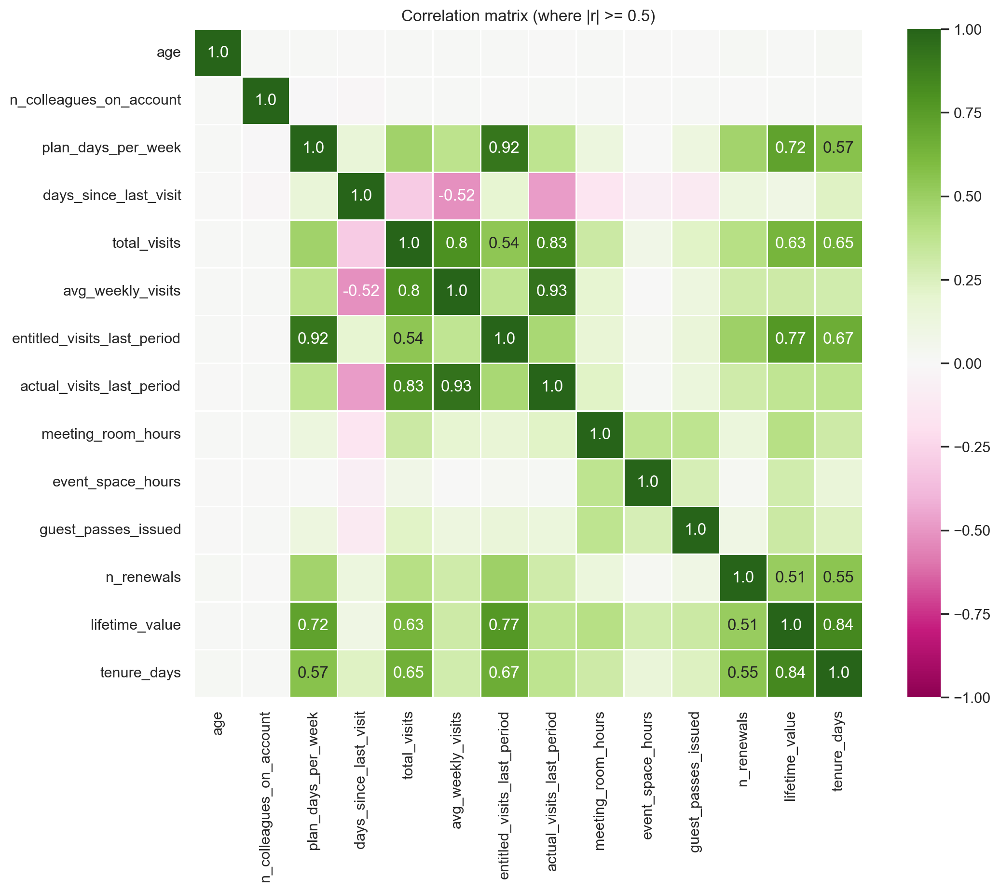

In [123]:
corr = df[metric_features].corr().round(2)

# Annotate only the strong values
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=np.where(corr.abs() >= 0.5, corr.values, ""), fmt="s",
            cmap="PiYG", center=0, vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Correlation matrix (where |r| >= 0.5)")
plt.show()

Only correlations with |r| >= 0.5 are annotated, to keep the heatmap readable.

There are two separate groups of strong correlations. Visit variables go together: `actual_visits_last_period` with `avg_weekly_visits` (0.93) and `total_visits` (0.83). The plan variables go together: `plan_days_per_week` with `entitled_visits_last_period` (0.92). Between the two groups the correlation is weak or moderate (0.37 between `plan_days_per_week` and `actual_visits_last_period`), so having more days available does not mean coming more.

`lifetime_value` is strongly correlated with `tenure_days` (0.84), while age, team size, meeting room, event space and guest pass usage show no strong linear relationships with the other variables.

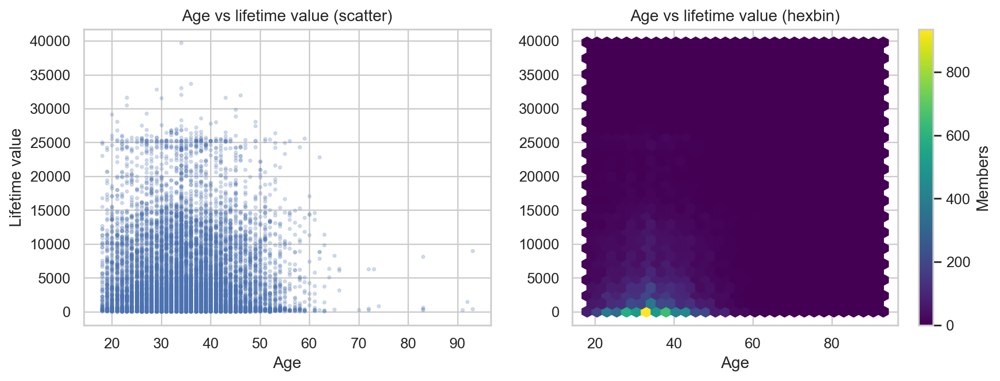

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df["age"], df["lifetime_value"], alpha=0.2, s=5)
axes[0].set_title("Age vs lifetime value (scatter)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Lifetime value")

hb = axes[1].hexbin(df["age"], df["lifetime_value"], gridsize=30, cmap="viridis")
axes[1].set_title("Age vs lifetime value (hexbin)")
axes[1].set_xlabel("Age")
fig.colorbar(hb, ax=axes[1], label="Members")
plt.show()

Age and lifetime value don't seem to be correlated. Members of all ages have very different values. The highest concentration is between ages 25 and 45 with a low lifetime value, and there are very few members above 60.

This makes sense: the heatmap shows that age has no strong correlation with the other variables.

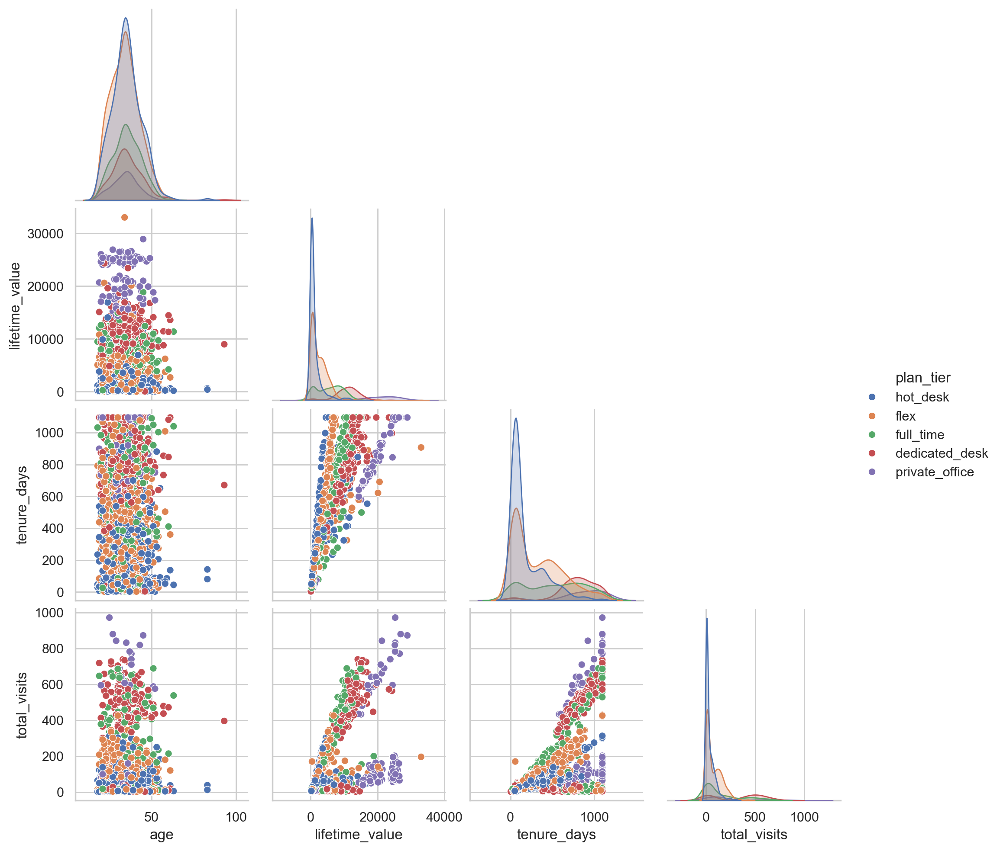

In [125]:
cols = ["age", "lifetime_value", "tenure_days", "total_visits", "plan_tier"]
sns.pairplot(df[cols].sample(2000, random_state=1),
             hue="plan_tier", hue_order=p_order, corner=True)
plt.show()

This pair plot shows that the plan tier separates members mainly by lifetime value and tenure days.

As expected, hot desk and flex concentrate on low values, while dedicated desk and private office reach the highest values.


## 16. Plan profiles

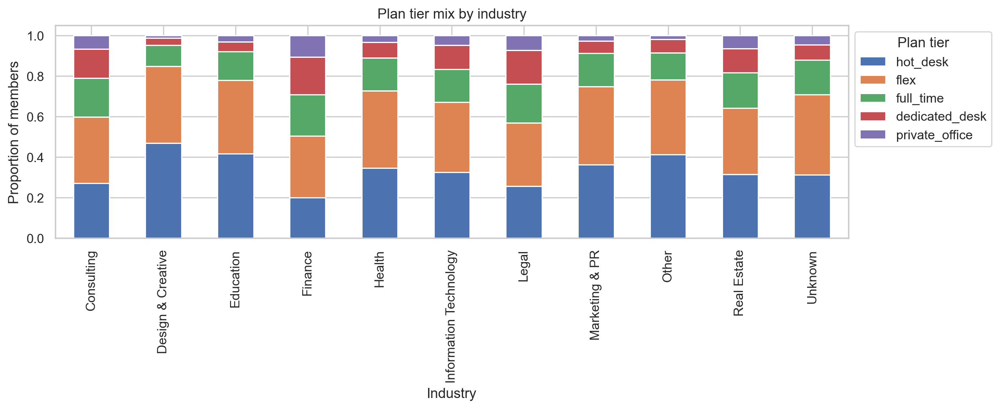

% in dedicated_desk or private_office:
industry
Design & Creative          4.8
Education                  7.9
Other                      8.6
Marketing & PR             8.8
Health                    11.0
Unknown                   12.0
Information Technology    16.7
Real Estate               18.3
Consulting                21.0
Legal                     23.9
Finance                   29.1


In [126]:
# Compute and plot the normalized proportion of plan tiers across different industries
ct = pd.crosstab(df["industry"], df["plan_tier"], normalize="index")[p_order]
ct.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Plan tier mix by industry")
plt.xlabel("Industry")
plt.ylabel("Proportion of members")
plt.legend(title="Plan tier", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print("% in dedicated_desk or private_office:")
print((ct[["dedicated_desk", "private_office"]].sum(axis=1) * 100).round(1).sort_values().to_string())

Design & Creative and Education have less expensive plans (hot desk at about 45%), and only 4.8% and 7.9% of their members have a premium plan.

On the other hand, Finance and Legal have higher tier plans (29.1% and 23.9% in private office or dedicated desk).

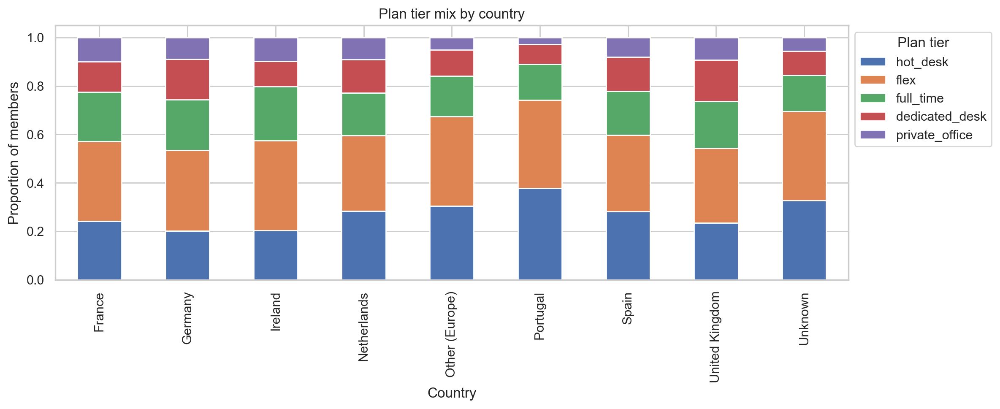

% in hot_desk or flex: {'Germany': 53.5, 'United Kingdom': 54.3, 'France': 57.2, 'Ireland': 57.4, 'Netherlands': 59.5, 'Spain': 59.7, 'Other (Europe)': 67.3, 'Unknown': 69.5, 'Portugal': 74.2}
% in dedicated_desk or private_office:
country
Portugal          11.0
Unknown           15.5
Other (Europe)    15.9
Ireland           20.3
Spain             22.1
France            22.6
Netherlands       22.9
Germany           25.7
United Kingdom    26.2


In [127]:
# Compute and plot the normalized proportion of plan tiers across different countries
ct = pd.crosstab(df["country"], df["plan_tier"], normalize="index")[p_order]
ct.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Plan tier mix by country")
plt.xlabel("Country")
plt.ylabel("Proportion of members")
plt.legend(title="Plan tier", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print("% in hot_desk or flex:", (ct[["hot_desk", "flex"]].sum(axis=1) * 100).round(1).sort_values().to_dict())
print("% in dedicated_desk or private_office:")
print((ct[["dedicated_desk", "private_office"]].sum(axis=1) * 100).round(1).sort_values().to_string())

Portugal has the highest percentage of low-cost plans (74.2% in hot desk or flex) and the lowest of premium plans (11.0%). The United Kingdom and Germany have the most members in dedicated desk and private office (26.2% and 25.7%).

## 17. Redundant variables

In [128]:
corr_abs = df[metric_features].corr().abs()
pairs = (corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False))
print(pairs[pairs > 0.8])

avg_weekly_visits   actual_visits_last_period      0.932189
plan_days_per_week  entitled_visits_last_period    0.917123
lifetime_value      tenure_days                    0.844128
total_visits        actual_visits_last_period      0.826656
                    avg_weekly_visits              0.800994
dtype: float64


These are the five pairs of variables with a correlation above 0.8.

They form three groups:

- **Visit frequency:** `avg_weekly_visits`, `actual_visits_last_period`, `total_visits`. These are redundant, although they cover different periods, so we would keep `avg_weekly_visits`, which does not depend on the length of the membership.
- **Contracted days:** `plan_days_per_week`, `entitled_visits_last_period`. These are redundant, and keeping one is enough.
- **Value:** `lifetime_value`, `tenure_days`. These are correlated because revenue accumulates with time, but they measure different things, so we would not simply drop one. It is better to use `tenure_days` together with a rate such as `ltv_per_month`.

The final choice should be made before clustering, also considering the features created in the behaviour analysis.

## 18. Implications for clustering

Our descriptive analysis shows that the ACDC member base is quite homogeneous in age and gender (median age of 34 in every plan, partly an effect of the imputation, and about half of the members are women). The country is mostly Portugal, but it is related to the plan, so it may help to profile the segments even if it should not build them.

On the other hand, behaviour and value differ. Lifetime value rises with plan tier, while visits don't (private office members pay the most but have a median of only 133 visits, against 396 for dedicated desk).

Tenure and cohorts also point to distinct profiles, with short stays on one side and long-term members on the other.

Several variables are redundant, so we have to make that decision before clustering.

Together, these findings suggest that clusters will be driven by usage, plan value and tenure rather than by demographics.

We should also be careful about observation-window effects, so that they are not mistaken for real segments.

# Part 3: Behaviour, value and feature engineering

**Scope:** usage, add-ons, value, engineered features and a first look at possible groups.

## 19. Preparation

In [129]:
# Day the data was extracted (found in section 5.6)
EXTRACTION_DATE = extraction_date

# Plan tiers in the order given by the metadata (hot_desk < flex < dedicated_desk < full_time < private_office)
TIER_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

### Functions

All functions are defined here, at the beginning, and called later in the notebook.

| Function | What it does |
|---|---|
| `plot_hist_box(data, features, title)` | Histogram (top row) and box plot (bottom row) for each feature |
| `engineer_features(data, extraction_date)` | Creates all the engineered features of section 23 and returns a new dataframe |

In [130]:
def plot_hist_box(data, features, title, bins=30):
    '''Histogram (top row) and box plot (bottom row) of each feature, side by side.'''
    fig, axes = plt.subplots(2, len(features), figsize=(5 * len(features), 7), tight_layout=True, squeeze=False)
    for i, feat in enumerate(features):
        sns.histplot(data[feat], bins=bins, ax=axes[0, i])     # shape of the distribution
        axes[0, i].set_title(feat)
        sns.boxplot(x=data[feat], ax=axes[1, i])               # quartiles and outliers
    fig.suptitle(title)
    plt.show()


def engineer_features(data, extraction_date):
    '''Return a copy of `data` with the engineered features (formulas and justification in section 23).

    Ratios use NaN (not inf) when the denominator is 0, so those members are simply "undefined" for that feature.
    '''
    out = data.copy()
    addons = [c for c in out.columns if c.startswith("uses_")]

    # Loyalty: time as a member. Active members (no end date) are measured up to the extraction date.
    out["tenure_days"] = (out["membership_end"].fillna(extraction_date) - out["membership_start"]).dt.days

    # Recency at the extraction date, from the last badge swipe. (days_since_last_visit stops at membership_end
    # for members who left, so it is not a comparable recency for everyone.)
    out["recency_days"] = (extraction_date - out["last_badge_swipe"]).dt.days

    # Share of the entitled visits that the member really used (0 entitled visits -> undefined)
    out["utilization_rate"] = out["actual_visits_last_period"] / out["entitled_visits_last_period"].replace(0, np.nan)

    # Revenue per month of membership (tenure <= 0 -> undefined)
    tenure_months = (out["tenure_days"] / 30.44).where(out["tenure_days"] > 0)     # 30.44 = average days in a month
    out["ltv_per_month"] = out["lifetime_value"] / tenure_months

    # Revenue per month compared with the usual value of the member's tier:
    # ~1 = pays just the plan, >1 = pays for more than the plan (add-ons)
    # Imputed revenue is plan price x months, so it says nothing here: those members stay undefined
    real_ltv_per_month = out["ltv_per_month"].where(~out["ltv_imputed"])
    out["ltv_vs_tier"] = real_ltv_per_month / real_ltv_per_month.groupby(out["plan_tier"]).transform("median")

    # How many different add-ons the member uses
    out["n_addons"] = out[addons].sum(axis=1)

    # Hours of meeting/event rooms per visit: separates "office/events" users from "just a desk" users
    out["hours_per_visit"] = (out["meeting_room_hours"] + out["event_space_hours"]) / out["total_visits"].replace(0, np.nan)

    # Hours and passes accumulate with time, so we also measure them per month (under one month -> undefined)
    full_months = tenure_months.where(tenure_months >= 1)
    out["addon_hours_per_month"] = (out["meeting_room_hours"] + out["event_space_hours"]) / full_months
    out["guest_passes_per_month"] = out["guest_passes_issued"] / full_months

    # Active (no end date) vs churned
    out["is_active"] = out["membership_end"].isna().astype(int)

    # Plan tier as a number (metadata order: hot_desk=1 ... private_office=5)
    out["plan_tier_ord"] = out["plan_tier"].map({t: i + 1 for i, t in enumerate(TIER_ORDER)})

    # Plan tier as a number in price order (median revenue per month of each tier, 1 = cheapest)
    out["plan_price_rank"] = out["plan_tier"].map(out.groupby("plan_tier")["ltv_per_month"].median().rank()).astype(int)

    # RFM scores, 1 (worst) to 5 (best). rank(method="first") avoids duplicate bin edges in qcut.
    # Recency: FEWER days since the last visit is better, so its labels are reversed.
    out["r_score"] = pd.qcut(out["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
    out["f_score"] = pd.qcut(out["avg_weekly_visits"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    out["m_score"] = pd.qcut(out["lifetime_value"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    out["rfm_score"] = out[["r_score", "f_score", "m_score"]].sum(axis=1)

    return out

### Feature groups

**What we do in this step:** we prepare the cleaned dataset (`df_clean`) for the analysis of behaviour and value.

1. **Convert the add-on flags to numbers.** The `uses_*` columns (meeting rooms, event space, guest passes, print, mail handling, phone booths, day passes, storage and bike locker) and `is_team_account` are stored as True/False. We convert them to 1/0 so that we can sum them (for example, how many add-ons each member uses) and compute correlations.
2. **Split the variables into two groups**, following standard exploratory groupings.
   - *Non-metric features*: categories and flags (`gender`, `country`, `industry`, `plan_tier`, `is_team_account` and the add-on flags). It does not make sense to average them.
   - *Metric features*: numeric variables (`age`, visits, hours, renewals, `lifetime_value`, etc.). These are the ones we use in histograms, box plots and correlations.
3. **Check for missing values.** After the cleaning, the only column with missing values should be `membership_end`, which is empty on purpose for active members. If another column appears, we need to go back to the cleaning step.

In [131]:
# uses_* flags are True/False in the cleaned file -> make them 0/1 integers so they can be summed and correlated
addon_cols = [c for c in df_clean.columns if c.startswith("uses_")]
df_clean[addon_cols] = df_clean[addon_cols].astype(int)
df_clean["is_team_account"] = df_clean["is_team_account"].astype(int)

# Split: non-metric (categories/flags) vs metric (numbers)
non_metric_features = ["gender", "country", "industry", "plan_tier", "is_team_account"] + addon_cols
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "total_visits", "avg_weekly_visits",
                   "days_since_last_visit", "entitled_visits_last_period", "actual_visits_last_period",
                   "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
print("add-on flags:", addon_cols)

# After the cleaning, only membership_end (empty = active member) should still have missing values
print("missing values left (only membership_end = active members is expected):")
print(df_clean.isna().sum()[lambda s: s > 0])

add-on flags: ['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker']
missing values left (only membership_end = active members is expected):
membership_end    3902
dtype: int64


### Impact of the data cleaning on this analysis

The cleaned dataset (`df_clean`) differs from the raw data in ways that affect the behaviour and value analysis:

- **Active members have no end date.** The placeholder `1970-01-01` in `membership_end` was replaced by a missing value, which now means that the membership is still active.
- **`days_since_last_visit` is not a common recency measure.** It was recalculated up to `membership_end` for members who left, and up to the extraction date (2024-01-01) for active members. For churned members it therefore does not measure recency at the extraction date, so we also compute `recency_days` from `last_badge_swipe`.
- **Part of `lifetime_value` is estimated.** About 18.4% of the values were missing or invalid and were imputed as *monthly plan price × months of membership*. They are marked in `ltv_imputed`. These values add no new information and they inflate the relationship between `lifetime_value`, plan tier and tenure, so we leave them out of `ltv_vs_tier`.
- **Part of the add-on usage is estimated.** Missing hours and passes of add-on users were filled with the median of the users with a similar tenure.
- **Tenure is a lower bound for some members.** Members who start on the first day of the data and active members can have a longer real membership than we see.
- **The plan tier order is not a price order.** The metadata lists `full_time` above `dedicated_desk`, but `dedicated_desk` has a higher monthly price. We keep this in mind when using `plan_tier` as an ordinal variable.

## 20. Usage

**Goal:** understand how often and how intensively members use the space, and whether they use what their plan entitles them to.

**What we analyse in this section:**
1. **Distribution of the usage variables** (`total_visits`, `avg_weekly_visits`, `days_since_last_visit`, `entitled_visits_last_period`, `actual_visits_last_period`). Histograms show the shape of each distribution and box plots show the quartiles and the outliers.
2. **Summary statistics** (mean, median, quartiles, minimum and maximum) to quantify what the plots show.
3. **Actual vs entitled visits in the last period.** Comparing the visits a member made with the visits the plan allows shows who uses less than they pay for. These members may be at risk of leaving.

**Why it matters for segmentation:** usage separates members who come every day from members who almost never come, even when they have the same plan. This is a behavioural signal that plan tier alone does not capture.

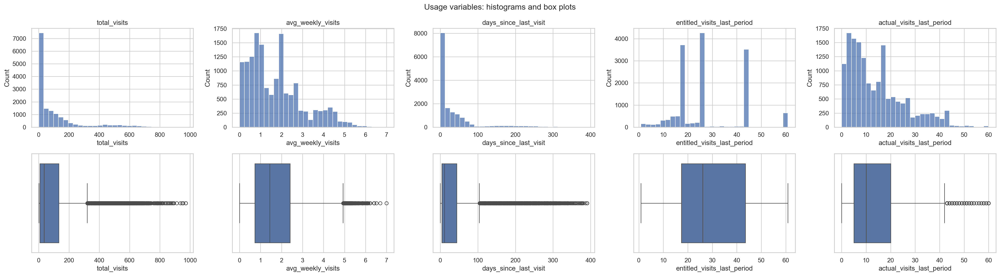

In [132]:
# Histogram and box plot of each usage variable (function defined in the Functions section)
usage_features = ["total_visits", "avg_weekly_visits", "days_since_last_visit",
                  "entitled_visits_last_period", "actual_visits_last_period"]

plot_hist_box(df_clean, usage_features, "Usage variables: histograms and box plots")

In [133]:
# Summary statistics of the usage variables: count, mean, std, min, quartiles (25/50/75%) and max
df_clean[usage_features].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
total_visits,15108.0,109.88,164.58,1.00,8.00,35.00,133.00,972.00
avg_weekly_visits,15108.0,1.72,1.29,0.00,0.73,1.44,2.41,7.00
days_since_last_visit,15108.0,37.74,61.53,0.00,4.00,11.00,44.00,391.00
entitled_visits_last_period,15108.0,27.41,13.28,0.87,17.39,26.09,43.48,60.87
actual_visits_last_period,15108.0,13.79,11.38,0.00,5.00,10.00,20.00,60.00


### Recency: active vs churned members

**What we do in this step:** `days_since_last_visit` stops at `membership_end`, so we compare it with the recency at the extraction date (`recency_days`), separately for active and churned members.

In [134]:
# days_since_last_visit stops at membership_end, so we compare it with the recency at the extraction date
recency_days = (EXTRACTION_DATE - df_clean["last_badge_swipe"]).dt.days
status = df_clean["membership_end"].isna().map({True: "active", False: "churned"})

pd.DataFrame({
    "members": status.value_counts(),
    "% of members": status.value_counts(normalize=True) * 100,
    "median days_since_last_visit": df_clean["days_since_last_visit"].groupby(status).median(),
    "median recency_days": recency_days.groupby(status).median(),
    "% not seen for 90+ days": (recency_days > 90).groupby(status).mean() * 100,
}).round(1)

,members,% of members,median days_since_last_visit,median recency_days,% not seen for 90+ days
membership_end,,,,,
active,3902,25.8,19.0,19.0,38.0
churned,11206,74.2,10.0,352.0,85.5


In [135]:
# Active members who have not come for more than 90 days, per plan tier
active = status == "active"
dormant_share = (recency_days[active] > 90).groupby(df_clean.loc[active, "plan_tier"]).mean() * 100
dormant_share.round(1).reindex(p_order).to_frame("% of active members not seen for 90+ days")

,% of active members not seen for 90+ days
plan_tier,
hot_desk,0.0
flex,34.1
full_time,62.6
dedicated_desk,60.5
private_office,0.0


### Main takeaways - usage

- **Visits are strongly right-skewed.** The median member made 35 visits in total, but the mean is 110 and the maximum is 972. Most members visit rarely and a small group visits very often.
- **Weekly frequency is low for most members.** The median is 1.4 visits per week and 75% of members have 2.4 visits per week or fewer. The histogram has several peaks (around 1 and 2), which suggests different usage patterns.
- **Most members are no longer here, and `days_since_last_visit` hides it.** Its median of 11 days looks recent, but 74.2% of the members have left and for them the count stops at their end date. At the extraction date, the median recency is 352 days for churned members and 19 days for active ones.
- **A large share of the active members has stopped coming.** 38.0% of them have not been seen for more than 90 days: 62.6% in `full_time`, 60.5% in `dedicated_desk`, 34.1% in `flex`, and none in `hot_desk` or `private_office`.
- **Entitled visits come in discrete values.** The histogram has clear spikes (around 17, 26, 43 and 61), which correspond to the plan tiers (2, 3, 5 and 7 days per week).
- **Members use about half of what they are entitled to.** On average, members made 13.8 visits in the last period out of 27.4 entitled (median 10 vs 26). Whether this signals that they will leave is tested below.
- **For segmentation:** use `recency_days` and not `days_since_last_visit`, which stops at the end date for members who left. Utilization should be kept separate from plan tier, because members with the same plan use the space very differently.

### Last period: actual vs entitled visits

**What we do in this step:** each hexagon counts members. The red line marks members who used exactly what their plan entitles them to. Members below the line used less than they could, and members above used more.

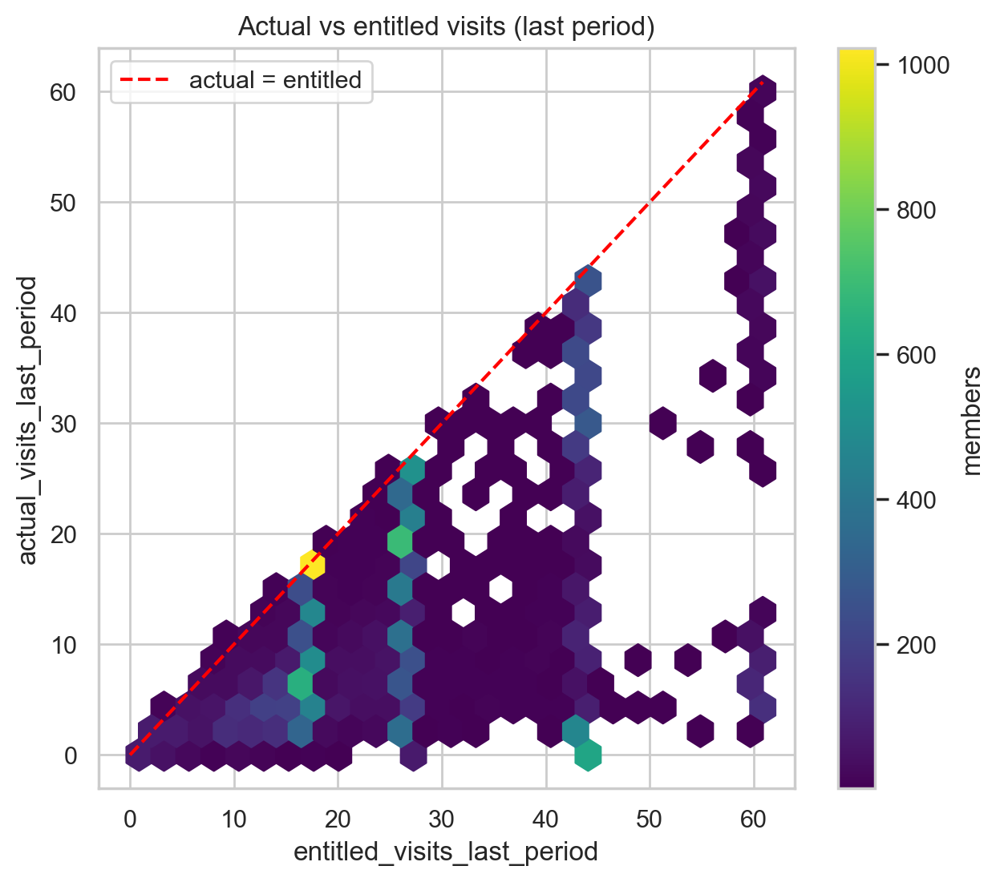

Share of members who exceeded their entitlement: 0.0 %


In [136]:
# Hexbin plot of entitled vs actual visits (hexagons are used instead of points because there are thousands of members)
fig, ax = plt.subplots(figsize=(7, 6))
hb = ax.hexbin(df_clean["entitled_visits_last_period"], df_clean["actual_visits_last_period"],
               gridsize=25, cmap="viridis", mincnt=1)

# Reference line: actual = entitled
lim = max(df_clean["entitled_visits_last_period"].max(), df_clean["actual_visits_last_period"].max())
ax.plot([0, lim], [0, lim], color="red", linestyle="--", label="actual = entitled")
ax.set_xlabel("entitled_visits_last_period")
ax.set_ylabel("actual_visits_last_period")
ax.set_title("Actual vs entitled visits (last period)")
ax.legend()
fig.colorbar(hb, ax=ax, label="members")
plt.show()

# Share of members above their entitlement
exceeded = (df_clean["actual_visits_last_period"] > df_clean["entitled_visits_last_period"]).mean() * 100
print("Share of members who exceeded their entitlement:", round(exceeded, 2), "%")

### Main takeaways - actual vs entitled visits

- **No member exceeded their entitlement (0.0%).** Every hexagon is on or below the red line, so the plan works as a ceiling on visits. As a consequence, `utilization_rate` (actual / entitled) goes from 0 to 1.
- **Entitlements form vertical stripes** (around 17, 26, 43 and 61 visits), one per plan (2, 3, 5 and 7 days per week). Within each stripe, actual use goes from almost zero to the maximum, so **the plan tier does not tell how much a member really uses the space**.
- **There is a dense group on the red line** at the lowest entitlement (around 17 visits, the 2-day plan): these members use almost everything they pay for.
- **There is another dense group close to zero** at around 43 visits (the 5-day plans): these members use almost nothing of what they pay for.
- **For segmentation:** utilization separates members who have the same plan, which is information that `plan_tier` alone does not capture.

### Is low use a sign that members leave?

**What we do in this step:** we compare the utilization of churned and active members **inside each tier**, because the tiers differ in both. We repeat it for members with at least 61 days, who had a complete last period (about 8.7 weeks).

In [137]:
utilization = df_clean["actual_visits_last_period"] / df_clean["entitled_visits_last_period"]
tenure_all = (df_clean["membership_end"].fillna(EXTRACTION_DATE) - df_clean["membership_start"]).dt.days
tier = df_clean["plan_tier"]
one_period = tenure_all >= 61     # a last period is about 8.7 weeks, so these members had a complete one

pd.DataFrame({
    "members": tier.value_counts(),
    "all": utilization.groupby(tier).mean(),
    "churned": utilization[~active].groupby(tier[~active]).mean(),
    "active": utilization[active].groupby(tier[active]).mean(),
    "churned (61+ days)": utilization[~active & one_period].groupby(tier[~active & one_period]).mean(),
    "active (61+ days)": utilization[active & one_period].groupby(tier[active & one_period]).mean(),
    "% using 90%+ of the plan": (utilization >= 0.9).groupby(tier).mean() * 100,
}).round(2).reindex(p_order)

,members,all,churned,active,churned (61+ days),active (61+ days),% using 90%+ of the plan
plan_tier,,,,,,,
hot_desk,5110,0.55,0.55,0.56,0.62,0.76,20.86
flex,5336,0.55,0.58,0.42,0.64,0.32,13.62
full_time,2440,0.41,0.51,0.25,0.56,0.19,5.45
dedicated_desk,1526,0.55,0.82,0.35,0.82,0.32,18.94
private_office,696,0.36,0.41,0.30,0.41,0.29,4.02


In [138]:
# Members with no visits at all in the last period
no_visits = df_clean["actual_visits_last_period"] == 0
print("Members with 0 visits in the last period:", no_visits.sum())
print(f"Of those, still active: {(no_visits & active).sum() / no_visits.sum():.1%}")
print("By tier:", tier[no_visits].value_counts().reindex(p_order).to_dict())

Members with 0 visits in the last period: 285
Of those, still active: 97.5%
By tier: {'hot_desk': 41, 'flex': 89, 'full_time': 86, 'dedicated_desk': 65, 'private_office': 4}


### Main takeaways - utilization and churn

- **Low use does not mark the members who left.** In four of the five tiers, churned members used more of their plan than active ones (`dedicated_desk` 0.82 vs 0.35, `flex` 0.58 vs 0.42, `full_time` 0.51 vs 0.25, `private_office` 0.41 vs 0.30). `hot_desk` is the exception (0.55 vs 0.56, and 0.62 vs 0.76 with a complete period). So the data does not support using low utilization as a churn signal.
- **The low use is among members who are still active.** 285 members made no visit in the last period, and 97.5% of them are active. This matches the 38.0% of active members not seen for more than 90 days.
- **This group has two possible readings:** members who keep paying without coming (a risk and an opportunity), or members who left without an end date being recorded. The data cannot separate the two, so it is a question for ACDC.
- **Limitation:** we only see the last period of each member, so this is a comparison at one moment, not the path of a member over time, and it does not show cause and effect.
- **For segmentation:** low utilization should not be treated as a churn label, so `is_active` should not be read as "will leave". The members who are active but have stopped coming are better profiled as a separate group (the dormant group in section 24) than mixed with the rest.

## 21. Add-ons

**Goal:** understand which extra services members use, which ones are used together, and how much they use the meeting and event rooms.

**What we analyse in this section:**
1. **Adoption rate** of each add-on (% of members who use it).
2. **Co-usage and correlation** between add-ons, to see which ones go together.
3. **Meeting-room and event-space hours**, to see how intensively the rooms are used.
4. **Overview numbers (KPIs)** that summarise the member base.

**Why it matters for segmentation:** add-ons are a sign of how members use the space (just a desk vs an office with meetings and events), and they are paid on top of the plan.

### Adoption rate

**What we do in this step:** the mean of a 0/1 flag is the share of members who use that add-on, so we compute the mean of each `uses_*` column and sort the add-ons from the most to the least used.

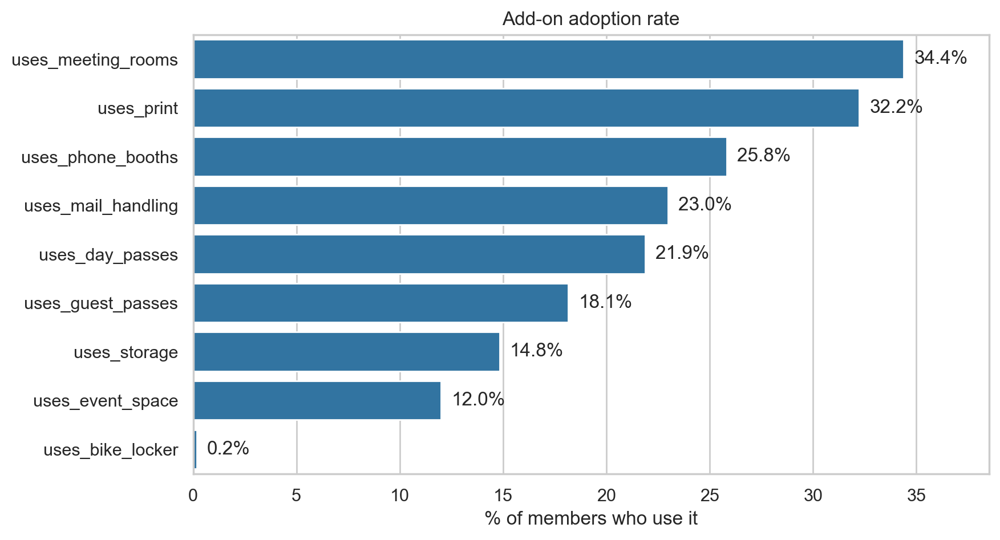

In [139]:
# Adoption rate = % of members who use each add-on (the mean of a 0/1 flag is the share of ones)
adoption = df_clean[addon_cols].mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=adoption.values, y=adoption.index, ax=ax, color="tab:blue")
ax.set_xlabel("% of members who use it")
ax.set_ylabel("")
ax.set_xlim(0, adoption.max() * 1.12)     # room for the labels
ax.set_title("Add-on adoption rate")

# write the percentage at the end of each bar
for p, v in zip(ax.patches, adoption.values):
    ax.text(v + 0.5, p.get_y() + p.get_height() / 2, f"{v:.1f}%", va="center")
plt.show()

**Reading the chart:**
- **No add-on is used by the majority of members.** The most used are meeting rooms (34.4%) and print (32.2%), so about one member in three uses each of them.
- **Phone booths (25.8%), mail handling (23.0%) and day passes (21.9%)** form a middle group used by roughly one member in four or five.
- **Guest passes (18.1%), storage (14.8%) and event space (12.0%) are niche services.**
- **The bike locker is almost not used (0.2%).** A variable that is almost always 0 carries very little information, so it is unlikely to help to separate groups and is a candidate to leave out of the clustering.
- The percentages do not add up to 100% because each member can use several add-ons.

### Which add-ons are used together?

**What we do in this step:** we use two views. The *co-usage matrix* shows the % of all members who use both add-ons (it can be high just because both are popular). The *correlation* tells if two add-ons go together **more than expected by chance**.

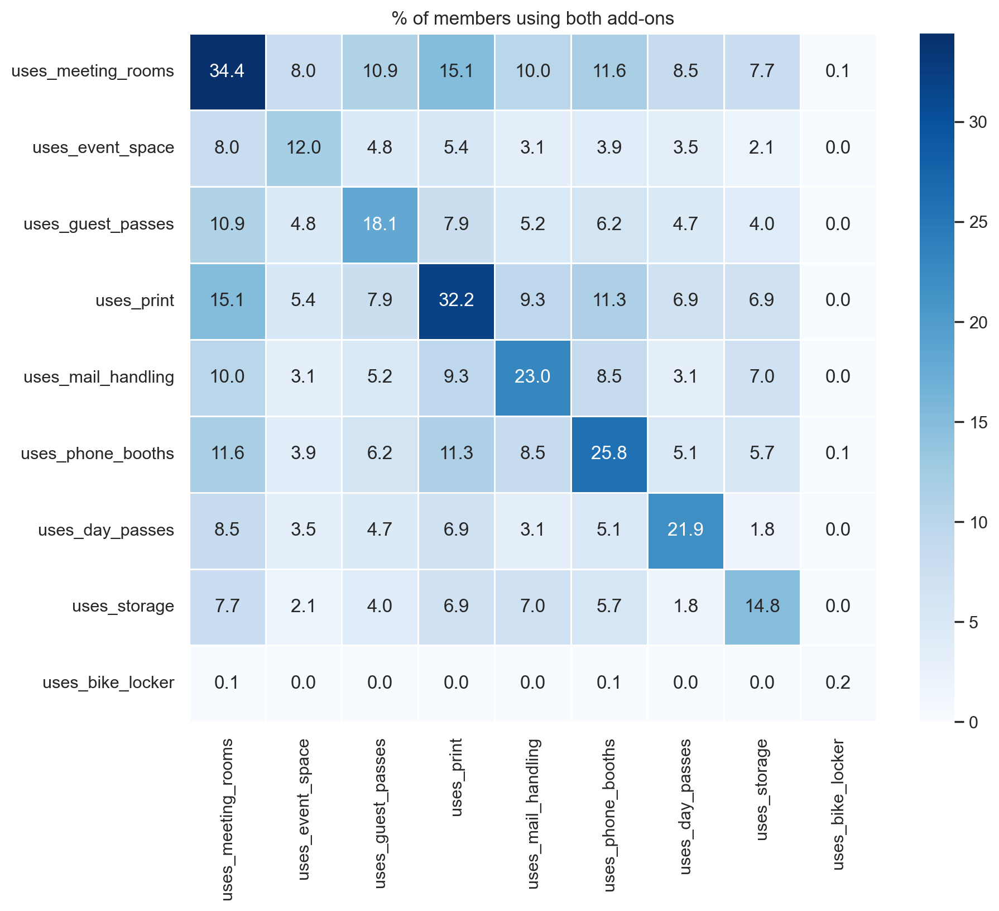

In [140]:
# Co-usage matrix: % of all members that use both add-ons (the diagonal is the adoption of each add-on)
co_use = pd.DataFrame(index=addon_cols, columns=addon_cols, dtype=float)
for a in addon_cols:
    for b in addon_cols:
        co_use.loc[a, b] = ((df_clean[a] == 1) & (df_clean[b] == 1)).mean() * 100

plt.figure(figsize=(10, 8))
sns.heatmap(co_use.round(1), annot=True, fmt=".1f", cmap="Blues", square=True, linewidths=.5)
plt.title("% of members using both add-ons")
plt.show()

**Reading the chart:** the diagonal repeats the adoption rate of each add-on, and the other cells show the % of all members who use both add-ons.

- **The most common combination is meeting rooms + print (15.1%),** followed by meeting rooms + phone booths (11.6%), print + phone booths (11.3%), meeting rooms + guest passes (10.9%) and meeting rooms + mail handling (10.0%). The most frequent pairs involve the most popular add-ons, and meeting rooms appear in most of them.
- **Co-usage is mostly higher than expected by chance.** For example, if the two add-ons were independent, we would expect about 11% of members to use both meeting rooms and print (34.4% x 32.2%), but we observe 15.1%. Event space + guest passes is also about twice what chance would give (4.8% vs 2.2%). This suggests that members who use one add-on tend to use more of them.
- **Day passes combine less with storage and mail handling** (1.8% and 3.1%, below the ~3.2% and ~5.0% expected by chance). Day-pass users seem to be members who do not need to leave belongings or receive mail in the space.
- **The bike locker is almost never combined with anything** (0.0-0.1%), as expected from its 0.2% adoption.
- Because popular add-ons overlap more just by being popular, we confirm these patterns with the correlation matrix below.

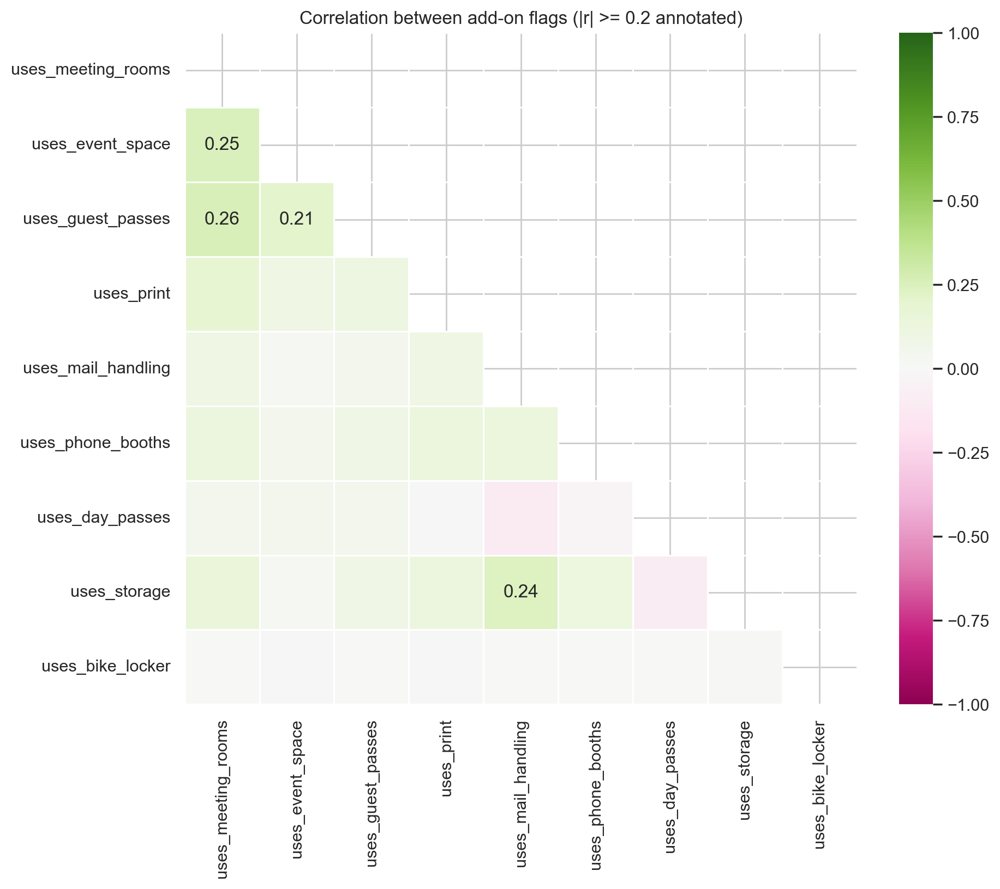

In [141]:
# Correlation between the 0/1 flags (Pearson on binary variables = phi coefficient)
corr_addons = df_clean[addon_cols].corr().round(2)

# Show only the lower triangle (the matrix is symmetric) and annotate only the stronger values
mask = np.triu(np.ones_like(corr_addons, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr_addons, mask=mask, center=0, cmap="PiYG", vmin=-1, vmax=1,
            annot=np.where(np.abs(corr_addons) >= 0.2, corr_addons.values, ""),
            fmt="s", square=True, linewidths=.5)
plt.title("Correlation between add-on flags (|r| >= 0.2 annotated)")
plt.show()

**Reading the chart:** correlation between the 0/1 flags (only values with |r| >= 0.2 are written). Unlike the co-usage matrix, it shows if two add-ons go together **more than chance**.

- **All correlations are weak (the highest is 0.26).** Add-ons are mostly independent of each other, so there is no strong "bundle" of services and no add-on is redundant with another.
- **Meeting rooms, event space and guest passes go together** (meeting rooms + event space 0.25, meeting rooms + guest passes 0.26, event space + guest passes 0.21). They are the services related to **hosting meetings, events and visitors**.
- **Storage and mail handling go together** (0.24). They are services for members who **keep a base in the space**.
- **Day passes have a slightly negative relation with mail handling and storage** (light pink cells, close to zero). This is consistent with the co-usage matrix: occasional users do not need a mailbox or storage.
- **The bike locker is not related to any add-on** (correlation close to 0), as expected from its 0.2% adoption.
- **For segmentation:** the weak correlations suggest that each add-on gives some separate information, but two small families appear (hosting and meetings vs. mail and storage). A count of add-ons (`n_addons`) summarises how much of the service a member uses.

### Meeting-room and event-space hours

**What we do in this step:** we plot the distribution of the hours of use and compute the share of members who never used each space. We expect most members at zero and a long tail of heavy users.

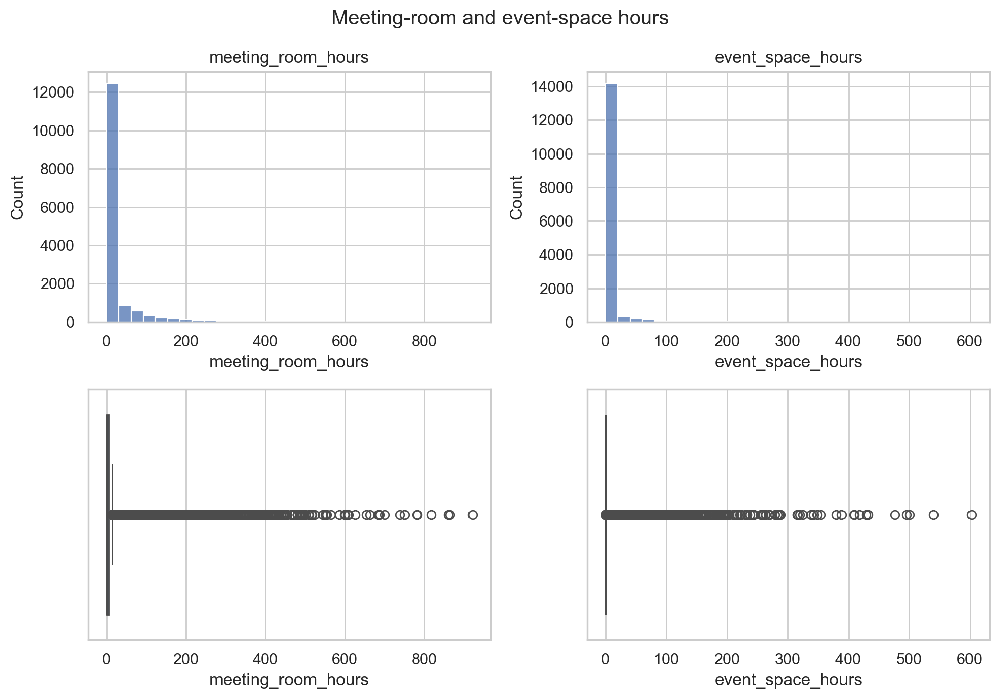

Share of members with zero hours:
meeting_room_hours    0.657
event_space_hours     0.885
dtype: float64
Median hours of the users: {'meeting_room_hours': 33.25, 'event_space_hours': 23.35}
Maximum hours: {'meeting_room_hours': 921.1, 'event_space_hours': 602.8}


In [142]:
# Histogram and box plot of the hours of use of the rooms
hours_features = ["meeting_room_hours", "event_space_hours"]
plot_hist_box(df_clean, hours_features, "Meeting-room and event-space hours")

# Share of members who never used each space
print("Share of members with zero hours:")
print((df_clean[hours_features] == 0).mean().round(3))

# Typical usage and maximum, among the members who have hours
print("Median hours of the users:", {feat: df_clean.loc[df_clean[feat] > 0, feat].median() for feat in hours_features})
print("Maximum hours:", df_clean[hours_features].max().to_dict())

### Main takeaways - hours

- **Most members never use these spaces:** 65.7% have zero meeting-room hours and 88.5% have zero event-space hours.
- **Users have a long tail.** The median user has about 33 meeting-room hours and 23 event-space hours, but the maximum is 921 and 603.
- **For segmentation:** these features are zero-inflated and very skewed, so they need a transformation before distance-based clustering. They are also totals that grow with time (see section 23).

### Overview numbers (KPIs)

**What we do in this step:** a few headline numbers that summarise the member base.

In [143]:
# Headline numbers of the member base
kpi = {
    "members": len(df_clean),
    "avg lifetime_value": df_clean["lifetime_value"].mean(),
    "avg weekly visits": df_clean["avg_weekly_visits"].mean(),
    "avg # add-ons": df_clean[addon_cols].sum(axis=1).mean(),
    "% members with no add-on": (df_clean[addon_cols].sum(axis=1) == 0).mean() * 100,
    "% members with none of meeting rooms, event space, guest passes":
        (df_clean[["uses_meeting_rooms", "uses_event_space", "uses_guest_passes"]].sum(axis=1) == 0).mean() * 100,
}
pd.Series(kpi).round(2).to_frame("value")

,value
members,15108.00
avg lifetime_value,4188.42
avg weekly visits,1.72
avg # add-ons,1.82
% members with no add-on,19.90
"% members with none of meeting rooms, event space, guest passes",55.11


### Main takeaways - add-ons

- **Adoption:** meeting rooms (34.4%) and print (32.2%) are the most used, event space (12.0%) and the bike locker (0.2%) the least.
- **Pairs:** two small families appear, hosting (meeting rooms, event space, guest passes) and keeping a base in the space (mail handling, storage). All correlations are weak (the highest is 0.26), so each add-on keeps some separate information.
- **Most members use at least one add-on:** only 19.9% use none, and the average is 1.82. But 55.1% use none of meeting rooms, event space and guest passes, the add-ons with recorded usage.
- **What this suggests:** a small group of heavy room users, a majority that uses little of the rooms, and a difference between hosting and keeping a base that is worth testing in clustering.

## 22. Value

**Goal:** understand how much revenue each member brings, how loyal members are (renewals) and what explains the differences.

**What we analyse in this section:**
1. **Distribution of `lifetime_value` and `n_renewals`.**
2. **What is associated with a higher lifetime value** (correlations and plan tier).
3. **Concentration of value**: how much of the total revenue comes from the top 10% of members.

**Why it matters for segmentation:** value-based segmentation is one of the perspectives required by the project (guidelines, section 2).

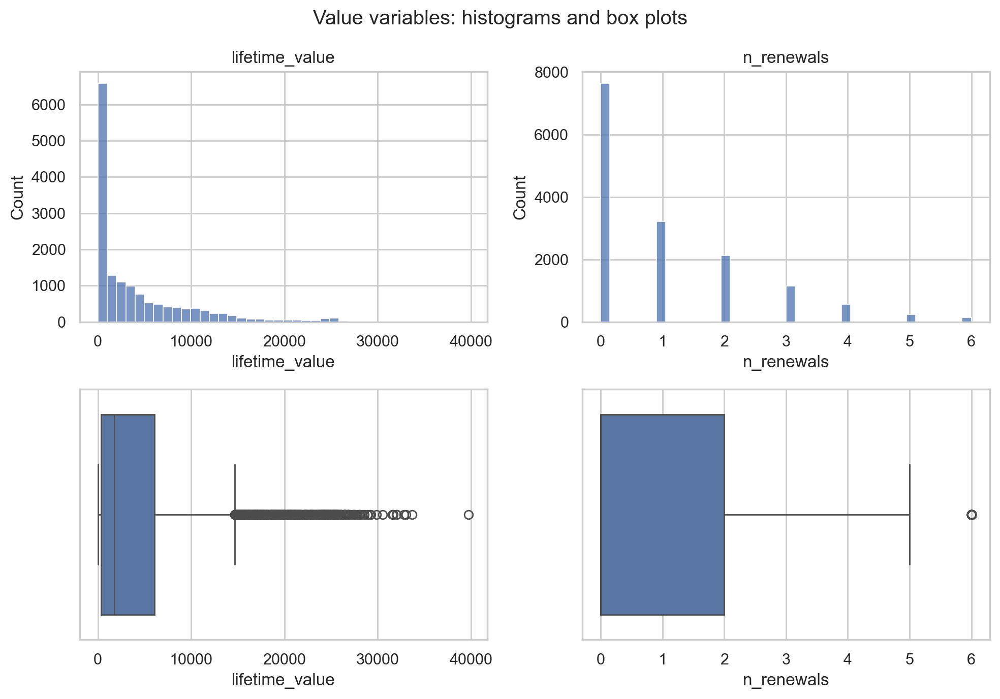

In [144]:
# Histogram and box plot of the revenue and of the number of renewals
plot_hist_box(df_clean, ["lifetime_value", "n_renewals"], "Value variables: histograms and box plots", bins=40)

In [145]:
# Numbers behind the plots above
print(df_clean[["lifetime_value", "n_renewals"]].skew().round(2).to_string())
print(f"Members with no renewal: {(df_clean['n_renewals'] == 0).mean():.1%}")
df_clean[["lifetime_value", "n_renewals"]].describe().round(2).T

lifetime_value    1.92
n_renewals        1.43
Members with no renewal: 50.6%


,count,mean,std,min,25%,50%,75%,max
lifetime_value,15108.0,4188.42,5518.70,12.0,360.0,1756.42,6085.32,39759.93
n_renewals,15108.0,1.01,1.34,0.0,0.0,0.00,2.00,6.00


### Main takeaways - value distributions

- **`lifetime_value` is right-skewed (skewness 1.92):** the median is 1,756 euros, the mean is 4,188 and the maximum is 39,760. The long tail comes from expensive plans, long memberships and heavy add-on use.
- **Half of the members never renewed (50.6%).** The median is 0 renewals and the maximum is 6.
- **For segmentation:** both variables are skewed and grow with the length of the membership, so they need a log transformation or robust scaling. The per-month versions (`ltv_per_month`, `ltv_vs_tier`) are safer inputs than the totals.

### What is associated with lifetime value?

**What we do in this step:** we compute the correlation of every other metric feature with `lifetime_value`.

> **Caveat:** part of `lifetime_value` was imputed as *plan price x tenure*, so its correlation with plan tier and tenure is partly built in. We read the bars as an upper bound.

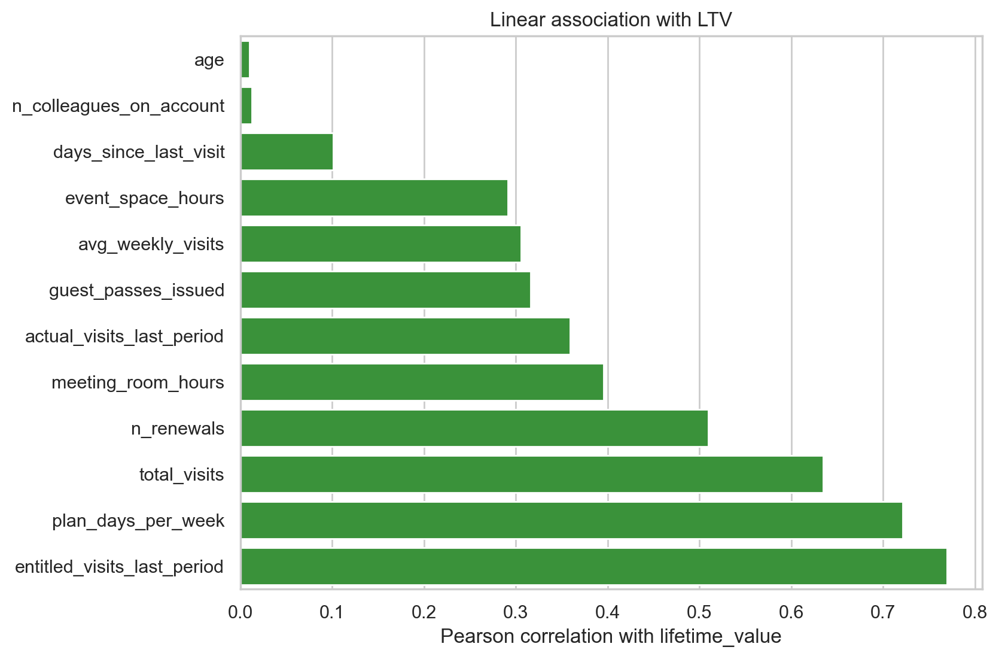

entitled_visits_last_period    0.77
plan_days_per_week             0.72
total_visits                   0.63
n_renewals                     0.51
meeting_room_hours             0.40
actual_visits_last_period      0.36
guest_passes_issued            0.32
avg_weekly_visits              0.31
event_space_hours              0.29
days_since_last_visit          0.10
n_colleagues_on_account        0.01
age                            0.01


In [146]:
# Pearson correlation of every other metric feature with lifetime_value, sorted
drivers = [c for c in metric_features if c != "lifetime_value"]
corr_ltv = df_clean[drivers + ["lifetime_value"]].corr()["lifetime_value"].drop("lifetime_value").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=corr_ltv.values, y=corr_ltv.index, ax=ax, color="tab:green")
ax.set_xlabel("Pearson correlation with lifetime_value")
ax.set_ylabel("")
ax.set_title("Linear association with LTV")
plt.show()

print(corr_ltv.sort_values(ascending=False).round(2).to_string())

**Reading the chart:**

- **`lifetime_value` follows the plan and time:** the strongest associations are `entitled_visits_last_period` (0.77) and `plan_days_per_week` (0.72), which reflect the plan, followed by `total_visits` (0.63) and `n_renewals` (0.51), which grow with time.
- **Add-on usage matters, but less:** `meeting_room_hours` (0.40), `guest_passes_issued` (0.32) and `event_space_hours` (0.29).
- **`age` and `n_colleagues_on_account` have no linear relation with value** (both 0.01).
- Pearson correlation only captures linear relations, and the imputation caveat above applies to the plan and tenure associations.

### Lifetime value and renewals by plan tier

**What we do in this step:** box plots of `lifetime_value` and `n_renewals` for each plan tier, and a table with the mean and median per tier.

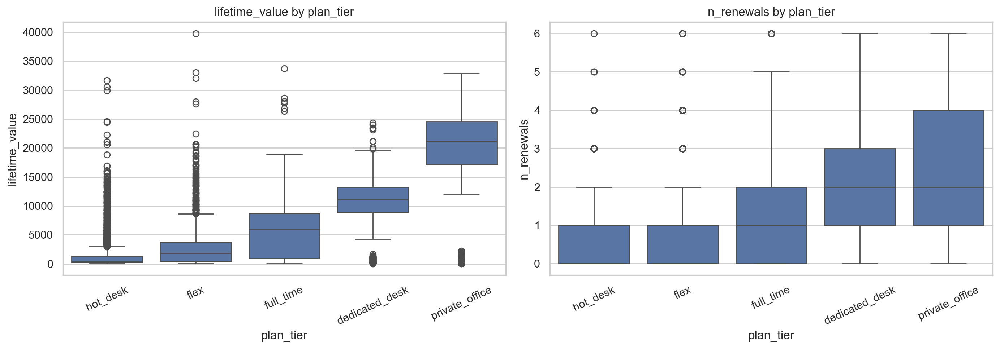

Median renewals per tier: {'hot_desk': 0.0, 'flex': 0.0, 'full_time': 1.0, 'dedicated_desk': 2.0, 'private_office': 2.0}


,count,mean,median
plan_tier,,,
hot_desk,5110,1235.7,357.2
flex,5336,2469.1,1847.8
full_time,2440,5700.0,5868.5
dedicated_desk,1526,10727.5,11045.8
private_office,696,19412.3,21161.2


In [147]:
# Tiers from the cheapest to the most expensive (only those that exist in the data)
tier_order = [t for t in p_order if t in df_clean["plan_tier"].unique()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), tight_layout=True)
sns.boxplot(data=df_clean, x="plan_tier", y="lifetime_value", order=tier_order, ax=axes[0])
axes[0].set_title("lifetime_value by plan_tier")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=df_clean, x="plan_tier", y="n_renewals", order=tier_order, ax=axes[1])
axes[1].set_title("n_renewals by plan_tier")
axes[1].tick_params(axis="x", rotation=25)
plt.show()

print("Median renewals per tier:", df_clean.groupby("plan_tier")["n_renewals"].median().reindex(tier_order).to_dict())

# Numbers per tier: members, mean and median LTV
df_clean.groupby("plan_tier")["lifetime_value"].agg(["count", "mean", "median"]).round(1).reindex(tier_order)

### Concentration of value

**What we do in this step:** we sort members by `lifetime_value` and compute the share of the total revenue that comes from the top 10%.

In [148]:
# Share of the total revenue that comes from the top 10% of members
ltv_sorted = df_clean["lifetime_value"].sort_values(ascending=False)
top10 = ltv_sorted.head(int(len(ltv_sorted) * 0.10)).sum() / ltv_sorted.sum()
print(f"Top 10% of members generate {top10:.1%} of total lifetime value")

Top 10% of members generate 41.4% of total lifetime value


In [149]:
# Who are the top 10% of members, and how much of the revenue comes from each tier?
top10_members = ltv_sorted.head(int(len(ltv_sorted) * 0.10)).index
pd.DataFrame({
    "% of members": tier.value_counts(normalize=True) * 100,
    "% of the top 10%": tier[top10_members].value_counts(normalize=True) * 100,
    "% of total revenue": df_clean["lifetime_value"].groupby(tier).sum() / df_clean["lifetime_value"].sum() * 100,
}).round(1).reindex(p_order)

,% of members,% of the top 10%,% of total revenue
plan_tier,,,
hot_desk,33.8,3.8,10.0
flex,35.3,4.1,20.8
full_time,16.2,9.2,22.0
dedicated_desk,10.1,41.3,25.9
private_office,4.6,41.6,21.4


### Main takeaways - value

- **Value grows far more across tiers than the price does.** Median `lifetime_value` goes from 357 euros in `hot_desk` to 21,161 in `private_office` (59 times), while the monthly price is only about 5 times higher. Members of the expensive tiers also stay much longer (section 24).
- **Renewals follow the same pattern:** the median is 0 in `hot_desk` and `flex`, 1 in `full_time` and 2 in `dedicated_desk` and `private_office`.
- **Value is concentrated.** The top 10% of members generate 41.4% of the revenue, and 82.9% of them are in `dedicated_desk` or `private_office`, which together are only 14.7% of the members.
- **But no tier can be ignored:** each one brings between 10.0% and 25.9% of the revenue. `hot_desk` and `flex` are 69.1% of the members and 30.8% of the revenue.
- **For segmentation:** value mostly separates the plan tiers, so a clustering built on `lifetime_value` would mostly recover `plan_tier`. The part that adds information is what a member pays above the plan (`ltv_vs_tier`).

## 23. Feature engineering

**Goal:** create new variables that describe behaviour and value better than the original columns, so that clustering can find richer groups.

| Feature | Formula | What it captures |
|---|---|---|
| `tenure_days` | (`membership_end` or extraction date) - `membership_start` | Loyalty |
| `recency_days` | extraction date - `last_badge_swipe` | True recency at the extraction date (used for the R score) |
| `utilization_rate` | actual / entitled visits (last period) | How much of the plan the member really uses |
| `ltv_per_month` | `lifetime_value` / tenure in months | Worth per month, regardless of tenure |
| `ltv_vs_tier` | `ltv_per_month` / median `ltv_per_month` of the tier (real revenue only) | Spend above the plan price (add-ons) |
| `n_addons` | sum of `uses_*` | How much of the service the member uses |
| `hours_per_visit` | (meeting + event hours) / `total_visits` | Office/events use vs just a desk |
| `addon_hours_per_month` | (meeting + event hours) / tenure in months | Room usage, regardless of tenure |
| `guest_passes_per_month` | `guest_passes_issued` / tenure in months | Guest usage, regardless of tenure |
| `is_active` | `membership_end` is missing | Active vs churned |
| `plan_tier_ord` | hot_desk=1 ... private_office=5 (metadata order) | Plan tier as a numeric scale (see the note below) |
| `plan_price_rank` | rank of the median `ltv_per_month` of the tier | Plan tier as a price scale |
| `r_score`, `f_score`, `m_score`, `rfm_score` | quantiles of recency, frequency and LTV | Value-based segmentation (RFM) |

**Missing values created by these features** are *not* MCAR, MAR or MNAR: they are *undefined by construction*, and we leave them as NaN. `ltv_vs_tier` is undefined when the revenue was imputed, and the two per-month features are undefined for memberships shorter than a month, where a monthly rate would be unstable.


In [150]:
# Create all engineered features with the function defined in the Functions section
df_fe = engineer_features(df_clean, EXTRACTION_DATE)

engineered_features = ["tenure_days", "recency_days", "utilization_rate", "ltv_per_month", "ltv_vs_tier",
                       "n_addons", "hours_per_visit", "addon_hours_per_month", "guest_passes_per_month",
                       "is_active", "plan_tier_ord", "plan_price_rank",
                       "r_score", "f_score", "m_score", "rfm_score"]

# Sanity checks: a tenure <= 0 would be a data problem, and every tier must have been mapped to a number
print("Members with tenure_days <= 0:", (df_fe["tenure_days"] <= 0).sum())
print("plan_tier values not mapped:", df_fe.loc[df_fe["plan_tier_ord"].isna(), "plan_tier"].unique())

# Summary statistics of the new features
df_fe[engineered_features].describe().round(2).T

Members with tenure_days <= 0: 0
plan_tier values not mapped: []


,count,mean,std,min,25%,50%,75%,max
tenure_days,15108.0,374.09,338.61,2.00,65.00,282.00,635.00,1095.00
recency_days,15108.0,320.06,286.88,0.00,77.00,239.50,505.00,1095.00
utilization_rate,15108.0,0.52,0.31,0.00,0.24,0.52,0.80,1.00
ltv_per_month,15108.0,265.28,161.34,93.37,150.10,204.85,315.69,2311.55
ltv_vs_tier,12321.0,1.17,0.63,0.70,0.92,1.00,1.14,10.06
n_addons,15108.0,1.82,1.50,0.00,1.00,2.00,3.00,8.00
hours_per_visit,15108.0,0.34,1.18,0.00,0.00,0.00,0.14,46.10
addon_hours_per_month,14429.0,1.75,4.69,0.00,0.00,0.00,1.21,166.86
guest_passes_per_month,14429.0,0.37,1.22,0.00,0.00,0.00,0.00,25.01
is_active,15108.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00


### Quality check of the engineered features

**What we do in this step:** we count the missing values and infinities created by the ratios and look at the range of each feature. Extreme values should be discussed with the outlier analysis.

In [151]:
# NaN = undefined ratio, inf = an unprotected division (should be 0), min/max = range of each feature
check = pd.DataFrame({
    "n_nan": df_fe[engineered_features].isna().sum(),
    "n_inf": np.isinf(df_fe[engineered_features]).sum(),
    "min": df_fe[engineered_features].min(),
    "max": df_fe[engineered_features].max(),
})
check

,n_nan,n_inf,min,max
tenure_days,0,0,2.000000,1095.000000
recency_days,0,0,0.000000,1095.000000
utilization_rate,0,0,0.000000,1.000000
ltv_per_month,0,0,93.374700,2311.553472
ltv_vs_tier,2787,0,0.695976,10.057864
n_addons,0,0,0.000000,8.000000
hours_per_visit,0,0,0.000000,46.100000
addon_hours_per_month,679,0,0.000000,166.856296
guest_passes_per_month,679,0,0.000000,25.005802
is_active,0,0,0.000000,1.000000


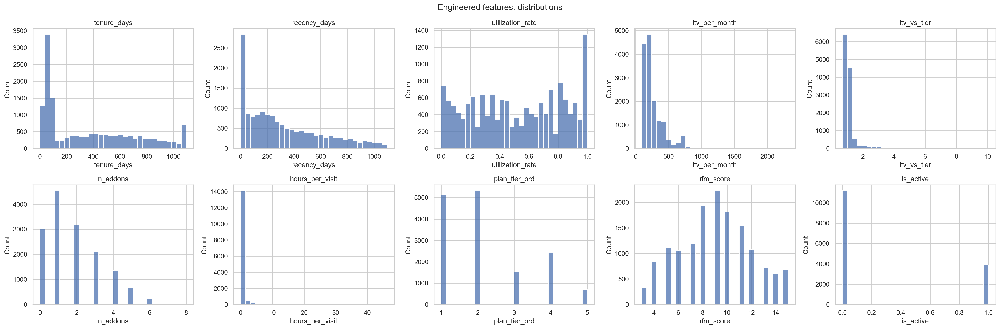

In [152]:
# Distribution of the main engineered features (inf and NaN are removed only for plotting)
plot_features = ["tenure_days", "recency_days", "utilization_rate", "ltv_per_month", "ltv_vs_tier",
                 "n_addons", "hours_per_visit", "plan_tier_ord", "rfm_score", "is_active"]

fig, axes = plt.subplots(2, 5, figsize=(24, 8), tight_layout=True)
for ax, feat in zip(axes.flatten(), plot_features):
    sns.histplot(df_fe[feat].replace([np.inf, -np.inf], np.nan).dropna(), bins=30, ax=ax)
    ax.set_title(feat)
fig.suptitle("Engineered features: distributions")
plt.show()

### Main takeaways - engineered features

- **Skewed features:** `hours_per_visit`, `addon_hours_per_month`, `guest_passes_per_month` and `ltv_vs_tier` have a few very high values, so they may need a transformation.
- **More than one peak:** `tenure_days` has a peak around 60 days (one period) and another at 1,095 days (the whole data window), `utilization_rate` has peaks at both ends, near 0 and near 1, and `ltv_per_month` has one peak per tier.
- **Undefined values:** `ltv_vs_tier` for the 2,787 members with imputed revenue, and the per-month features for the 679 members with less than a month. There are no infinities.
- **Extreme value to keep in mind:** the maximum `hours_per_visit` (46.1) comes from a member with a single recorded visit and imputed hours.
- **For segmentation:** the ratio and per-month features (`utilization_rate`, `ltv_vs_tier`, `addon_hours_per_month`, `guest_passes_per_month`) are better inputs than the totals, but the skewed ones need a transformation first.

### Two checks on the features that depend on the cleaning

1. **Imputed LTV:** the cleaning marks these members in `ltv_imputed`, and `ltv_vs_tier` leaves them out.
2. **Tier order:** is the metadata order (`plan_tier_ord`) also the price order?

In [153]:
# Imputed revenue is marked by the cleaning (ltv_imputed), so ltv_vs_tier leaves those members out
print(f"Imputed lifetime_value: {df_fe['ltv_imputed'].mean():.1%} of members | ltv_vs_tier undefined: {df_fe['ltv_vs_tier'].isna().mean():.1%}")
print(f"Paying at least twice the plan, among members with real revenue: {(df_fe['ltv_vs_tier'] >= 2).sum() / df_fe['ltv_vs_tier'].notna().sum():.1%}")

# Median revenue per month of each tier (~ the monthly price), in the metadata order
price_by_tier = df_fe.groupby("plan_tier")["ltv_per_month"].median().round(1).reindex(TIER_ORDER)
print("Median ltv_per_month by tier (metadata order):")
print(price_by_tier.to_string())
print("Same order as the price?", price_by_tier.is_monotonic_increasing)

Imputed lifetime_value: 18.4% of members | ltv_vs_tier undefined: 18.4%
Paying at least twice the plan, among members with real revenue: 5.5%
Median ltv_per_month by tier (metadata order):
plan_tier
hot_desk          132.6
flex              204.8
dedicated_desk    407.2
full_time         312.9
private_office    702.7
Same order as the price? False


> `dedicated_desk` is more expensive than `full_time`, so `plan_tier_ord` (metadata order) is **not** a price scale.
> We keep both features, which are strongly correlated (0.91), but **we use the price order in all tables and plots, and `plan_price_rank` is the one we recommend for distance-based methods**, because its order means more money per month. `plan_tier_ord` stays only to show the difference.

### What do the totals really measure?

**What we do in this step:** we compare `lifetime_value` and the M score with tenure and with the plan, and then compare totals with rates per month across four equal groups of tenure.

In [154]:
# What does each value measure? Correlation of lifetime_value and m_score with tenure and with the plan
df_fe[["lifetime_value", "m_score", "ltv_per_month", "tenure_days", "plan_price_rank", "plan_tier_ord", "n_addons"]].corr().round(2).loc[
    ["lifetime_value", "m_score", "ltv_per_month"], ["tenure_days", "plan_price_rank", "plan_tier_ord", "n_addons"]]

,tenure_days,plan_price_rank,plan_tier_ord,n_addons
lifetime_value,0.84,0.74,0.64,0.49
m_score,0.90,0.65,0.58,0.50
ltv_per_month,0.52,0.76,0.70,0.58


In [155]:
# Totals vs rates, per quarter of tenure (the groups come from the data, as in section 9.1)
tenure_band = pd.qcut(df_fe["tenure_days"], 4)
df_fe.groupby(tenure_band, observed=True).agg(
    members=("n_addons", "size"),
    n_addons=("n_addons", "mean"),
    meeting_room_hours=("meeting_room_hours", "mean"),
    addon_hours_per_month=("addon_hours_per_month", "mean"),
    guest_passes_issued=("guest_passes_issued", "mean"),
    guest_passes_per_month=("guest_passes_per_month", "mean"),
).round(2).rename_axis("tenure_days")

,members,n_addons,meeting_room_hours,addon_hours_per_month,guest_passes_issued,guest_passes_per_month
tenure_days,,,,,,
"(1.999, 65.0]",3822,1.16,0.73,0.58,0.23,0.14
"(65.0, 282.0]",3741,1.31,5.42,1.16,0.99,0.19
"(282.0, 635.0]",3769,2.25,35.86,3.01,9.55,0.62
"(635.0, 1095.0]",3776,2.58,47.40,2.06,12.89,0.46


### Main takeaways - totals vs rates

- **`lifetime_value` and `m_score` mostly measure time.** Their correlation with `tenure_days` is 0.84 and 0.90, so a high `rfm_score` often just means a long membership. For clustering, `tenure_days` and `ltv_per_month` separately say more than `rfm_score`.
- **`ltv_per_month` mostly measures the plan** (0.76 with `plan_price_rank`). `ltv_vs_tier` is the feature that removes the plan and keeps what the member adds to it.
- **Rates reduce the effect of time, but do not remove it.** From the shortest to the longest memberships, average meeting-room hours go from 0.73 to 47.40, while room hours per month go from 0.58 to 2.06. Guest passes go from 0.23 to 12.89, and per month from 0.14 to 0.46.
- **`n_addons` also grows with tenure** (1.16 to 2.58), because the flags record whether a member ever used an add-on, so it has to be read together with tenure.

## 24. First look at possible groups

**Goal:** check, with plots only (no clustering yet), whether the engineered features suggest natural groups of members.

**What we do in this section:**
1. **Pair plots** of the main engineered features, coloured by `plan_tier` and by active/churned. Separated "clouds" of points suggest different groups.
2. **Correlation between the engineered features.** Very high values mean redundancy, so some features could be dropped before clustering.

In [156]:
# Features shown in the pair plots (few, otherwise the figure is unreadable)
pair_features = ["tenure_days", "recency_days", "utilization_rate", "ltv_vs_tier", "n_addons", "hours_per_visit"]

# Remove inf/NaN (pair plots cannot draw them), which also leaves out the imputed revenue, and label active/churned
df_pair = df_fe[pair_features + ["plan_tier", "is_active"]].replace([np.inf, -np.inf], np.nan).dropna()
df_pair["status"] = df_pair["is_active"].map({1: "active", 0: "churned"})

# A 2000-row random sample keeps the plot fast; this is only a visual check
sample = df_pair.sample(min(2000, len(df_pair)), random_state=42)

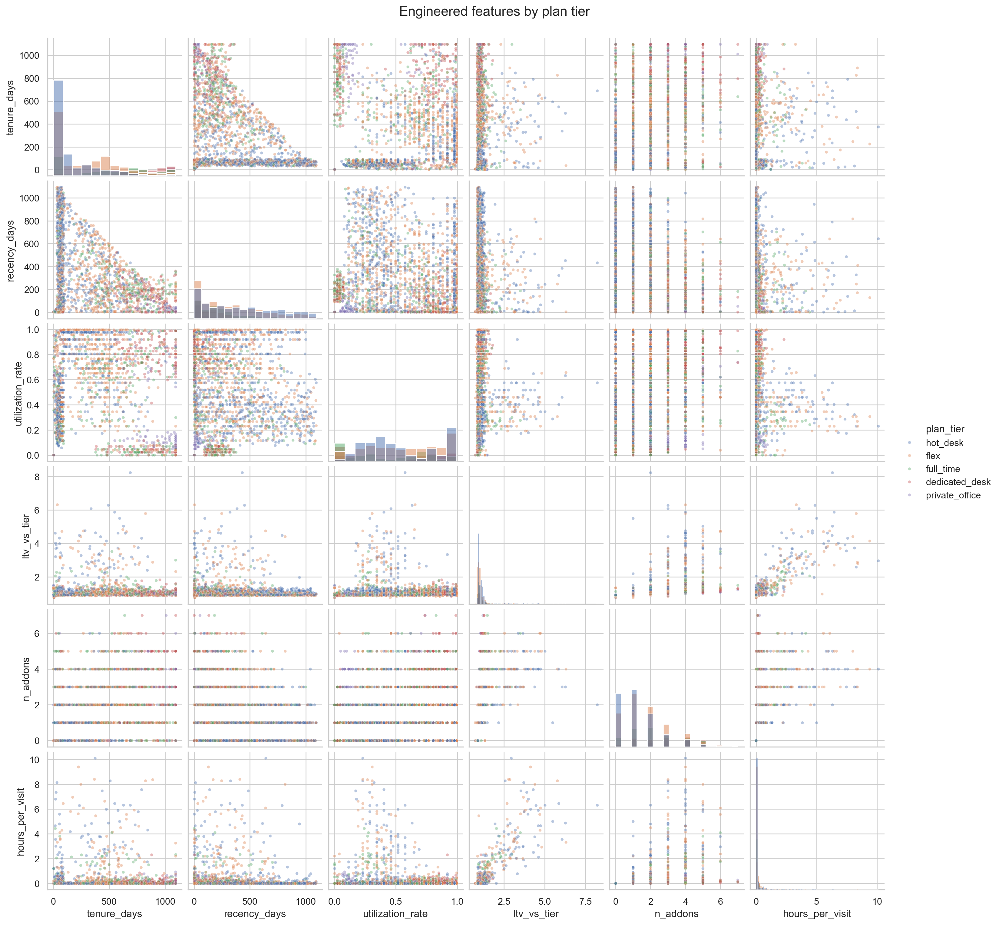

In [157]:
# Pair plot coloured by plan tier: do the tiers separate in any feature?
g = sns.pairplot(sample, vars=pair_features, hue="plan_tier", hue_order=tier_order,
                 diag_kind="hist", plot_kws={"alpha": 0.4, "s": 12})
g.figure.suptitle("Engineered features by plan tier", y=1.02, fontsize=16)
plt.show()

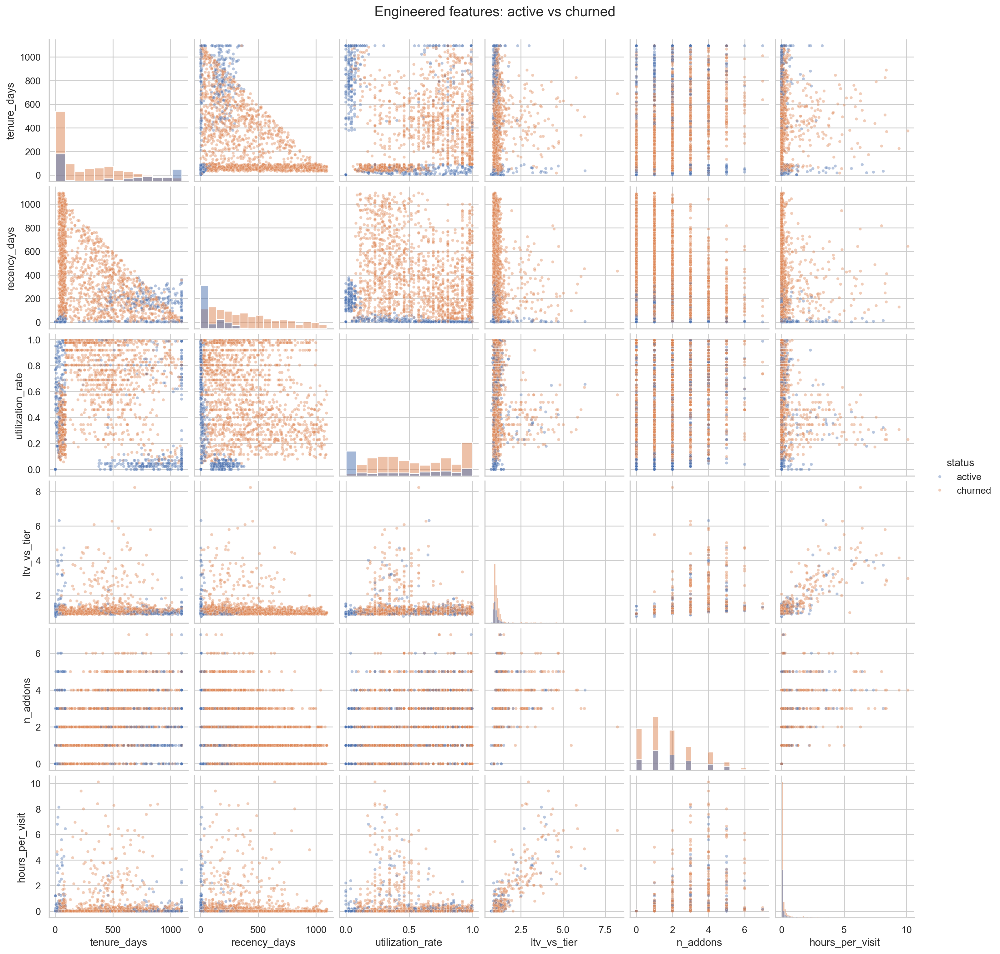

In [158]:
# Pair plot coloured by status: do active and churned members behave differently?
g = sns.pairplot(sample, vars=pair_features, hue="status",
                 diag_kind="hist", plot_kws={"alpha": 0.4, "s": 12})
g.figure.suptitle("Engineered features: active vs churned", y=1.02, fontsize=16)
plt.show()

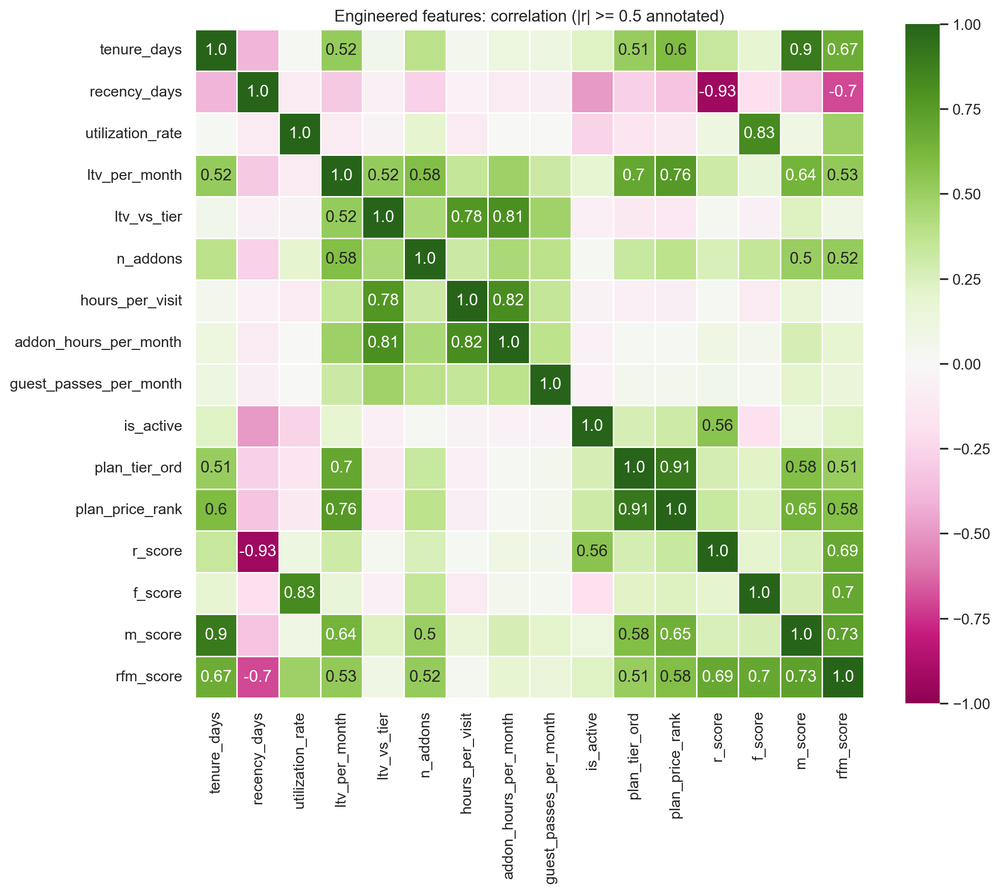

In [159]:
# Correlation among the engineered features: very high values mean redundancy (candidates to drop before clustering)
corr_fe = df_fe[engineered_features].replace([np.inf, -np.inf], np.nan).corr().round(2)

plt.figure(figsize=(11, 9))
sns.heatmap(corr_fe, center=0, cmap="PiYG", vmin=-1, vmax=1,
            annot=np.where(np.abs(corr_fe) >= 0.5, corr_fe.values, ""), fmt="s",
            square=True, linewidths=.5)
plt.title("Engineered features: correlation (|r| >= 0.5 annotated)")
plt.show()

### Profile of each plan tier

**What we do in this step:** one table with the main behaviour, value and demographic numbers of each tier.

In [160]:
# Profile of each plan tier
df_fe.groupby("plan_tier").agg(
    members=("age", "size"),
    pct_active=("is_active", lambda s: s.mean() * 100),
    median_tenure_days=("tenure_days", "median"),
    median_ltv_per_month=("ltv_per_month", "median"),
    median_weekly_visits=("avg_weekly_visits", "median"),
    mean_utilization=("utilization_rate", "mean"),
    mean_addons=("n_addons", "mean"),
    median_age=("age", "median"),
    mean_age=("age", "mean"),
    pct_team=("is_team_account", lambda s: s.mean() * 100),
    pct_female=("gender", lambda s: (s == "Female").mean() * 100),
    pct_portugal=("country", lambda s: (s == "Portugal").mean() * 100),
).round(1).reindex(p_order).T

plan_tier,hot_desk,flex,full_time,dedicated_desk,private_office
members,5110.0,5336.0,2440.0,1526.0,696.0
pct_active,13.5,20.4,38.2,57.0,46.4
median_tenure_days,80.0,261.0,529.0,810.0,904.0
median_ltv_per_month,132.6,204.8,312.9,407.2,702.7
median_weekly_visits,1.0,1.9,1.7,3.9,1.0
mean_utilization,0.5,0.5,0.4,0.6,0.4
mean_addons,1.3,1.7,2.2,2.9,3.3
median_age,34.0,34.0,34.0,34.0,34.0
mean_age,34.7,34.6,34.9,35.1,34.5
pct_team,28.0,28.8,26.5,27.5,30.6


### Do these patterns describe real groups of members?

**What we do in this step:** we turn the patterns found above into simple rules, and check how many members and how much revenue each group represents. This is **not clustering**: the rules and the 90-day and twice-the-plan limits are our own choices, only used to prepare the hypotheses for Deliverable 2.

In [161]:
# First look at possible groups with simple rules. This is NOT clustering: it only checks if the patterns above
# describe a relevant number of members. Each member gets the first rule that applies
quarter = 90     # days
conditions = {
    "heavy add-on user": df_fe["ltv_vs_tier"] >= 2,
    "dormant (active, not seen for 90+ days)": (df_fe["is_active"] == 1) & (df_fe["recency_days"] > quarter),
    "short stay (left within 90 days)": (df_fe["is_active"] == 0) & (df_fe["tenure_days"] <= quarter),
    "new (active, joined within 90 days)": (df_fe["is_active"] == 1) & (df_fe["tenure_days"] <= quarter),
}
df_fe["first_look_group"] = "other members"
for name, condition in reversed(list(conditions.items())):
    df_fe.loc[condition, "first_look_group"] = name

group_profile = df_fe.groupby("first_look_group").agg(
    members=("age", "size"),
    median_tenure_days=("tenure_days", "median"),
    median_recency_days=("recency_days", "median"),
    median_ltv_per_month=("ltv_per_month", "median"),
    median_weekly_visits=("avg_weekly_visits", "median"),
    mean_utilization=("utilization_rate", "mean"),
    mean_addons=("n_addons", "mean"),
)
group_profile.insert(1, "pct_members", group_profile["members"] / len(df_fe) * 100)
group_profile.insert(2, "pct_revenue", df_fe.groupby("first_look_group")["lifetime_value"].sum() / df_fe["lifetime_value"].sum() * 100)
group_profile.round(2).sort_values("members", ascending=False)

,members,pct_members,pct_revenue,median_tenure_days,median_recency_days,median_ltv_per_month,median_weekly_visits,mean_utilization,mean_addons
first_look_group,,,,,,,,,
other members,7242,47.93,69.77,496.0,220.0,217.12,2.28,0.73,2.34
short stay (left within 90 days),4231,28.01,2.31,61.0,551.0,159.21,0.82,0.32,0.88
"dormant (active, not seen for 90+ days)",1481,9.80,18.57,794.0,193.0,312.89,0.16,0.04,1.21
"new (active, joined within 90 days)",1477,9.78,0.72,36.0,7.0,189.27,1.85,0.57,1.70
heavy add-on user,677,4.48,8.63,439.0,225.0,520.13,1.00,0.40,3.85


In [162]:
# Which tiers are inside each group? 
pd.crosstab(df_fe["first_look_group"], df_fe["plan_tier"], normalize="index")[p_order].mul(100).round(1)

plan_tier,hot_desk,flex,full_time,dedicated_desk,private_office
first_look_group,,,,,
"dormant (active, not seen for 90+ days)",0.0,25.1,39.4,35.5,0.0
heavy add-on user,54.9,35.2,9.9,0.0,0.0
"new (active, joined within 90 days)",37.3,38.1,13.9,6.2,4.5
other members,25.8,37.0,16.0,12.5,8.7
short stay (left within 90 days),54.8,35.0,10.0,0.1,0.0


### Main takeaways - possible groups

**Hypotheses from the data-quality analysis:**
- **A small group of heavy add-on users exists (confirmed).** Among members with real revenue, 5.5% pay at least twice their plan, and `ltv_vs_tier` is strongly correlated with `hours_per_visit` (0.78) and `addon_hours_per_month` (0.81). Note that most members do use some add-on; it is the heavy use that is rare.
- **Plan tier is nearly a price list (confirmed),** so differences in value *within* a tier come from add-ons.
- **Active and churned members differ in recency and utilization (confirmed, but not as expected).** The active members are the ones who use less of their plan.

**Which features separate the groups best:**
- `tenure_days` (median from 80 days in `hot_desk` to 904 in `private_office`), `recency_days` with `is_active`, `utilization_rate`, and `ltv_vs_tier` with `addon_hours_per_month`.
- **Demographics separate very little:** the median age is 34 in every tier (the cleaning replaced about 4.5% of the ages, missing or invalid, by the median, so this value is partly an effect of the imputation; the table also shows the mean age), women are 50-53% and team accounts 27-31%. Only the country varies (Portugal from 42% to 76%). They look more useful for profiling segments than for building them.

**Most unexpected:**
- `dedicated_desk` and `full_time` are both 5-day plans, but the median member makes 3.9 and 1.7 visits per week.
- Paying at least twice the plan only happens in `hot_desk`, `flex` and `full_time`, never in `dedicated_desk` or `private_office`, possibly because add-ons weigh less next to an expensive plan.

**Natural groups suggested by the plots and the rules above:**

| Group | Members | Revenue | What defines it |
|---|---|---|---|
| Short stay | 28.0% | 2.3% | Left within 90 days (median 61), 90% in `hot_desk` or `flex` |
| Dormant | 9.8% | 18.6% | Active, not seen for 90+ days, utilization 0.04, median tenure 794 days, none in `hot_desk` or `private_office` |
| New | 9.8% | 0.7% | Active, joined within 90 days, too early to classify |
| Heavy add-on users | 4.5% | 8.6% | Pay at least twice the plan, 3.9 add-ons on average |
| Other members | 47.9% | 69.8% | Utilization 0.73, median tenure 496 days; the plan tier probably splits them into regular and premium members |

**Expected number of clusters:** about 5 (between 4 and 6), to be tested in Deliverable 2. The new members may not form a group of their own, and the other members may split in two.

**Challenges anticipated:**
- **Skewness:** usage and value features need scaling and probably a transformation.
- **Redundancy:** `recency_days` and `r_score` (-0.93), `tenure_days` and `m_score` (0.90), `utilization_rate` and `f_score` (0.83), `plan_tier_ord` and `plan_price_rank` (0.91), `hours_per_visit` and `addon_hours_per_month` (0.82). Using them together would count the same information twice.
- **Time:** tenure is cut by the data window, and totals grow with tenure, so rates are safer inputs.
- **Estimated values:** 18.4% of the revenue is imputed, which leaves `ltv_vs_tier` undefined for those members.
- **Imbalanced tiers:** `private_office` is only 4.6% of the members, so it can be lost in larger clusters even though it brings 21.4% of the revenue.
- **The dormant group is ambiguous:** it may be members who stopped coming or end dates that were never recorded.

# Part 4: Bonus

## 25. Bonus: Multidimensional Outlier & Anomaly Detection

The rules of sections 5 to 8 check one or two columns at a time, so they cannot see a member whose values are each plausible but unusual together. Here we look at the features **together**, to answer three questions from the project guidelines: which members behave unusually, can they distort clustering, and should they be excluded, downweighted or analysed separately?

**Techniques used:** standard scaling and PCA, the ~5% rule of thumb and redundancy checks, correlation heatmaps, bivariate outliers, and crosstabs. **Advanced methods:** Isolation Forest, Local Outlier Factor, the Mahalanobis distance, the log transformation, and the K-Means test, all sourced from the scikit-learn and NumPy documentation.

### 25.1 Features

We use the behaviour and value of each member. Demographics are left out because an unusual age is not an unusual behaviour, and it
is a univariate problem that section 5 already covers. Totals are replaced by rates, because a long membership alone should not
make a member look unusual.

In [163]:
def anomaly_features(data):
    """Behaviour and value of each member, as rates where possible so that a long membership alone is not unusual."""
    tenure = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days
    months = tenure / 30.44
    rate_months = months.clip(lower=1)     # a rate over a few days would make very short memberships look extreme

    features = pd.DataFrame(index=data.index)
    features["tenure_days"] = tenure
    features["recency_days"] = (extraction_date - data["last_badge_swipe"]).dt.days
    features["avg_weekly_visits"] = data["avg_weekly_visits"]
    features["utilization_rate"] = data["actual_visits_last_period"] / data[ent]
    # revenue compared with the plan price (5.7): imputed revenue is exactly 1 by construction
    features["ltv_vs_tier"] = data["lifetime_value"] / (data["plan_tier"].map(tier_monthly_price) * months)
    features["addon_hours_per_month"] = (data["meeting_room_hours"] + data["event_space_hours"]) / rate_months
    features["guest_passes_per_month"] = data["guest_passes_issued"] / rate_months
    features["n_addons"] = data[addon_flags].sum(axis=1)
    return features


anomaly_data = anomaly_features(df_clean)
anomaly_data.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
tenure_days,15108.0,374.09,338.61,2.00,65.00,282.00,635.00,1095.00
recency_days,15108.0,320.06,286.88,0.00,77.00,239.50,505.00,1095.00
avg_weekly_visits,15108.0,1.72,1.29,0.00,0.73,1.44,2.41,7.00
utilization_rate,15108.0,0.52,0.31,0.00,0.24,0.52,0.80,1.00
ltv_vs_tier,15108.0,1.13,0.57,0.69,0.93,1.00,1.09,9.95
addon_hours_per_month,15108.0,1.71,4.61,0.00,0.00,0.00,1.16,166.86
guest_passes_per_month,15108.0,0.36,1.20,0.00,0.00,0.00,0.00,25.01
n_addons,15108.0,1.82,1.50,0.00,1.00,2.00,3.00,8.00


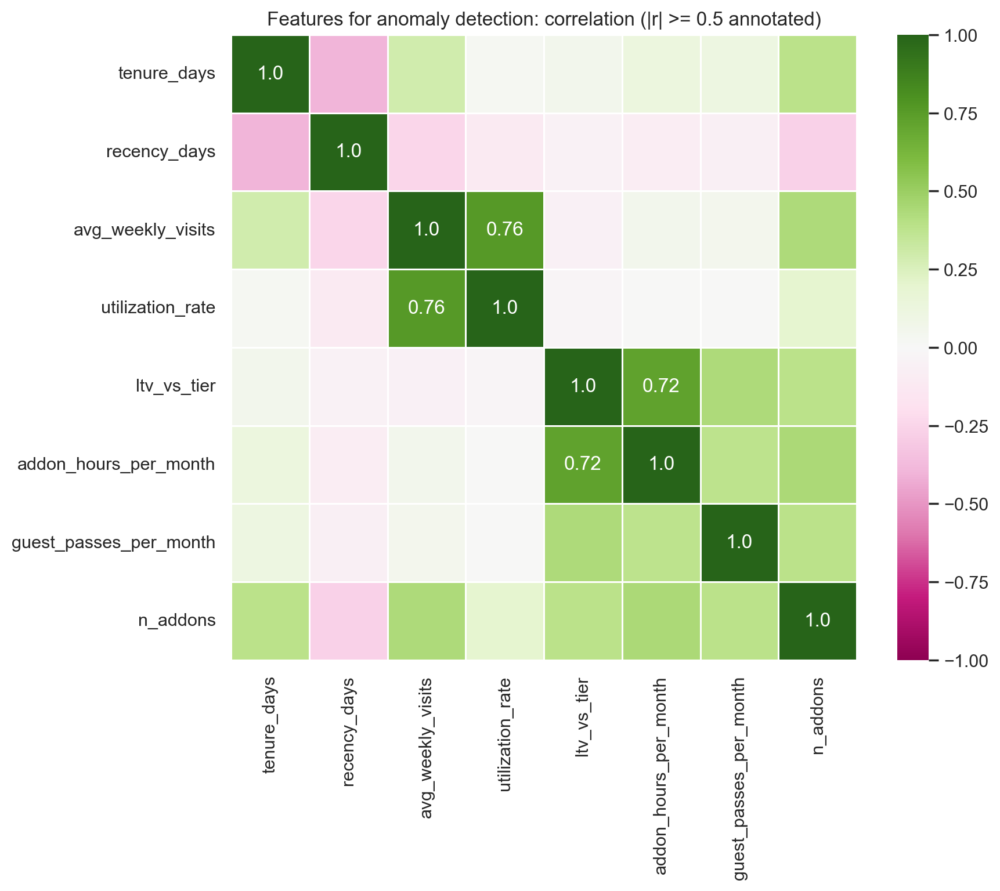

In [164]:
# Redundancy check: annotate only the strong correlations, with the same heatmap habit as lab04
anomaly_corr = anomaly_data.corr().round(2)

plt.figure(figsize=(9, 7))
sns.heatmap(anomaly_corr, center=0, cmap="PiYG", vmin=-1, vmax=1,
            annot=np.where(np.abs(anomaly_corr) >= 0.5, anomaly_corr.values, ""), fmt="s",
            square=True, linewidths=.5)
plt.title("Features for anomaly detection: correlation (|r| >= 0.5 annotated)")
plt.show()

In [182]:
# Strongly skewed features are compressed first, otherwise their tail decides every distance.
# Then each feature is standardized, because these methods compare features on the same scale.
skewness = anomaly_data.skew()
skewed_features = list(skewness[skewness > 2].index)
print("Skewness:", skewness.round(2).to_dict())
print("Log-transformed:", skewed_features)


def prepare_for_detection(features):
    prepared = features.copy()
    prepared[skewed_features] = np.log1p(prepared[skewed_features])
    return prepared


anomaly_scaler = StandardScaler()
scaled_anomaly_data = pd.DataFrame(anomaly_scaler.fit_transform(prepare_for_detection(anomaly_data)),
                                   index=anomaly_data.index, columns=anomaly_data.columns)
scaled_anomaly_data.describe().loc[["mean", "std", "max"]].round(2)

Skewness: {'tenure_days': 0.66, 'recency_days': 0.84, 'avg_weekly_visits': 0.92, 'utilization_rate': -0.04, 'ltv_vs_tier': 6.05, 'addon_hours_per_month': 7.15, 'guest_passes_per_month': 6.35, 'n_addons': 0.77}
Log-transformed: ['ltv_vs_tier', 'addon_hours_per_month', 'guest_passes_per_month']


,tenure_days,recency_days,avg_weekly_visits,utilization_rate,ltv_vs_tier,addon_hours_per_month,guest_passes_per_month,n_addons
mean,0.00,0.0,0.0,-0.00,-0.0,-0.00,-0.00,0.00
std,1.00,1.0,1.0,1.00,1.0,1.00,1.00,1.00
max,2.13,2.7,4.1,1.54,9.5,5.68,7.31,4.11


### 25.2 Three methods

The Mahalanobis distance is the optional method suggested in our plan, and it helps us interpret the other two:

| Method | How it decides | What it looks for |
|---|---|---|
| **Isolation Forest** | Random splits isolate a member; few splits means unusual | Members far from everyone (global) |
| **Local Outlier Factor (LOF)** | Compares the density around a member with that of its 20 nearest neighbours | Members in a sparser area than their neighbours (local) |
| **Mahalanobis distance** | Distance to the centre, corrected for the correlations between features | Members far from the centre, or combinations that the correlations make unusual |

None of the correlations in the heatmap reach a 0.9 threshold (the highest observed is 0.76), so we retain all features for the analysis.

In [166]:
# Share of members treated as anomalies. Both methods need this number, so its effect is tested below
anomaly_share = 0.01

iso_forest = IsolationForest(n_estimators=300, contamination=anomaly_share, random_state=42).fit(scaled_anomaly_data)
iso_flag = pd.Series(iso_forest.predict(scaled_anomaly_data) == -1, index=scaled_anomaly_data.index)
iso_score = pd.Series(-iso_forest.score_samples(scaled_anomaly_data), index=scaled_anomaly_data.index)     # higher = more unusual

lof = LocalOutlierFactor(n_neighbors=20, contamination=anomaly_share)
lof_flag = pd.Series(lof.fit_predict(scaled_anomaly_data) == -1, index=scaled_anomaly_data.index)
lof_score = pd.Series(-lof.negative_outlier_factor_, index=scaled_anomaly_data.index)                      # higher = more unusual

# Mahalanobis distance: how far a member is from the centre, taking the correlations between features into account
anomaly_cov_inv = np.linalg.inv(np.cov(scaled_anomaly_data.values, rowvar=False))


def mahalanobis_distance(scaled):
    centred = scaled.values - scaled_anomaly_data.values.mean(axis=0)
    return pd.Series(np.sqrt(np.einsum("ij,jk,ik->i", centred, anomaly_cov_inv, centred)), index=scaled.index)


maha_score = mahalanobis_distance(scaled_anomaly_data)
maha_flag = maha_score >= maha_score.quantile(1 - anomaly_share)

flags = pd.DataFrame({"Isolation Forest": iso_flag, "LOF": lof_flag, "Mahalanobis": maha_flag})
print("Members flagged:", flags.sum().to_dict())

# How many members do the methods flag in common? (diagonal = members flagged by each method)
flags.astype(int).T.dot(flags.astype(int))

Members flagged: {'Isolation Forest': 152, 'LOF': 152, 'Mahalanobis': 152}


,Isolation Forest,LOF,Mahalanobis
Isolation Forest,152,2,67
LOF,2,152,13
Mahalanobis,67,13,152


In [181]:
# Do the methods rank the members in the same way? Spearman compares ranks 
pd.DataFrame({"Isolation Forest": iso_score, "LOF": lof_score, "Mahalanobis": maha_score}).corr(method="spearman").round(2)

,Isolation Forest,LOF,Mahalanobis
Isolation Forest,1.00,0.22,0.86
LOF,0.22,1.00,0.19
Mahalanobis,0.86,0.19,1.00


**The methods barely agree.** Isolation Forest and LOF flag only 2 members in common, and their rankings are weakly related (Spearman
0.22). Isolation Forest is much closer to the Mahalanobis distance (0.86). So they do not confirm each other: they measure different
things. Before trusting either one, we test how much the results depend on their settings.

### 25.3 Stability

In [168]:
# 1. Does the result depend on the random seed (Isolation Forest) or on the number of neighbours (LOF)?
stability = {}
for seed in [1, 2, 3]:
    other = IsolationForest(n_estimators=300, contamination=anomaly_share, random_state=seed).fit(scaled_anomaly_data)
    same = (pd.Series(other.predict(scaled_anomaly_data) == -1, index=scaled_anomaly_data.index) & iso_flag).sum()
    stability[f"Isolation Forest, seed {seed}"] = same / iso_flag.sum() * 100
for neighbours in [10, 50, 100]:
    other = LocalOutlierFactor(n_neighbors=neighbours, contamination=anomaly_share).fit_predict(scaled_anomaly_data)
    same = (pd.Series(other == -1, index=scaled_anomaly_data.index) & lof_flag).sum()
    stability[f"LOF, {neighbours} neighbours"] = same / lof_flag.sum() * 100
pd.Series(stability, name="% of the flagged members found again").round(1).to_frame()

,% of the flagged members found again
"Isolation Forest, seed 1",87.5
"Isolation Forest, seed 2",87.5
"Isolation Forest, seed 3",88.2
"LOF, 10 neighbours",69.1
"LOF, 50 neighbours",67.1
"LOF, 100 neighbours",51.3


In [180]:
# 2. Does the agreement between the methods depend on the share of anomalies?
share_check = {}
for share in [0.005, 0.01, 0.02, 0.05]:
    iso_top = iso_score >= iso_score.quantile(1 - share)
    lof_top = lof_score >= lof_score.quantile(1 - share)
    share_check[share] = {"members per method": iso_top.sum(), "flagged by both": (iso_top & lof_top).sum(),
                          "% in common": (iso_top & lof_top).sum() / iso_top.sum() * 100}
pd.DataFrame(share_check).T.round(1).rename_axis("share of anomalies")

,members per method,flagged by both,% in common
share of anomalies,,,
0.005,76.0,1.0,1.3
0.010,152.0,2.0,1.3
0.020,303.0,5.0,1.7
0.050,757.0,59.0,7.8


- **Isolation Forest is stable:** with a different random seed, about 88% of its members are found again.
- **LOF is sensitive:** with another number of neighbours, only 51% to 69% of its members are found again.
- **The disagreement is not caused by our 1%:** the two methods have at most 7.8% of their members in common, even at the 5% limit of the rule of thumb.



### 25.4 Who are the flagged members?

In [170]:
anomaly_group = pd.Series("Not flagged", index=df_clean.index, name="flagged by")
anomaly_group[iso_flag & ~lof_flag] = "Isolation Forest only"
anomaly_group[lof_flag & ~iso_flag] = "LOF only"
anomaly_group[iso_flag & lof_flag] = "Both"
group_order = ["Not flagged", "Isolation Forest only", "LOF only", "Both"]

group_summary = pd.DataFrame({
    "members": anomaly_group.value_counts(),
    "% of members": anomaly_group.value_counts(normalize=True) * 100,
    "% of revenue": df_clean["lifetime_value"].groupby(anomaly_group).sum() / df_clean["lifetime_value"].sum() * 100,
    "% also flagged by Mahalanobis": maha_flag.groupby(anomaly_group).mean() * 100,
    "% still active": df_clean["membership_end"].isna().groupby(anomaly_group).mean() * 100,
    "% with imputed revenue": df_clean["ltv_imputed"].groupby(anomaly_group).mean() * 100,
}).round(2).reindex(group_order)
group_summary

,members,% of members,% of revenue,% also flagged by Mahalanobis,% still active,% with imputed revenue
flagged by,,,,,,
Not flagged,14806,98.00,95.98,0.49,25.56,18.60
Isolation Forest only,150,0.99,2.62,44.00,20.00,3.33
LOF only,150,0.99,1.34,8.00,57.33,18.67
Both,2,0.01,0.05,50.00,50.00,0.00


In [171]:
# Typical member of each group
anomaly_data.groupby(anomaly_group).median().reindex(group_order).round(2).T

flagged by,Not flagged,Isolation Forest only,LOF only,Both
tenure_days,279.00,438.00,313.00,582.50
recency_days,240.00,218.50,178.50,8.50
avg_weekly_visits,1.48,0.99,0.88,2.50
utilization_rate,0.52,0.40,0.12,0.45
ltv_vs_tier,1.00,4.09,1.00,4.26
addon_hours_per_month,0.00,18.73,0.00,84.05
guest_passes_per_month,0.00,5.53,0.00,1.88
n_addons,1.00,5.00,1.00,5.50


In [172]:
# Plan tiers inside each group
pd.crosstab(anomaly_group, df_clean["plan_tier"], normalize="index").reindex(group_order).mul(100).round(1)

plan_tier,dedicated_desk,flex,full_time,hot_desk,private_office
flagged by,,,,,
Not flagged,10.2,35.5,16.1,33.6,4.5
Isolation Forest only,2.7,29.3,14.7,52.7,0.7
LOF only,8.0,22.0,17.3,38.0,14.7
Both,0.0,0.0,50.0,0.0,50.0


In [173]:
# What makes the flagged members unusual? The feature where each member is furthest from the average
pd.DataFrame({
    "Isolation Forest": scaled_anomaly_data[iso_flag].abs().idxmax(axis=1).value_counts(),
    "LOF": scaled_anomaly_data[lof_flag].abs().idxmax(axis=1).value_counts(),
}).fillna(0).astype(int).sort_values("Isolation Forest", ascending=False).rename_axis("most extreme feature")

,Isolation Forest,LOF
most extreme feature,,
ltv_vs_tier,94,7
guest_passes_per_month,54,0
addon_hours_per_month,2,2
n_addons,2,12
avg_weekly_visits,0,14
recency_days,0,14
tenure_days,0,29
utilization_rate,0,74


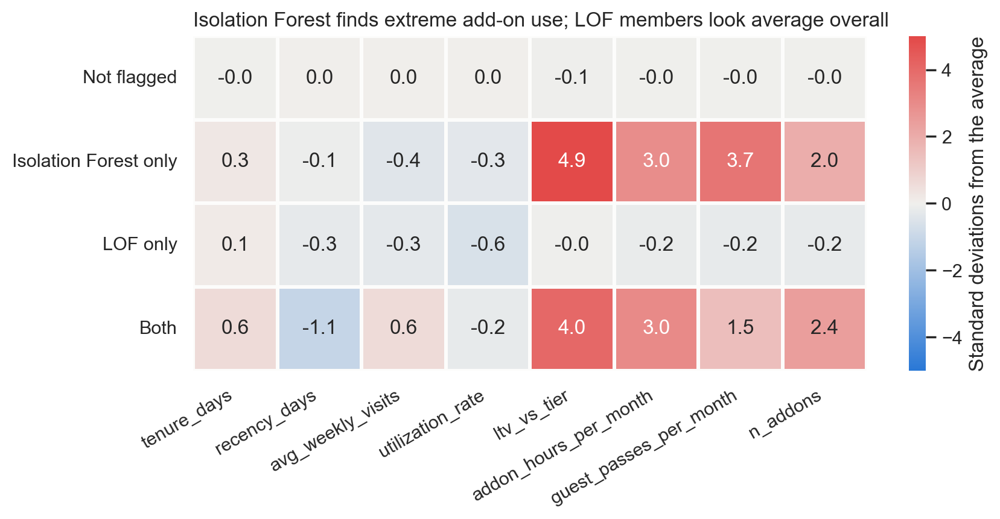

In [174]:
# Average of each standardized feature per group: 0 = like the average member
blue_grey_red = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.figure(figsize=(9, 3.6))
sns.heatmap(scaled_anomaly_data.groupby(anomaly_group).mean().reindex(group_order), center=0, vmin=-5, vmax=5,
            cmap=blue_grey_red, annot=True, fmt=".1f", linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "Standard deviations from the average"})
plt.title("Isolation Forest finds extreme add-on use; LOF members look average overall", loc="left")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=30, ha="right")
plt.show()

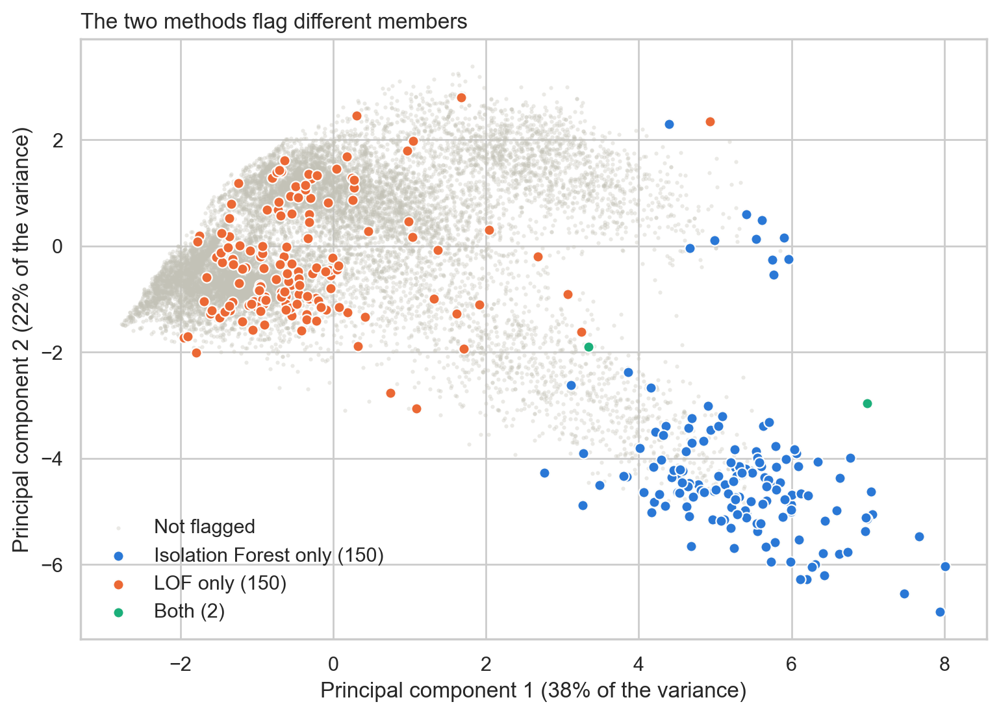

In [175]:
# Two-dimensional view with PCA, only to see where the flagged members are
anomaly_pca = PCA(n_components=2).fit(scaled_anomaly_data)
pca_coordinates = pd.DataFrame(anomaly_pca.transform(scaled_anomaly_data), index=scaled_anomaly_data.index, columns=["pc1", "pc2"])
explained = anomaly_pca.explained_variance_ratio_ * 100

group_style = {"Isolation Forest only": "#2a78d6", "LOF only": "#eb6834", "Both": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 6))
not_flagged = anomaly_group == "Not flagged"
ax.scatter(pca_coordinates.loc[not_flagged, "pc1"], pca_coordinates.loc[not_flagged, "pc2"],
           s=5, color="#c3c2b7", alpha=0.35, linewidths=0, label="Not flagged")
for group, colour in group_style.items():
    selected = anomaly_group == group
    ax.scatter(pca_coordinates.loc[selected, "pc1"], pca_coordinates.loc[selected, "pc2"],
               s=34, color=colour, edgecolor="#fcfcfb", linewidths=0.8, label=f"{group} ({selected.sum()})")
ax.set_xlabel(f"Principal component 1 ({explained[0]:.0f}% of the variance)")
ax.set_ylabel(f"Principal component 2 ({explained[1]:.0f}% of the variance)")
ax.set_title("The two methods flag different members", loc="left")
ax.legend(frameon=False, loc="best")
plt.show()

- **Isolation Forest finds extreme add-on users.** The typical member pays 4.1 times the plan, uses 5 add-ons and about 19 room hours a month. They are 1% of the members and 2.6% of the revenue. The revenue supports the usage, so they look like real customers. In the PCA view they form a compact group, which also points to a real type of member rather than to random errors.
- **LOF finds nothing extreme.** Its members look average overall, except for low use (median utilization of 0.12), and 57% of them are still active. `private_office` appears three times more often than in the rest of the data (14.7% vs 4.5%), so LOF may partly be reacting to the small size of that tier.
- **The 2 members flagged by both** look like the Isolation Forest group, and are too few to describe a pattern of their own.
- **Blind spot:** only 3.3% of the Isolation Forest members have imputed revenue, against 18.6% of the others, because imputed revenue is exactly the plan price and can never look extreme.

### 25.5 Do the methods find the known problems?

Section 8.2 removed 9 rows with `meeting_room_hours` above 1,000 that could not be repaired. They were not used to fit the methods, so
they are a fair test.

In [176]:
# Same features, same preparation and the same limits as above, applied to the rows removed in 8.2 (not used for fitting)
removed_features = anomaly_features(removed_outliers).fillna(anomaly_data.median())
removed_scaled = pd.DataFrame(anomaly_scaler.transform(prepare_for_detection(removed_features)),
                              index=removed_features.index, columns=removed_features.columns)

lof_novelty = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(scaled_anomaly_data.values)
lof_limit = np.quantile(-lof_novelty.negative_outlier_factor_, 1 - anomaly_share)

removed_check = pd.DataFrame({
    "Isolation Forest": -iso_forest.score_samples(removed_scaled) >= iso_score[iso_flag].min(),
    "LOF": -lof_novelty.score_samples(removed_scaled.values) >= lof_limit,
    "Mahalanobis": mahalanobis_distance(removed_scaled) >= maha_score[maha_flag].min(),
}, index=removed_scaled.index)

print("Rows flagged by each method:", removed_check.sum().to_dict(), "of", len(removed_check))
print("Rows flagged by at least one method:", removed_check.any(axis=1).sum())
removed_check.insert(0, "meeting_room_hours", removed_outliers["meeting_room_hours"])
removed_check.sort_values("meeting_room_hours")

Rows flagged by each method: {'Isolation Forest': 4, 'LOF': 8, 'Mahalanobis': 7} of 9
Rows flagged by at least one method: 9


,meeting_room_hours,Isolation Forest,LOF,Mahalanobis
2989,1439.0,True,False,False
12003,1728.0,False,True,True
14058,1746.0,True,True,True
6680,1770.0,True,True,False
9908,3276.0,False,True,True
14555,4284.0,False,True,True
6246,8928.0,True,True,True
4776,12372.0,False,True,True
14553,41220.0,False,True,True


**No single method is enough, but together they cover every case:** Isolation Forest flags 4 of the 9 rows, LOF 8 and the Mahalanobis distance 7, and each row is flagged by at least one. Isolation Forest misses the largest value (41,220 hours): it only splits inside the range it saw when it was fitted, so a value far beyond that range does not count as more unusual. This supports the rule-based removal of section 8.2, and it is a reason not to rely on Isolation Forest alone.

### 25.6 Can they distort clustering?

Our plan assumed that K-Means is sensitive to outliers. We test it directly: we fit K-Means with and without the flagged members, or with a lower weight, and compare the result for all the other members. An agreement of 1 means they get exactly the same clusters.

In [177]:
# K-Means is used here only as a test: this is not the segmentation, which belongs to Deliverable 2
n_test_clusters = 5     # the number of groups expected in the behaviour analysis


def kmeans_labels(keep, weights=None):
    model = KMeans(n_clusters=n_test_clusters, n_init=10, random_state=42)
    model.fit(scaled_anomaly_data[keep], sample_weight=None if weights is None else weights[keep])
    return pd.Series(model.predict(scaled_anomaly_data), index=scaled_anomaly_data.index), model


everyone = pd.Series(True, index=scaled_anomaly_data.index)
labels_all, model_all = kmeans_labels(everyone)

downweighted = pd.Series(1.0, index=scaled_anomaly_data.index)
downweighted[iso_flag | lof_flag] = 0.1

scenarios = {
    "Exclude Isolation Forest": kmeans_labels(~iso_flag),
    "Exclude LOF": kmeans_labels(~lof_flag),
    "Exclude both methods' members": kmeans_labels(~(iso_flag | lof_flag)),
    "Downweight both methods' members (0.1)": kmeans_labels(everyone, downweighted),
}

distortion = {}
for name, (labels, model) in scenarios.items():
    usual_members = ~(iso_flag | lof_flag)
    # how far did each centre move? each centre is compared with the closest centre of the run with everyone
    distances = np.linalg.norm(model_all.cluster_centers_[:, None, :] - model.cluster_centers_[None, :, :], axis=2)
    distortion[name] = {
        "agreement with all members (adjusted Rand)": adjusted_rand_score(labels_all[usual_members], labels[usual_members]),
        "largest move of a centre (std deviations)": distances.min(axis=1).max(),
    }
pd.DataFrame(distortion).T.round(3)

,agreement with all members (adjusted Rand),largest move of a centre (std deviations)
Exclude Isolation Forest,0.982,0.723
Exclude LOF,0.997,0.030
Exclude both methods' members,0.979,0.718
Downweight both methods' members (0.1),0.983,0.653


In [178]:
# Which cluster of the run with everyone do the flagged members fall in? (% of each group, and size of each cluster)
cluster_table = pd.crosstab(anomaly_group, labels_all, normalize="index").reindex(group_order).mul(100).round(1)
cluster_table.loc["Cluster size"] = labels_all.value_counts().sort_index()
cluster_table.loc["Average ltv_vs_tier"] = anomaly_data["ltv_vs_tier"].groupby(labels_all).mean().round(2)
cluster_table.loc["Average addon_hours_per_month"] = anomaly_data["addon_hours_per_month"].groupby(labels_all).mean().round(2)
cluster_table.rename_axis(columns="test cluster")

test cluster,0,1,2,3,4
flagged by,,,,,
Not flagged,12.80,32.90,6.40,32.70,15.30
Isolation Forest only,0.00,0.00,94.00,0.00,6.00
LOF only,41.30,23.30,2.70,29.30,3.30
Both,0.00,0.00,100.00,0.00,0.00
Cluster size,1950.00,4903.00,1094.00,4886.00,2275.00
Average ltv_vs_tier,0.97,1.01,2.60,0.99,1.12
Average addon_hours_per_month,0.26,0.43,13.33,0.26,3.24


**A second test: the unusual entries of 2023.** The members who joined between January and September 2023 look different from every other cohort: almost all of them have already left and none has a premium plan (see the cohorts in section 14.5). We cannot prove that this is an error, so we do not change the data, but we can measure whether these members affect the clusters.

In [179]:
unusual_entries = df_clean["membership_start"].between("2023-01-01", "2023-09-30")
print("Members who joined between January and September 2023:", unusual_entries.sum(),
      f"({unusual_entries.mean() * 100:.1f}% of the members)")
print(f"% still active: {df_clean.loc[unusual_entries, 'membership_end'].isna().mean() * 100:.1f}"
      f" | all other members: {df_clean.loc[~unusual_entries, 'membership_end'].isna().mean() * 100:.1f}")

labels_without_entries, model_without_entries = kmeans_labels(~unusual_entries)
centre_distances = np.linalg.norm(model_all.cluster_centers_[:, None, :] - model_without_entries.cluster_centers_[None, :, :], axis=2)
print("Agreement with all members, for the other members (adjusted Rand):",
      round(adjusted_rand_score(labels_all[~unusual_entries], labels_without_entries[~unusual_entries]), 3))
print("Largest move of a centre (std deviations):", round(centre_distances.min(axis=1).max(), 3))

# comparison: remove a random group of the same size, so that we know how much of this is just K-Means instability
random_agreement, random_move = [], []
for seed in range(5):
    random_out = pd.Series(False, index=df_clean.index)
    random_out[df_clean.sample(unusual_entries.sum(), random_state=seed).index] = True
    labels_random, model_random = kmeans_labels(~random_out)
    random_agreement.append(adjusted_rand_score(labels_all[~random_out], labels_random[~random_out]))
    random_move.append(np.linalg.norm(model_all.cluster_centers_[:, None, :] - model_random.cluster_centers_[None, :, :], axis=2).min(axis=1).max())
print("Random group of the same size, 5 repetitions | agreement:", np.round(random_agreement, 3), "| largest move:", np.round(random_move, 3))

# which test cluster do they fall in, compared with the other members?
pd.crosstab(unusual_entries.map({True: "Joined Jan-Sep 2023", False: "Other members"}), labels_all, normalize="index").mul(100).round(1).rename_axis(index="", columns="test cluster")

Members who joined between January and September 2023: 1558 (10.3% of the members)
% still active: 3.5 | all other members: 28.4
Agreement with all members, for the other members (adjusted Rand): 0.823
Largest move of a centre (std deviations): 0.768
Random group of the same size, 5 repetitions | agreement: [0.998 0.995 0.992 0.993 0.997] | largest move: [0.033 0.072 0.049 0.139 0.036]


test cluster,0,1,2,3,4
,,,,,
Joined Jan-Sep 2023,0.0,26.3,3.3,69.2,1.2
Other members,14.4,33.2,7.7,28.1,16.7


**The effect is real, and it is larger than that of the anomalies.** Removing a random group of the same size barely changes the clusters (agreement of 0.99 or more), but removing these members lowers the agreement to 0.82 and moves a centre by about 0.77 standard deviations. 69% of them fall in a single test cluster, against 28% of the other members, so they can shape a cluster on their own.

We keep them, because there is no proof of an error and they are 10.3% of the members. But if this pattern comes from the way the data was built, a cluster could partly reflect that instead of real behaviour, so Deliverable 2 should run the clustering with and without them and the pattern should be confirmed with ACDC.


- **The effect is small and concentrated.** For the other members, the clusters barely change in any scenario (agreement of 0.98 or more). The largest move of a centre is about 0.7 standard deviations with the Isolation Forest members out, and only 0.03 with the LOF members out.
- **They do not create a false cluster.** 94% of the Isolation Forest members fall in one test cluster of about 1,100 members with high add-on use, and they pull its centre further from the rest. So the risk is a distorted description of that cluster, not a false one.
- **Downweighting is almost as effective as excluding** (a move of 0.65 vs 0.72), and it keeps these members in the analysis.

### 25.7 Recommendation for Deliverable 2

| Members | Decision | Why |
|---|---|---|
| **Flagged by Isolation Forest** (152, 1%) | **Downweight when fitting, and analyse separately** | Real and valuable customers that pull one centre. Fit with a low weight, assign them afterwards, and describe them as a niche of heavy add-on users |
| **Flagged by LOF only** (150, 1%) | **Keep, no special treatment** | Nothing extreme, unstable results and no effect on the clusters |
| **Joined between January and September 2023** (1,558, 10.3%) | **Keep, but run the clustering with and without them** | No proof of an error, but they clearly affect the clusters (25.6) |
| **The 9 rows removed in 8.2** | **Keep excluded** | Whole-number values that could not be repaired, and all flagged by at least one method |

**We do not recommend excluding any further members:** the test does not show a need for it, and it would remove 2.6% of the revenue and a real group of customers.

**Limits of this test:** it uses 5 clusters and these 8 features. Deliverable 2 should repeat it with the final features and number of clusters, using the same weight of 0.1 only as a starting point.

### 25.8 Documentation of the bonus

**Why we chose it.** It follows directly from the data-quality work, needs no external data and protects Deliverable 2, since distance-based clustering can be affected by unusual members.

**What it adds.** It looks at the features together, which rules cannot do. It also turns a general concern into a specific decision for each type of member, and it identifies a niche of heavy add-on users.

**Challenges and how we solved them:**
- **The methods disagree.** We did not force a consensus: we profiled each group and tested its effect, and the decision depends on what each group is.
- **Very skewed features would dominate the distances.** We applied a log transformation before standard scaling.
- **Rates are unstable for very short memberships.** We count at least one month when calculating them.
- **Both methods need a share of anomalies, and it is our choice.** We used 1% and tested values up to the 5% rule.
- **LOF depends on the number of neighbours.** We measured this, and it is one of the reasons we do not act on LOF alone.
- **Imputed revenue cannot look extreme.** We report this as a blind spot, so some heavy users with imputed revenue may be missed.